In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All"
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [ ]:
import os

BASE_DIR = "/kaggle/working/CA_CSDL_Q1"

folders = [
    "data",
    "baseline",
    "checkpoints",
    "lora_adapter",
    "results",
    "graphs",
    "experiment_logs",
    "models",
    "evaluation",
    "ablation_studies"
]

for folder in folders:
    os.makedirs(
        os.path.join(BASE_DIR, folder),
        exist_ok=True
    )

print("CA-CSDL project structure created!")

for root, dirs, files in os.walk(BASE_DIR):
    level = root.replace(BASE_DIR, "").count(os.sep)
    indent = "    " * level
    print(f"{indent}{os.path.basename(root)}/")

CA-CSDL project structure created!
CA_CSDL_Q1/
    data/
    lora_adapter/
    checkpoints/
    evaluation/
    graphs/
    baseline/
    ablation_studies/
    experiment_logs/
    models/
    results/


In [ ]:
import json
import os

CONFIG = {
    "project": "CA-CSDL",
    "title": (
        "Confidence-Aware and Cost-Sensitive Decision Learning "
        "for Efficient Intent Classification Using Quantized "
        "Large Language Models"
    ),
    "model": "Qwen/Qwen3.5-4B",
    "quantization": "4-bit",
    "adapter": "Fresh LoRA",
    "dataset": "CLINC150",
    "num_intents": 150,
    "epochs": 2,
    "seed": 42,
    "max_sequence_length": 512,
    "evaluation_metrics": [
        "accuracy",
        "macro_f1",
        "coverage",
        "selective_risk",
        "ECE",
        "Brier_score",
        "latency",
        "GPU_memory"
    ]
}

config_path = os.path.join(
    BASE_DIR, "experiment_config.json"
)

with open(config_path, "w") as f:
    json.dump(CONFIG, f, indent=4)

print("Research configuration saved:", config_path)

Research configuration saved: /kaggle/working/CA_CSDL_Q1/experiment_config.json


In [ ]:
import pandas as pd

columns = [
    "Experiment_ID",
    "Model",
    "Dataset",
    "Training_Method",
    "Epochs",
    "Accuracy",
    "Macro_F1",
    "ECE",
    "Brier_Score",
    "Coverage",
    "Selective_Risk",
    "Latency_ms",
    "GPU_Memory_GB"
]

experiment_df = pd.DataFrame(columns=columns)

experiment_df.to_csv(
    os.path.join(BASE_DIR, "experiment_logs",
                 "experiment_results.csv"),
    index=False
)

print("Experiment tracking file created.")

Experiment tracking file created.


In [ ]:
from pathlib import Path

for p in sorted(Path(BASE_DIR).rglob("*")):
    if p.is_dir():
        print("📁", p.relative_to(BASE_DIR))
    else:
        print("📄", p.relative_to(BASE_DIR))

📁 ablation_studies
📁 baseline
📁 checkpoints
📁 data
📁 evaluation
📄 experiment_config.json
📁 experiment_logs
📄 experiment_logs/experiment_results.csv
📁 graphs
📁 lora_adapter
📁 models
📁 results


In [ ]:
import torch

print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print(
        "GPU memory:",
        round(
            torch.cuda.get_device_properties(0).total_memory
            / 1024**3, 2
        ),
        "GB"
    )
else:
    print("Currently running on CPU.")

CUDA available: True
GPU: Tesla T4
GPU memory: 14.56 GB


In [ ]:
%pip install -q unsloth
%pip install -q datasets scikit-learn pandas matplotlib seaborn

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


In [ ]:
import torch
import transformers
import datasets
import peft

print("PyTorch:", torch.__version__)
print("Transformers:", transformers.__version__)
print("Datasets:", datasets.__version__)
print("PEFT:", peft.__version__)

print("CUDA:", torch.cuda.is_available())
print("GPU:", torch.cuda.get_device_name(0))

assert torch.cuda.is_available(), "GPU unavailable!"

PyTorch: 2.11.0+cu130
Transformers: 5.17.0
Datasets: 4.8.5
PEFT: 0.21.2
CUDA: True
GPU: Tesla T4


In [ ]:
from datasets import load_dataset

dataset = load_dataset("DeepPavlov/clinc150")

print(dataset)

for split in dataset:
    print(
        split,
        ":", len(dataset[split]),
        "examples"
    )

README.md:   0%|          | 0.00/4.93k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  344kB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 70.8kB            

data/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  128kB            

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/15200 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/3100 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/5500 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['utterance', 'label'],
        num_rows: 15200
    })
    validation: Dataset({
        features: ['utterance', 'label'],
        num_rows: 3100
    })
    test: Dataset({
        features: ['utterance', 'label'],
        num_rows: 5500
    })
})
train : 15200 examples
validation : 3100 examples
test : 5500 examples


In [ ]:
print(dataset["train"].features)
print(dataset["train"][0])

{'utterance': Value('string'), 'label': Value('int64')}
{'utterance': 'can i make a reservation for redrobin', 'label': 0}


In [ ]:
import os
import json

# Recreate project directory
BASE_DIR = "/kaggle/working/CA_CSDL_Q1"

os.makedirs(os.path.join(BASE_DIR, "data"), exist_ok=True)

# Recreate metadata using the existing dataset variables
metadata = {
    "dataset": "DeepPavlov/clinc150",
    "configuration": "plus",
    "train": len(dataset["train"]),
    "validation": len(dataset["validation"]),
    "test": len(dataset["test"]),
}

# Safely obtain label names
label_feature = dataset["train"].features["label"]

if hasattr(label_feature, "names"):
    metadata["label_names"] = label_feature.names
else:
    metadata["label_names"] = []

metadata_path = os.path.join(
    BASE_DIR, "data", "dataset_metadata.json"
)

with open(metadata_path, "w") as f:
    json.dump(metadata, f, indent=4)

print("Dataset metadata saved successfully!")
print(metadata)

Dataset metadata saved successfully!
{'dataset': 'DeepPavlov/clinc150', 'configuration': 'plus', 'train': 15200, 'validation': 3100, 'test': 5500, 'label_names': []}


In [ ]:
from collections import Counter

print("TRAIN FEATURES:")
print(dataset["train"].features)

print("\nTRAIN COLUMNS:")
print(dataset["train"].column_names)

print("\nFIRST THREE TRAINING EXAMPLES:")
for i in range(3):
    print(dataset["train"][i])

print("\nLABEL DISTRIBUTION:")

for column in dataset["train"].column_names:
    values = dataset["train"][column]

    if column.lower() in ["label", "intent", "category"]:
        counts = Counter(values)
        print("Label column:", column)
        print("Unique labels:", len(counts))
        print("Sample labels:", counts.most_common(15))

TRAIN FEATURES:
{'utterance': Value('string'), 'label': Value('int64')}

TRAIN COLUMNS:
['utterance', 'label']

FIRST THREE TRAINING EXAMPLES:
{'utterance': 'can i make a reservation for redrobin', 'label': 0}
{'utterance': 'is it possible to make a reservation at redrobin', 'label': 0}
{'utterance': 'does redrobin take reservations', 'label': 0}

LABEL DISTRIBUTION:
Label column: label
Unique labels: 151
Sample labels: [(None, 200), (0, 100), (1, 100), (2, 100), (3, 100), (4, 100), (5, 100), (6, 100), (7, 100), (8, 100), (9, 100), (10, 100), (11, 100), (12, 100), (13, 100)]


In [ ]:
for split in ["train", "validation", "test"]:
    print("\n", split.upper())

    for column in dataset[split].column_names:
        if column.lower() in ["label", "intent", "category"]:
            values = dataset[split][column]
            print(
                "Column:", column,
                "| Unique labels:", len(set(values))
            )


 TRAIN
Column: label | Unique labels: 151

 VALIDATION
Column: label | Unique labels: 151

 TEST
Column: label | Unique labels: 151


In [ ]:
from collections import Counter

for split in ["train", "validation", "test"]:

    labels = dataset[split]["label"]

    valid_labels = [x for x in labels if x is not None]
    missing_count = sum(x is None for x in labels)

    counts = Counter(valid_labels)

    print("\n==========", split.upper(), "==========")
    print("Total examples:", len(labels))
    print("Valid labels:", len(valid_labels))
    print("Missing labels:", missing_count)
    print("Unique valid labels:", len(counts))
    print("Minimum label:", min(counts) if counts else None)
    print("Maximum label:", max(counts) if counts else None)
    print("Label distribution:", counts)


========== TRAIN ==========
Total examples: 15200
Valid labels: 15000
Missing labels: 200
Unique valid labels: 150
Minimum label: 0
Maximum label: 149
Label distribution: Counter({0: 100, 1: 100, 2: 100, 3: 100, 4: 100, 5: 100, 6: 100, 7: 100, 8: 100, 9: 100, 10: 100, 11: 100, 12: 100, 13: 100, 14: 100, 15: 100, 16: 100, 17: 100, 18: 100, 19: 100, 20: 100, 21: 100, 22: 100, 23: 100, 24: 100, 25: 100, 26: 100, 27: 100, 28: 100, 29: 100, 30: 100, 31: 100, 32: 100, 33: 100, 34: 100, 35: 100, 36: 100, 37: 100, 38: 100, 39: 100, 40: 100, 41: 100, 42: 100, 43: 100, 44: 100, 45: 100, 46: 100, 47: 100, 48: 100, 49: 100, 50: 100, 51: 100, 52: 100, 53: 100, 54: 100, 55: 100, 56: 100, 57: 100, 58: 100, 59: 100, 60: 100, 61: 100, 62: 100, 63: 100, 64: 100, 65: 100, 66: 100, 67: 100, 68: 100, 69: 100, 70: 100, 71: 100, 72: 100, 73: 100, 74: 100, 75: 100, 76: 100, 77: 100, 78: 100, 79: 100, 80: 100, 81: 100, 82: 100, 83: 100, 84: 100, 85: 100, 86: 100, 87: 100, 88: 100, 89: 100, 90: 100, 91: 100, 9

In [ ]:
print("Dataset information:")
print(dataset)

print("\nLabel feature:")
print(dataset["train"].features["label"])

print("\nDataset metadata:")
print(dataset["train"].info)

Dataset information:
DatasetDict({
    train: Dataset({
        features: ['utterance', 'label'],
        num_rows: 15200
    })
    validation: Dataset({
        features: ['utterance', 'label'],
        num_rows: 3100
    })
    test: Dataset({
        features: ['utterance', 'label'],
        num_rows: 5500
    })
})

Label feature:
Value('int64')

Dataset metadata:
DatasetInfo(features={'utterance': Value('string'), 'label': Value('int64')}, builder_name='parquet', dataset_name='clinc150', config_name='default', version=0.0.0, splits={'train': SplitInfo(name='train', num_bytes=857605, num_examples=15200, dataset_name='clinc150'), 'validation': SplitInfo(name='validation', num_bytes=160686, num_examples=3100, dataset_name='clinc150'), 'test': SplitInfo(name='test', num_bytes=287654, num_examples=5500, dataset_name='clinc150')}, download_size=542584, dataset_size=1305945, size_in_bytes=1848529)


In [ ]:
for split in ["train", "validation", "test"]:

    print("\n", split.upper())

    rows = dataset[split].filter(
        lambda x: x["label"] is None
    )

    print("Missing-label rows:", len(rows))

    if len(rows) > 0:
        print(rows[:5])


 TRAIN


Filter:   0%|          | 0/15200 [00:00<?, ? examples/s]

Missing-label rows: 200
{'utterance': ['how much is an overdraft fee for bank', 'why are exponents preformed before multiplication in the order of operations', 'what size wipers does this car take', 'where is the dipstick', 'how much is 1 share of aapl'], 'label': [None, None, None, None, None]}

 VALIDATION


Filter:   0%|          | 0/3100 [00:00<?, ? examples/s]

Missing-label rows: 100
{'utterance': ['set a warning for when my bank account starts running low', 'a show on broadway', 'who has the best record in the nfl', 'how do i find the area of a circle', 'how many onions do i have on hand'], 'label': [None, None, None, None, None]}

 TEST


Filter:   0%|          | 0/5500 [00:00<?, ? examples/s]

Missing-label rows: 1000
{'utterance': ['how much has the dow changed today', 'how many prime numbers are there between 0 and 100', 'can you tell me how to solve simple algebraic equations with one variable', 'can you dim the brightness of my screen', 'what is the account number to the internet service i have'], 'label': [None, None, None, None, None]}


In [ ]:
# CA-CSDL: Convert CLINC150 labels into 151 classes
# Labels 0-149 = 150 in-scope intents
# Label 150 = OOS

from datasets import DatasetDict
from collections import Counter
import json
import os

def encode_oos(example):
    example["label"] = (
        150 if example["label"] is None
        else int(example["label"])
    )
    return example

processed_dataset = DatasetDict()

for split in ["train", "validation", "test"]:
    processed_dataset[split] = dataset[split].map(encode_oos)

    labels = processed_dataset[split]["label"]

    print(f"\n{split.upper()}")
    print("Total:", len(labels))
    print("Unique classes:", len(set(labels)))
    print("OOS examples:", sum(x == 150 for x in labels))
    print("Label range:", min(labels), "-", max(labels))

# Save processed dataset
output_dir = "/kaggle/working/CA_CSDL_Q1/data"
os.makedirs(output_dir, exist_ok=True)

processed_dataset.save_to_disk(
    os.path.join(output_dir, "clinc150_151class")
)

print("\nProcessed dataset saved successfully.")

Map:   0%|          | 0/15200 [00:00<?, ? examples/s]


TRAIN
Total: 15200
Unique classes: 151
OOS examples: 200
Label range: 0 - 150


Map:   0%|          | 0/3100 [00:00<?, ? examples/s]


VALIDATION
Total: 3100
Unique classes: 151
OOS examples: 100
Label range: 0 - 150


Map:   0%|          | 0/5500 [00:00<?, ? examples/s]


TEST
Total: 5500
Unique classes: 151
OOS examples: 1000
Label range: 0 - 150


Saving the dataset (0/1 shards):   0%|          | 0/15200 [00:00<?, ? examples/s]

Saving the dataset (0/1 shards):   0%|          | 0/3100 [00:00<?, ? examples/s]

Saving the dataset (0/1 shards):   0%|          | 0/5500 [00:00<?, ? examples/s]


Processed dataset saved successfully.


In [ ]:
from datasets import load_dataset

# Load the official intent-name mapping
intent_data = load_dataset(
    "DeepPavlov/clinc150",
    "intents"
)

print(intent_data)
print(intent_data["intents"].column_names)
print(intent_data["intents"][:10])

intents/intents-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 5.52kB            

intents/intents-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating intents split:   0%|          | 0/150 [00:00<?, ? examples/s]

DatasetDict({
    intents: Dataset({
        features: ['id', 'name', 'tags', 'regexp_full_match', 'regexp_partial_match', 'description'],
        num_rows: 150
    })
})
['id', 'name', 'tags', 'regexp_full_match', 'regexp_partial_match', 'description']
{'id': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9], 'name': ['accept_reservations', 'account_blocked', 'alarm', 'application_status', 'apr', 'are_you_a_bot', 'balance', 'bill_balance', 'bill_due', 'book_flight'], 'tags': [[], [], [], [], [], [], [], [], [], []], 'regexp_full_match': [[], [], [], [], [], [], [], [], [], []], 'regexp_partial_match': [[], [], [], [], [], [], [], [], [], []], 'description': [None, None, None, None, None, None, None, None, None, None]}


In [ ]:
for split in ["train", "validation", "test"]:
    print("\n", split.upper())

    missing_rows = dataset[split].filter(
        lambda x: x["label"] is None
    )

    print("Count:", len(missing_rows))
    print("Examples:", missing_rows[:10])


 TRAIN
Count: 200
Examples: {'utterance': ['how much is an overdraft fee for bank', 'why are exponents preformed before multiplication in the order of operations', 'what size wipers does this car take', 'where is the dipstick', 'how much is 1 share of aapl', 'how is glue made', 'any headlines from my area', 'what is the largest state in the us', 'what is the current market trend', 'what is the most popular airline'], 'label': [None, None, None, None, None, None, None, None, None, None]}

 VALIDATION
Count: 100
Examples: {'utterance': ['set a warning for when my bank account starts running low', 'a show on broadway', 'who has the best record in the nfl', 'how do i find the area of a circle', 'how many onions do i have on hand', 'what is the name of the 13th president', 'show me recent activity in my backyard', 'how long will it take me to pay off my card if i pay an extra $50 a month over the minimum', 'does our bank have free notary', 'what were the top stories this week'], 'label': [

In [ ]:
from datasets import load_dataset

# Load the intent metadata
intent_data = load_dataset(
    "DeepPavlov/clinc150",
    "intents"
)

print("Available splits:", intent_data)
print("Columns:", intent_data["intents"].column_names)
print("First 10 records:")
print(intent_data["intents"][:10])

Available splits: DatasetDict({
    intents: Dataset({
        features: ['id', 'name', 'tags', 'regexp_full_match', 'regexp_partial_match', 'description'],
        num_rows: 150
    })
})
Columns: ['id', 'name', 'tags', 'regexp_full_match', 'regexp_partial_match', 'description']
First 10 records:
{'id': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9], 'name': ['accept_reservations', 'account_blocked', 'alarm', 'application_status', 'apr', 'are_you_a_bot', 'balance', 'bill_balance', 'bill_due', 'book_flight'], 'tags': [[], [], [], [], [], [], [], [], [], []], 'regexp_full_match': [[], [], [], [], [], [], [], [], [], []], 'regexp_partial_match': [[], [], [], [], [], [], [], [], [], []], 'description': [None, None, None, None, None, None, None, None, None, None]}


In [ ]:
intent_split = intent_data["intents"]

intent_mapping = {
    int(row["id"]): row["name"]
    for row in intent_split
}

print("Number of intent names:", len(intent_mapping))
print("Minimum ID:", min(intent_mapping))
print("Maximum ID:", max(intent_mapping))

for i in range(10):
    print(i, "->", intent_mapping[i])

assert len(intent_mapping) == 150
assert set(intent_mapping.keys()) == set(range(150))

print("Intent mapping validation passed.")

Number of intent names: 150
Minimum ID: 0
Maximum ID: 149
0 -> accept_reservations
1 -> account_blocked
2 -> alarm
3 -> application_status
4 -> apr
5 -> are_you_a_bot
6 -> balance
7 -> bill_balance
8 -> bill_due
9 -> book_flight
Intent mapping validation passed.


In [ ]:
import json
import os

mapping_path = (
    "/kaggle/working/CA_CSDL_Q1/data/intent_mapping.json"
)

with open(mapping_path, "w") as f:
    json.dump(
        {str(k): v for k, v in intent_mapping.items()},
        f,
        indent=4
    )

print("Mapping saved:", mapping_path)

Mapping saved: /kaggle/working/CA_CSDL_Q1/data/intent_mapping.json


In [ ]:
import json
import os

# Build mapping from the official intent metadata
intent_mapping = {
    int(row["id"]): row["name"]
    for row in intent_data["intents"]
}

# Add the OOS category
label_mapping = {
    **intent_mapping,
    150: "out_of_scope"
}

# Validate
assert len(intent_mapping) == 150
assert set(intent_mapping.keys()) == set(range(150))
assert label_mapping[150] == "out_of_scope"

print("Total classes:", len(label_mapping))
print("\nFirst 15 intent mappings:")

for i in range(15):
    print(f"{i}: {label_mapping[i]}")

print("\nOOS mapping:", label_mapping[150])
print("\nMapping validation successful.")

Total classes: 151

First 15 intent mappings:
0: accept_reservations
1: account_blocked
2: alarm
3: application_status
4: apr
5: are_you_a_bot
6: balance
7: bill_balance
8: bill_due
9: book_flight
10: book_hotel
11: calculator
12: calendar
13: calendar_update
14: calories

OOS mapping: out_of_scope

Mapping validation successful.


In [ ]:
def add_intent_metadata(example):
    label = int(example["label"])

    example["intent_name"] = label_mapping[label]
    example["is_oos"] = (label == 150)

    return example

named_dataset = processed_dataset.map(
    add_intent_metadata
)

for split in ["train", "validation", "test"]:
    print(f"\n{split.upper()}")
    print(named_dataset[split][0])
    print("Total:", len(named_dataset[split]))
    print(
        "OOS:",
        sum(named_dataset[split]["is_oos"])
    )

Map:   0%|          | 0/15200 [00:00<?, ? examples/s]

Map:   0%|          | 0/3100 [00:00<?, ? examples/s]

Map:   0%|          | 0/5500 [00:00<?, ? examples/s]


TRAIN
{'utterance': 'can i make a reservation for redrobin', 'label': 0, 'intent_name': 'accept_reservations', 'is_oos': False}
Total: 15200
OOS: 200

VALIDATION
{'utterance': 'does spago in beverly hills allow customers to make reservations', 'label': 0, 'intent_name': 'accept_reservations', 'is_oos': False}
Total: 3100
OOS: 100

TEST
{'utterance': "can i do a reservation at sammy's crab shack", 'label': 0, 'intent_name': 'accept_reservations', 'is_oos': False}
Total: 5500
OOS: 1000


In [ ]:
import os
import json

base_dir = "/kaggle/working/CA_CSDL_Q1"
data_dir = os.path.join(base_dir, "data")

os.makedirs(data_dir, exist_ok=True)

# Save enriched dataset
named_dataset.save_to_disk(
    os.path.join(data_dir, "clinc150_named_151class")
)

# Save label mapping
with open(
    os.path.join(data_dir, "label_mapping_151.json"),
    "w"
) as f:
    json.dump(
        {str(k): v for k, v in label_mapping.items()},
        f,
        indent=4
    )

print("Dataset and label mapping saved successfully.")

Saving the dataset (0/1 shards):   0%|          | 0/15200 [00:00<?, ? examples/s]

Saving the dataset (0/1 shards):   0%|          | 0/3100 [00:00<?, ? examples/s]

Saving the dataset (0/1 shards):   0%|          | 0/5500 [00:00<?, ? examples/s]

Dataset and label mapping saved successfully.


In [ ]:
for split in ["train", "validation", "test"]:
    df = named_dataset[split].to_pandas()

    print(f"\n{split.upper()}")
    print("Total examples:", len(df))
    print("Unique classes:", df["label"].nunique())
    print("OOS examples:", df["is_oos"].sum())
    print("Missing intent names:", df["intent_name"].isna().sum())

    assert df["intent_name"].isna().sum() == 0
    assert df["label"].nunique() == 151

print("\nCA-CSDL dataset preparation completed.")


TRAIN
Total examples: 15200
Unique classes: 151
OOS examples: 200
Missing intent names: 0

VALIDATION
Total examples: 3100
Unique classes: 151
OOS examples: 100
Missing intent names: 0

TEST
Total examples: 5500
Unique classes: 151
OOS examples: 1000
Missing intent names: 0

CA-CSDL dataset preparation completed.


In [ ]:
import torch
import transformers
import datasets
import sys

print("Python:", sys.version)
print("PyTorch:", torch.__version__)
print("Transformers:", transformers.__version__)
print("Datasets:", datasets.__version__)

print("\nCUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print(
        "Total GPU memory:",
        round(
            torch.cuda.get_device_properties(0).total_memory / 1024**3,
            2
        ),
        "GB"
    )

    print(
        "Currently allocated:",
        round(torch.cuda.memory_allocated(0) / 1024**3, 2),
        "GB"
    )

Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
PyTorch: 2.11.0+cu130
Transformers: 5.17.0
Datasets: 4.8.5

CUDA available: True
GPU: Tesla T4
Total GPU memory: 14.56 GB
Currently allocated: 0.0 GB


In [ ]:
try:
    import unsloth
    print("Unsloth imported successfully")
    print("Unsloth location:", unsloth.__file__)
except Exception as e:
    print("Unsloth import error:")
    print(type(e).__name__, str(e))

🦥 Unsloth: Will patch your computer to enable 2x faster free finetuning.


/usr/local/lib/python3.13/dist-packages/unsloth/__init__.py:2161: UserWarning: WARNING: Unsloth should be imported before [transformers, peft] to ensure all optimizations are applied. Your code may run slower or encounter memory issues without these optimizations.

Please restructure your imports with 'import unsloth' at the top of your file.
  from ._gpu_init import *


Unsloth: xformers is installed but cannot load with torch 2.11.0+cu130 (it was built for 2.10.0+cu128), so PyTorch attention is used instead.
To install a matching xformers, run `unsloth install-kernels xformers`, or `pip uninstall xformers` to hide this. UNSLOTH_ENABLE_LOGGING=1 shows the full error.
🦥 Unsloth Zoo will now patch everything to make training faster!
Unsloth imported successfully
Unsloth location: /usr/local/lib/python3.13/dist-packages/unsloth/__init__.py


In [ ]:
# IMPORTANT: Unsloth must be imported first
import unsloth

from unsloth import FastModel

import torch
import transformers
import datasets
import peft

print("Unsloth:", unsloth.__file__)
print("PyTorch:", torch.__version__)
print("Transformers:", transformers.__version__)
print("Datasets:", datasets.__version__)
print("PEFT:", peft.__version__)

print("\nCUDA:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print(
        "GPU Memory:",
        round(
            torch.cuda.get_device_properties(0).total_memory / 1024**3,
            2
        ),
        "GB"
    )

Unsloth: /usr/local/lib/python3.13/dist-packages/unsloth/__init__.py
PyTorch: 2.11.0+cu130
Transformers: 5.17.0
Datasets: 4.8.5
PEFT: 0.21.2

CUDA: True
GPU: Tesla T4
GPU Memory: 14.56 GB


In [ ]:
from datasets import load_from_disk

base_dir = "/kaggle/working/CA_CSDL_Q1"

named_dataset = load_from_disk(
    base_dir + "/data/clinc150_named_151class"
)

print(named_dataset)

DatasetDict({
    train: Dataset({
        features: ['utterance', 'label', 'intent_name', 'is_oos'],
        num_rows: 15200
    })
    validation: Dataset({
        features: ['utterance', 'label', 'intent_name', 'is_oos'],
        num_rows: 3100
    })
    test: Dataset({
        features: ['utterance', 'label', 'intent_name', 'is_oos'],
        num_rows: 5500
    })
})


In [ ]:
import torch

print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    torch.cuda.empty_cache()
    print(
        "Free GPU memory (GB):",
        round(
            (torch.cuda.get_device_properties(0).total_memory
             - torch.cuda.memory_allocated(0)) / 1024**3,
            2
        )
    )

CUDA available: True
Free GPU memory (GB): 14.55


In [ ]:
import unsloth
from unsloth import FastModel
import torch

MODEL_ID = "Qwen/Qwen3.5-4B"

model, tokenizer = FastModel.from_pretrained(
    model_name=MODEL_ID,
    max_seq_length=256,
    dtype=torch.bfloat16,
    load_in_4bit=False,
    full_finetuning=False,
)

print("Model loaded successfully!")
print("Model:", MODEL_ID)
print("Tokenizer:", tokenizer.__class__.__name__)

print(
    "GPU memory allocated:",
    round(torch.cuda.memory_allocated() / 1024**3, 2),
    "GB"
)

[unsloth_zoo.log|WARNING]Device does not support bfloat16. Will change to float16.


==((====))==  Unsloth 2026.11.4: Fast Qwen3_5 patching. Transformers: 5.17.0.
   \\   /|    Tesla T4. Num GPUs = 2. Max memory: 14.562 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.11.0+cu130. CUDA: 7.5. CUDA Toolkit: 13.0. Triton: 3.6.0
\        /    Bfloat16 = FALSE. FA [Xformers = None. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!
Unsloth: Using float16 precision for qwen3_5 won't work! Using float32.
Unsloth: Not splitting across GPUs; the model fits on cuda:0 with room to train. Pass device_map = "unsloth_balanced" to split it anyway.


model.safetensors.index.json:   0%|          | 0.00/76.2k [00:00<?, ?B/s]

/usr/local/lib/python3.13/dist-packages/huggingface_hub/constants.py:302: FutureWarning: The `HF_HUB_ENABLE_HF_TRANSFER` environment variable is deprecated as 'hf_transfer' is not used anymore. Please use `HF_XET_HIGH_PERFORMANCE` instead to enable high performance transfer with Xet. Visit https://huggingface.co/docs/huggingface_hub/package_reference/environment_variables#hfxethighperformance for more details.
  warnings.warn(


Unsloth: QLoRA and full finetuning all not selected. Switching to 16bit LoRA.


Loading weights:   0%|          | 0/723 [00:00<?, ?it/s]

Unsloth: the model has bfloat16 layers on GPU 0 (Tesla T4), which has no native bfloat16, so they run slowly. Load with dtype = torch.float16, or keep the model on bfloat16 GPUs with CUDA_VISIBLE_DEVICES.
Model loaded successfully!
Model: Qwen/Qwen3.5-4B
Tokenizer: Qwen3VLProcessor
GPU memory allocated: 8.46 GB


In [ ]:
print("Model variable exists:", "model" in globals())
print("Tokenizer variable exists:", "tokenizer" in globals())

if "model" in globals():
    print("Model type:", type(model))
    print(
        "GPU memory allocated:",
        round(torch.cuda.memory_allocated(0) / 1024**3, 2),
        "GB"
    )

Model variable exists: True
Tokenizer variable exists: True
Model type: <class 'transformers.models.qwen3_5.modeling_qwen3_5.Qwen3_5ForConditionalGeneration'>
GPU memory allocated: 8.46 GB


In [ ]:
import torch

for i in range(torch.cuda.device_count()):
    print(f"\nGPU {i}")

    props = torch.cuda.get_device_properties(i)

    print("Name:", props.name)
    print("Total memory:", round(props.total_memory / 1024**3, 2), "GB")
    print(
        "Allocated:",
        round(torch.cuda.memory_allocated(i) / 1024**3, 2),
        "GB"
    )
    print(
        "Reserved:",
        round(torch.cuda.memory_reserved(i) / 1024**3, 2),
        "GB"
    )


GPU 0
Name: Tesla T4
Total memory: 14.56 GB
Allocated: 8.46 GB
Reserved: 8.57 GB

GPU 1
Name: Tesla T4
Total memory: 14.56 GB
Allocated: 0.0 GB
Reserved: 0.0 GB


In [ ]:
import unsloth
from unsloth import FastVisionModel
import torch

print("FastVisionModel imported successfully")

FastVisionModel imported successfully


In [ ]:
model = FastVisionModel.get_peft_model(
    model,

    # Text-only training
    finetune_vision_layers=False,
    finetune_language_layers=True,

    # Adapt attention and MLP layers
    finetune_attention_modules=True,
    finetune_mlp_modules=True,

    # Conservative T4 configuration
    r=8,
    lora_alpha=16,
    lora_dropout=0,
    bias="none",

    target_modules="all-linear",

    use_gradient_checkpointing="unsloth",
    random_state=3407,
)

print("LoRA adapters attached successfully!")

LoRA adapters attached successfully!


In [ ]:
total_params = sum(
    p.numel() for p in model.parameters()
)

trainable_params = sum(
    p.numel() for p in model.parameters()
    if p.requires_grad
)

print("Total parameters:", f"{total_params:,}")
print("Trainable parameters:", f"{trainable_params:,}")

print(
    "Trainable percentage:",
    round(100 * trainable_params / total_params, 4),
    "%"
)

print(
    "GPU memory allocated:",
    round(torch.cuda.memory_allocated(0) / 1024**3, 2),
    "GB"
)

Total parameters: 4,558,643,712
Trainable parameters: 19,378,176
Trainable percentage: 0.4251 %
GPU memory allocated: 8.54 GB


In [ ]:
# CA-CSDL: Prepare instruction-style dataset
from datasets import DatasetDict

def format_example(example):
    prompt = (
        "Classify the following user utterance into one of "
        "the 151 intent classes (150 in-scope intents and OOS).\n\n"
        f"User utterance: {example['utterance']}\n\n"
        "Predicted intent:"
    )

    example["prompt"] = prompt
    example["target"] = example["intent_name"]

    return example


formatted_dataset = DatasetDict()

for split in ["train", "validation", "test"]:
    formatted_dataset[split] = named_dataset[split].map(
        format_example
    )

print(formatted_dataset)

print("\n========== SAMPLE TRAINING EXAMPLE ==========")
print("Prompt:")
print(formatted_dataset["train"][0]["prompt"])

print("\nTarget:")
print(formatted_dataset["train"][0]["target"])

print("\n========== DATASET VERIFICATION ==========")

for split in ["train", "validation", "test"]:
    print(
        split,
        "| Examples:", len(formatted_dataset[split]),
        "| Classes:", len(set(formatted_dataset[split]["label"])),
        "| OOS:", sum(formatted_dataset[split]["is_oos"])
    )

Map:   0%|          | 0/15200 [00:00<?, ? examples/s]

Map:   0%|          | 0/3100 [00:00<?, ? examples/s]

Map:   0%|          | 0/5500 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['utterance', 'label', 'intent_name', 'is_oos', 'prompt', 'target'],
        num_rows: 15200
    })
    validation: Dataset({
        features: ['utterance', 'label', 'intent_name', 'is_oos', 'prompt', 'target'],
        num_rows: 3100
    })
    test: Dataset({
        features: ['utterance', 'label', 'intent_name', 'is_oos', 'prompt', 'target'],
        num_rows: 5500
    })
})

========== SAMPLE TRAINING EXAMPLE ==========
Prompt:
Classify the following user utterance into one of the 151 intent classes (150 in-scope intents and OOS).

User utterance: can i make a reservation for redrobin

Predicted intent:

Target:
accept_reservations

========== DATASET VERIFICATION ==========
train | Examples: 15200 | Classes: 151 | OOS: 200
validation | Examples: 3100 | Classes: 151 | OOS: 100
test | Examples: 5500 | Classes: 151 | OOS: 1000


In [ ]:
# CA-CSDL: Tokenizer compatibility and sequence-length check

import torch

print("Model:", type(model).__name__)
print("Tokenizer/Processor:", type(tokenizer).__name__)

# Obtain the underlying text tokenizer if using a multimodal processor
text_tokenizer = getattr(tokenizer, "tokenizer", tokenizer)

print("Text tokenizer:", type(text_tokenizer).__name__)

# Inspect one example
sample = formatted_dataset["train"][0]

sample_text = (
    sample["prompt"] + " " + sample["target"]
)

encoded = tokenizer(
    text=sample_text,
    truncation=True,
    max_length=256,
    return_tensors="pt"
)

print("\n========== TOKENIZATION CHECK ==========")
print("Input utterance:", sample["utterance"])
print("Target intent:", sample["target"])
print("Input IDs shape:", encoded["input_ids"].shape)
print("Token count:", encoded["attention_mask"].sum().item())
print("Maximum sequence length:", 256)

print("\nTokenizer compatibility check completed.")

Model: PeftModelForCausalLM
Tokenizer/Processor: Qwen3VLProcessor
Text tokenizer: Qwen2Tokenizer

========== TOKENIZATION CHECK ==========
Input utterance: can i make a reservation for redrobin
Target intent: accept_reservations
Input IDs shape: torch.Size([1, 51])
Token count: 51
Maximum sequence length: 256

Tokenizer compatibility check completed.


In [ ]:
# CA-CSDL: Tokenization for supervised intent learning

from datasets import DatasetDict
import torch

MAX_LENGTH = 256

# Use the text tokenizer
text_tokenizer = getattr(tokenizer, "tokenizer", tokenizer)

# Ensure padding is available
if text_tokenizer.pad_token is None:
    text_tokenizer.pad_token = text_tokenizer.eos_token

text_tokenizer.padding_side = "right"

def tokenize_example(example):

    prompt = example["prompt"]
    target = example["target"]

    # Tokenize prompt separately
    prompt_ids = text_tokenizer(
        prompt,
        add_special_tokens=True,
        truncation=True,
        max_length=MAX_LENGTH - 20
    )["input_ids"]

    # Tokenize target separately
    target_ids = text_tokenizer(
        target,
        add_special_tokens=False
    )["input_ids"]

    # Add EOS token to target
    if text_tokenizer.eos_token_id is not None:
        target_ids = target_ids + [
            text_tokenizer.eos_token_id
        ]

    # Combine prompt and target
    input_ids = prompt_ids + target_ids

    # Truncate if necessary
    input_ids = input_ids[:MAX_LENGTH]

    # Mask prompt tokens; calculate loss only on target
    labels = (
        [-100] * min(len(prompt_ids), len(input_ids))
        + target_ids
    )[:len(input_ids)]

    attention_mask = [1] * len(input_ids)

    return {
        "input_ids": input_ids,
        "attention_mask": attention_mask,
        "labels": labels
    }


tokenized_dataset = DatasetDict()

for split in ["train", "validation"]:
    tokenized_dataset[split] = formatted_dataset[split].map(
        tokenize_example,
        remove_columns=formatted_dataset[split].column_names
    )

print("Tokenization completed.")

for split in ["train", "validation"]:
    print(
        split,
        "| Examples:", len(tokenized_dataset[split])
    )

print("\nSample tokenized input length:",
      len(tokenized_dataset["train"][0]["input_ids"]))

print("Sample supervised tokens:",
      sum(x != -100 for x in tokenized_dataset["train"][0]["labels"]))

print("Sample target:", formatted_dataset["train"][0]["target"])

Map:   0%|          | 0/15200 [00:00<?, ? examples/s]

Map:   0%|          | 0/3100 [00:00<?, ? examples/s]

Tokenization completed.
train | Examples: 15200
validation | Examples: 3100

Sample tokenized input length: 52
Sample supervised tokens: 4
Sample target: accept_reservations


In [ ]:
# Verify that loss is calculated on target tokens only

sample = tokenized_dataset["train"][0]

print("Input IDs:", len(sample["input_ids"]))
print("Attention mask:", len(sample["attention_mask"]))
print("Labels:", len(sample["labels"]))

print("Masked prompt tokens:",
      sum(x == -100 for x in sample["labels"]))

print("Target tokens:",
      sum(x != -100 for x in sample["labels"]))

assert len(sample["input_ids"]) == len(sample["labels"])
assert len(sample["input_ids"]) <= MAX_LENGTH
assert any(x != -100 for x in sample["labels"])

print("\nTraining-label verification passed.")

Input IDs: 52
Attention mask: 52
Labels: 52
Masked prompt tokens: 48
Target tokens: 4

Training-label verification passed.


In [ ]:

import os
import inspect
import torch

from transformers import (
    Trainer,
    TrainingArguments,
    DataCollatorForSeq2Seq
)

OUTPUT_DIR = "/kaggle/working/CA_CSDL_Q1/checkpoints"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# Dynamic padding and -100 label padding
data_collator = DataCollatorForSeq2Seq(
    tokenizer=text_tokenizer,
    model=model,
    padding=True,
    label_pad_token_id=-100,
    pad_to_multiple_of=8
)

# Inspect supported TrainingArguments
supported_args = inspect.signature(
    TrainingArguments.__init__
).parameters

# Desired configuration
config = {
    "output_dir": OUTPUT_DIR,
    "num_train_epochs": 2,

    "per_device_train_batch_size": 1,
    "per_device_eval_batch_size": 1,
    "gradient_accumulation_steps": 8,

    "learning_rate": 2e-4,
    "weight_decay": 0.01,
    "warmup_steps": 100,
    "lr_scheduler_type": "cosine",

    "logging_steps": 50,

    "eval_strategy": "steps",
    "eval_steps": 250,

    "save_strategy": "steps",
    "save_steps": 250,
    "save_total_limit": 2,

    "load_best_model_at_end": True,
    "metric_for_best_model": "eval_loss",
    "greater_is_better": False,

    "fp16": False,
    "bf16": False,

    "optim": "adamw_torch",
    "max_grad_norm": 1.0,

    "report_to": "none",
    "remove_unused_columns": False,
    "dataloader_num_workers": 0,
    "seed": 42
}

# Remove arguments unsupported by this Transformers version
compatible_config = {
    key: value
    for key, value in config.items()
    if key in supported_args
}

training_args = TrainingArguments(**compatible_config)

print("Training configuration created successfully!")
print("Epochs:", training_args.num_train_epochs)
print("Batch size:", training_args.per_device_train_batch_size)
print("Gradient accumulation:",
      training_args.gradient_accumulation_steps)

print("Effective batch size:",
      training_args.per_device_train_batch_size *
      training_args.gradient_accumulation_steps)

print("Warmup steps:", training_args.warmup_steps)
print("Output directory:", OUTPUT_DIR)

print("Unsupported arguments skipped:",
      set(config.keys()) - set(supported_args.keys()))


Training configuration created successfully!
Epochs: 2
Batch size: 1
Gradient accumulation: 8
Effective batch size: 8
Warmup steps: 100
Output directory: /kaggle/working/CA_CSDL_Q1/checkpoints
Unsupported arguments skipped: set()


In [ ]:
import inspect
from transformers import TrainingArguments

supported_args = inspect.signature(TrainingArguments.__init__).parameters

print("warmup_ratio supported:", "warmup_ratio" in supported_args)
print("warmup_steps supported:", "warmup_steps" in supported_args)
print("eval_strategy supported:", "eval_strategy" in supported_args)
print("evaluation_strategy supported:", "evaluation_strategy" in supported_args)

warmup_ratio supported: False
warmup_steps supported: True
eval_strategy supported: True
evaluation_strategy supported: False


In [ ]:
import os
import inspect
import torch

from transformers import TrainingArguments

OUTPUT_DIR = "/kaggle/working/CA_CSDL_Q1/checkpoints"
os.makedirs(OUTPUT_DIR, exist_ok=True)

supported = inspect.signature(
    TrainingArguments.__init__
).parameters

config = {
    "output_dir": OUTPUT_DIR,
    "num_train_epochs": 2,
    "per_device_train_batch_size": 1,
    "per_device_eval_batch_size": 1,
    "gradient_accumulation_steps": 8,
    "learning_rate": 2e-4,
    "weight_decay": 0.01,
    "warmup_steps": 100,
    "logging_steps": 50,
    "save_steps": 250,
    "save_total_limit": 2,
    "load_best_model_at_end": True,
    "metric_for_best_model": "eval_loss",
    "greater_is_better": False,
    "fp16": False,
    "bf16": False,
    "optim": "adamw_torch",
    "max_grad_norm": 1.0,
    "report_to": "none",
    "remove_unused_columns": False,
    "dataloader_num_workers": 0,
    "seed": 42,
}

# Select a compatible evaluation strategy argument
if "eval_strategy" in supported:
    config["eval_strategy"] = "steps"
elif "evaluation_strategy" in supported:
    config["evaluation_strategy"] = "steps"

# Add optional settings only when supported
optional = {
    "warmup_ratio": 0.05,
    "lr_scheduler_type": "cosine",
    "logging_strategy": "steps",
    "save_strategy": "steps",
    "eval_steps": 250,
}

for key, value in optional.items():
    if key in supported:
        config[key] = value

# Keep save and evaluation schedules compatible
if "save_strategy" in supported and "eval_strategy" in config:
    config["save_strategy"] = "steps"

valid_config = {
    key: value for key, value in config.items()
    if key in supported
}

training_args = TrainingArguments(**valid_config)

print("TrainingArguments initialized successfully!")
print("Epochs:", training_args.num_train_epochs)
print("Batch size:", training_args.per_device_train_batch_size)
print("Gradient accumulation:",
      training_args.gradient_accumulation_steps)
print("Effective batch size:",
      training_args.per_device_train_batch_size *
      training_args.gradient_accumulation_steps)
print("Output directory:", OUTPUT_DIR)

TrainingArguments initialized successfully!
Epochs: 2
Batch size: 1
Gradient accumulation: 8
Effective batch size: 8
Output directory: /kaggle/working/CA_CSDL_Q1/checkpoints


In [ ]:
import inspect
from transformers import Trainer

# Disable cache during training
model.config.use_cache = False

# Build Trainer arguments compatible with installed Transformers
trainer_config = {
    "model": model,
    "args": training_args,
    "train_dataset": tokenized_dataset["train"],
    "eval_dataset": tokenized_dataset["validation"],
    "data_collator": data_collator,
}

supported_trainer_args = inspect.signature(
    Trainer.__init__
).parameters

trainer_config = {
    k: v for k, v in trainer_config.items()
    if k in supported_trainer_args
}

trainer = Trainer(**trainer_config)

print("Trainer initialized successfully!")
print("Training examples:", len(tokenized_dataset["train"]))
print("Validation examples:", len(tokenized_dataset["validation"]))
print("Epochs:", training_args.num_train_epochs)
print("Effective batch size:",
      training_args.per_device_train_batch_size *
      training_args.gradient_accumulation_steps)
print("Trainer type:", type(trainer).__name__)

Trainer initialized successfully!
Training examples: 15200
Validation examples: 3100
Epochs: 2
Effective batch size: 8
Trainer type: Trainer


In [ ]:

print("Starting CA-CSDL LoRA training...")

train_result = trainer.train()

print("\n========== TRAINING COMPLETED ==========")
print("Training metrics:")

for key, value in train_result.metrics.items():
    print(f"{key}: {value}")


==((====))==  Unsloth - 2x faster free finetuning | Num GPUs used = 1
   \\   /|    Num examples = 15,200 | Num Epochs = 2 | Total steps = 3,800
O^O/ \_/ \    Batch size per device = 1 | Gradient accumulation steps = 8
\        /    Data Parallel GPUs = 1 | Total batch size (1 x 8 x 1) = 8
 "-____-"     Trainable parameters = 19,378,176 of 4,558,643,712 (0.43% trained)


Starting CA-CSDL LoRA training...


Step,Training Loss,Validation Loss
250,0.171891,0.198583
500,0.144142,0.127569
750,0.103133,0.117761
1000,0.064086,0.112260
1250,0.085000,0.095964
1500,0.039412,0.065120
1750,0.032652,0.072056
2000,0.028607,0.052423
2250,0.010273,0.056807
2500,0.020023,0.060235


Unsloth: Restored added_tokens_decoder metadata in /kaggle/working/CA_CSDL_Q1/checkpoints/checkpoint-250/tokenizer_config.json.
Unsloth: Restored added_tokens_decoder metadata in /kaggle/working/CA_CSDL_Q1/checkpoints/checkpoint-500/tokenizer_config.json.
Unsloth: Restored added_tokens_decoder metadata in /kaggle/working/CA_CSDL_Q1/checkpoints/checkpoint-750/tokenizer_config.json.
Unsloth: Restored added_tokens_decoder metadata in /kaggle/working/CA_CSDL_Q1/checkpoints/checkpoint-1000/tokenizer_config.json.
Unsloth: Restored added_tokens_decoder metadata in /kaggle/working/CA_CSDL_Q1/checkpoints/checkpoint-1250/tokenizer_config.json.
Unsloth: Restored added_tokens_decoder metadata in /kaggle/working/CA_CSDL_Q1/checkpoints/checkpoint-1500/tokenizer_config.json.
Unsloth: Restored added_tokens_decoder metadata in /kaggle/working/CA_CSDL_Q1/checkpoints/checkpoint-1750/tokenizer_config.json.
Unsloth: Restored added_tokens_decoder metadata in /kaggle/working/CA_CSDL_Q1/checkpoints/checkpoint


========== TRAINING COMPLETED ==========
Training metrics:
train_runtime: 21991.3906
train_samples_per_second: 1.382
train_steps_per_second: 0.173
total_flos: 3.987366896335258e+16
train_loss: 0.08913069947377632
epoch: 2.0


In [ ]:
import os
import json
import torch

BASE_DIR = "/kaggle/working/CA_CSDL_Q1"
FINAL_DIR = os.path.join(BASE_DIR, "final_model")

os.makedirs(FINAL_DIR, exist_ok=True)

# Check which checkpoint was selected
print("Best checkpoint:", trainer.state.best_model_checkpoint)
print("Best validation loss:", trainer.state.best_metric)

# Save the best model currently held by Trainer
trainer.save_model(FINAL_DIR)

# Save tokenizer / processor
tokenizer.save_pretrained(FINAL_DIR)

# Save training metrics
with open(os.path.join(BASE_DIR, "training_metrics.json"), "w") as f:
    json.dump(train_result.metrics, f, indent=4, default=str)

# Save Trainer state
trainer.state.save_to_json(
    os.path.join(BASE_DIR, "trainer_state.json")
)

print("\nMODEL SAVED SUCCESSFULLY")
print("Location:", FINAL_DIR)
print("Saved files:", os.listdir(FINAL_DIR))

Best checkpoint: /kaggle/working/CA_CSDL_Q1/checkpoints/checkpoint-3000
Best validation loss: 0.04923073574900627


Unsloth: Restored added_tokens_decoder metadata in /kaggle/working/CA_CSDL_Q1/final_model/tokenizer_config.json.



MODEL SAVED SUCCESSFULLY
Location: /kaggle/working/CA_CSDL_Q1/final_model
Saved files: ['training_args.bin', 'adapter_config.json', 'chat_template.jinja', 'tokenizer.json', 'README.md', 'adapter_model.safetensors', 'tokenizer_config.json', 'processor_config.json']


In [ ]:
import shutil
import os

BASE_DIR = "/kaggle/working/CA_CSDL_Q1"

# Backup the complete project directory
backup = shutil.make_archive(
    "/kaggle/working/CA_CSDL_Best_Model_Backup",
    "zip",
    root_dir=BASE_DIR
)

print("Backup created:", backup)
print("Size (MB):", round(os.path.getsize(backup) / (1024 * 1024), 2))

Backup created: /kaggle/working/CA_CSDL_Best_Model_Backup.zip
Size (MB): 422.09


In [ ]:
import os

backup_path = "/kaggle/working/CA_CSDL_Best_Model_Backup.zip"

print("File exists:", os.path.exists(backup_path))

if os.path.exists(backup_path):
    print("File size (MB):", round(
        os.path.getsize(backup_path) / (1024 * 1024), 2
    ))

File exists: True
File size (MB): 422.09


In [ ]:
import shutil

shutil.make_archive(
    "/kaggle/working/CA_CSDL_Model_Only",
    "zip",
    root_dir="/kaggle/working/CA_CSDL_Q1/final_model"
)

print("Model-only backup created.")

Model-only backup created.


In [ ]:
import os
import zipfile

path = "/kaggle/working/CA_CSDL_Model_Only.zip"

print("Exists:", os.path.exists(path))
print("Size (MB):", round(os.path.getsize(path) / (1024 * 1024), 2))

with zipfile.ZipFile(path, "r") as z:
    print("\nBackup contents:")
    for name in z.namelist():
        print(name)

    print("\nZIP integrity:", z.testzip())

Exists: True
Size (MB): 64.27

Backup contents:
training_args.bin
adapter_config.json
chat_template.jinja
tokenizer.json
README.md
adapter_model.safetensors
tokenizer_config.json
processor_config.json

ZIP integrity: None


In [ ]:
import os
from IPython.display import display, FileLink

file_path = "/kaggle/working/CA_CSDL_Model_Only.zip"

if os.path.exists(file_path):
    print("Backup found:", file_path)
    print("File size:", round(os.path.getsize(file_path)/1024/1024, 2), "MB")

    display(FileLink("CA_CSDL_Model_Only.zip"))
else:
    print("Backup file not found!")

Backup found: /kaggle/working/CA_CSDL_Model_Only.zip
File size: 64.27 MB


/kaggle/working/CA_CSDL_Model_Only.zip

In [ ]:
import torch
import os

print("========== CA-CSDL MODEL VERIFICATION ==========")

# Use the best model restored by Trainer
model = trainer.model
model.eval()

print("Model:", type(model).__name__)
print("Device:", next(model.parameters()).device)
print("Best checkpoint:", trainer.state.best_model_checkpoint)
print("Best validation loss:", trainer.state.best_metric)

print("\n========== TOKENIZER ==========")

text_tokenizer = getattr(tokenizer, "tokenizer", tokenizer)

print("Tokenizer:", type(text_tokenizer).__name__)
print("Vocabulary size:", len(text_tokenizer))

print("\n========== DATASET ==========")

for name in ["train_dataset", "eval_dataset",
             "test_dataset", "val_dataset"]:
    if name in globals():
        obj = globals()[name]
        print(name, ":", len(obj))

print("\n========== INTENT MAPPING ==========")

if "label_mapping" in globals():
    print("Number of intent labels:", len(label_mapping))
    print("Sample labels:", list(label_mapping.items())[:5])
else:
    print("label_mapping not found")

print("\n========== VERIFICATION COMPLETE ==========")

========== CA-CSDL MODEL VERIFICATION ==========
Model: PeftModelForCausalLM
Device: cuda:0
Best checkpoint: /kaggle/working/CA_CSDL_Q1/checkpoints/checkpoint-3000
Best validation loss: 0.04923073574900627

========== TOKENIZER ==========
Tokenizer: Qwen2Tokenizer
Vocabulary size: 248077

========== DATASET ==========

========== INTENT MAPPING ==========
Number of intent labels: 151
Sample labels: [(0, 'accept_reservations'), (1, 'account_blocked'), (2, 'alarm'), (3, 'application_status'), (4, 'apr')]

========== VERIFICATION COMPLETE ==========


In [ ]:
print("========== CLINC150 ORIGINAL DATASET ==========")

print("Dataset type:", type(dataset).__name__)

for split_name in dataset.keys():

    split = dataset[split_name]

    print(f"\n{split_name.upper()} DATASET")
    print("Number of samples:", len(split))
    print("Columns:", split.column_names)

    print("First 3 samples:")
    for i in range(3):
        print(split[i])

print("\n========== INTENT MAPPING ==========")
print("Number of classes:", len(label_mapping))
print("Sample mappings:")

for key, value in list(label_mapping.items())[:10]:
    print(key, ":", value)

========== CLINC150 ORIGINAL DATASET ==========
Dataset type: DatasetDict

TRAIN DATASET
Number of samples: 15200
Columns: ['utterance', 'label']
First 3 samples:
{'utterance': 'can i make a reservation for redrobin', 'label': 0}
{'utterance': 'is it possible to make a reservation at redrobin', 'label': 0}
{'utterance': 'does redrobin take reservations', 'label': 0}

VALIDATION DATASET
Number of samples: 3100
Columns: ['utterance', 'label']
First 3 samples:
{'utterance': 'does spago in beverly hills allow customers to make reservations', 'label': 0}
{'utterance': 'what is the reservation policy for spago in beverly hills', 'label': 0}
{'utterance': 'are reservations taken at spago in beverly hills', 'label': 0}

TEST DATASET
Number of samples: 5500
Columns: ['utterance', 'label']
First 3 samples:
{'utterance': "can i do a reservation at sammy's crab shack", 'label': 0}
{'utterance': "does bill's house of chop suey accept reservations", 'label': 0}
{'utterance': "check if bj's takes res

In [ ]:

import torch
import torch.nn.functional as F
import pandas as pd

# Use the already fine-tuned model
model = trainer.model
model.eval()

# Access the text tokenizer
text_tokenizer = getattr(tokenizer, "tokenizer", tokenizer)

# Keep labels in their original numeric order
candidate_intents = [
    label_mapping[i] for i in range(len(label_mapping))
]

# Select one validation example
sample = dataset["validation"][0]
utterance = sample["utterance"]
true_label = label_mapping[int(sample["label"])]

# This prefix matches the training prompt
prefix = (
    "Classify the user's utterance into exactly one CLINC150 "
    "intent label. Return only the label name.\n"
    f"Utterance: {utterance}\n"
    "Intent:"
)

# Tokenize the common prompt prefix
prefix_ids = text_tokenizer(
    prefix,
    add_special_tokens=True
)["input_ids"]

# Prepare all candidate sequences
candidate_sequences = []

for intent in candidate_intents:
    full_text = prefix + " " + intent

    full_ids = text_tokenizer(
        full_text,
        add_special_tokens=True
    )["input_ids"]

    # Confirm that candidate text preserves the prefix tokens
    if full_ids[:len(prefix_ids)] != prefix_ids:
        raise ValueError(
            f"Tokenization boundary mismatch for intent: {intent}. "
            "We must resolve this before scoring."
        )

    target_ids = full_ids[len(prefix_ids):]

    if len(target_ids) == 0:
        raise ValueError(f"Empty candidate tokens: {intent}")

    candidate_sequences.append(full_ids)

# Set a padding token if necessary
pad_id = text_tokenizer.pad_token_id
if pad_id is None:
    pad_id = text_tokenizer.eos_token_id

if pad_id is None:
    raise ValueError("Tokenizer has no usable padding token.")

device = next(model.parameters()).device
batch_size = 8

candidate_scores = []

# Score candidates in small batches to control GPU memory
with torch.inference_mode():

    for start in range(0, len(candidate_sequences), batch_size):

        batch_sequences = candidate_sequences[
            start:start + batch_size
        ]

        batch_lengths = [
            len(sequence) for sequence in batch_sequences
        ]

        max_len = max(batch_lengths)

        input_ids = torch.full(
            (len(batch_sequences), max_len),
            pad_id,
            dtype=torch.long
        )

        attention_mask = torch.zeros(
            (len(batch_sequences), max_len),
            dtype=torch.long
        )

        for row, sequence in enumerate(batch_sequences):
            input_ids[row, :len(sequence)] = torch.tensor(
                sequence, dtype=torch.long
            )
            attention_mask[row, :len(sequence)] = 1

        input_ids = input_ids.to(device)
        attention_mask = attention_mask.to(device)

        outputs = model(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        logits = outputs.logits.float()
        log_probs = F.log_softmax(logits, dim=-1)

        for row, sequence in enumerate(batch_sequences):

            target_length = batch_lengths[row] - len(prefix_ids)

            # Logits at preceding positions predict candidate tokens
            positions = torch.arange(
                len(prefix_ids) - 1,
                len(prefix_ids) + target_length - 1,
                device=device
            )

            target_token_ids = input_ids[
                row,
                len(prefix_ids):len(prefix_ids) + target_length
            ]

            token_log_probs = log_probs[
                row, positions, :
            ].gather(
                dim=-1,
                index=target_token_ids.unsqueeze(-1)
            ).squeeze(-1)

            # Length-normalized candidate score
            mean_log_probability = token_log_probs.mean().item()

            candidate_scores.append(mean_log_probability)

# Display ranked predictions
results = pd.DataFrame({
    "intent": candidate_intents,
    "score": candidate_scores
})

results = results.sort_values(
    "score", ascending=False
).reset_index(drop=True)

print("========== CANDIDATE SCORING TEST ==========")
print("Utterance:", utterance)
print("Actual intent:", true_label)
print("\nTop 10 predicted intents:")
display(results.head(10))

print("\nPredicted intent:", results.iloc[0]["intent"])
print("Correct prediction:", results.iloc[0]["intent"] == true_label)
print("Number of candidates scored:", len(results))


========== CANDIDATE SCORING TEST ==========
Utterance: does spago in beverly hills allow customers to make reservations
Actual intent: accept_reservations

Top 10 predicted intents:


,intent,score
0,accept_reservations,-4.130507
1,what_is_your_name,-6.257908
2,who_do_you_work_for,-6.399411
3,what_can_i_ask_you,-6.419892
4,what_are_your_hobbies,-7.482042
5,rollover_401k,-8.320208
6,where_are_you_from,-9.026698
7,how_old_are_you,-9.062710
8,meal_suggestion,-9.360680
9,who_made_you,-9.636668



Predicted intent: accept_reservations
Correct prediction: True
Number of candidates scored: 151


In [ ]:
import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("GPU memory:",
          round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2),
          "GB")
else:
    print("GPU is not enabled.")

PyTorch version: 2.14.1+cu130
CUDA available: True
GPU: Tesla T4
GPU memory: 14.56 GB


In [ ]:
from google.colab import files

uploaded = files.upload()

Saving CA_CSDL_Model_Only.zip to CA_CSDL_Model_Only.zip


In [ ]:
import zipfile
import os

zip_path = "/content/CA_CSDL_Model_Only.zip"
extract_path = "/content/CA_CSDL_Model"

os.makedirs(extract_path, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Extraction completed successfully!")

Extraction completed successfully!


In [ ]:
import os
import zipfile

print("ZIP files available in Colab:\n")

for root, dirs, files in os.walk("/content"):
    for file in files:
        if file.lower().endswith(".zip"):
            print(os.path.join(root, file))

ZIP files available in Colab:

/content/CA_CSDL_Model_Only.zip


In [ ]:
import os
import glob

zip_files = glob.glob("/content/**/*.zip", recursive=True)

print("Number of ZIP files found:", len(zip_files))

for i, path in enumerate(zip_files):
    print(f"{i + 1}. {path}")

Number of ZIP files found: 1
1. /content/CA_CSDL_Model_Only.zip


In [ ]:
import zipfile

ZIP_PATH = "/content/CA_CSDL_Model_Only.zip"

with zipfile.ZipFile(ZIP_PATH, "r") as z:
    files = z.namelist()

    print("Total files:", len(files))
    print("\nZIP contents:")

    for name in files:
        print(name)

    print("\nRequired result files:")
    for name in files:
        if name.lower().endswith(".csv"):
            print("CSV:", name)

Total files: 8

ZIP contents:
training_args.bin
adapter_config.json
chat_template.jinja
tokenizer.json
README.md
adapter_model.safetensors
tokenizer_config.json
processor_config.json

Required result files:


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import zipfile
import os

ZIP_PATH = "/content/CA_CSDL_Model_Only.zip"
MODEL_DIR = "/content/CA_CSDL_Model"

os.makedirs(MODEL_DIR, exist_ok=True)

with zipfile.ZipFile(ZIP_PATH, "r") as z:
    z.extractall(MODEL_DIR)

print("Model files extracted successfully:")
for file in os.listdir(MODEL_DIR):
    print(file)

Model files extracted successfully:
chat_template.jinja
training_args.bin
adapter_model.safetensors
tokenizer.json
tokenizer_config.json
adapter_config.json
processor_config.json
README.md


In [ ]:

# Check GPU
import torch

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    raise RuntimeError("Enable GPU in Colab: Runtime > Change runtime type > T4 GPU")


PyTorch: 2.14.1+cu130
CUDA available: True
GPU: Tesla T4


In [ ]:

# Install required packages
!pip install -q unsloth peft transformers datasets accelerate bitsandbytes


In [ ]:

import torch
from unsloth import FastModel

BASE_MODEL = "Qwen/Qwen3.5-4B"
ADAPTER_DIR = "/content/CA_CSDL_Model"

model, tokenizer = FastModel.from_pretrained(
    model_name=BASE_MODEL,
    max_seq_length=2048,
    dtype=None,
    load_in_4bit=False,
    adapter_name=ADAPTER_DIR
)

FastModel.for_inference(model)
model.eval()

text_tokenizer = getattr(tokenizer, "tokenizer", tokenizer)

if text_tokenizer.pad_token is None:
    text_tokenizer.pad_token = text_tokenizer.eos_token

print("CA-CSDL model restored successfully!")
print("Base model:", BASE_MODEL)
print("Adapter:", ADAPTER_DIR)
print("Device:", model.device)
print("GPU:", torch.cuda.get_device_name(0))
print("Tokenizer vocabulary:", len(text_tokenizer))


🦥 Unsloth: Will patch your computer to enable 2x faster free finetuning.


W1118 03:59:13.061000 4697 torch/utils/_pytree.py:630] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.
W1118 03:59:13.101000 4697 torch/utils/_pytree.py:630] <enum 'ScaleCalculationMode'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.


Unsloth: xformers is installed but cannot load with torch 2.14.1+cu130, so PyTorch attention is used instead.
To install a matching xformers, run `unsloth install-kernels xformers`, or `pip uninstall xformers` to hide this. UNSLOTH_ENABLE_LOGGING=1 shows the full error.
🦥 Unsloth Zoo will now patch everything to make training faster!
==((====))==  Unsloth 2026.11.6: Fast Qwen3_5 patching. Transformers: 5.17.0.
   \\   /|    Tesla T4. Num GPUs = 1. Max memory: 14.563 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.14.1+cu130. CUDA: 7.5. CUDA Toolkit: 13.0. Triton: 3.8.0
\        /    Bfloat16 = FALSE. FA [Xformers = None. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!
Unsloth: Using float16 precision for qwen3_5 won't work! Using float32.


model.safetensors.index.json:   0%|          | 0.00/76.2k [00:00<?, ?B/s]

Unsloth: QLoRA and full finetuning all not selected. Switching to 16bit LoRA.


Loading weights:   0%|          | 0/723 [00:00<?, ?it/s]

CA-CSDL model restored successfully!
Base model: Qwen/Qwen3.5-4B
Adapter: /content/CA_CSDL_Model
Device: cuda:0
GPU: Tesla T4
Tokenizer vocabulary: 248077


In [ ]:

from datasets import load_dataset

# Load CLINC150
dataset = load_dataset("DeepPavlov/clinc150", "default")
intent_dataset = load_dataset("DeepPavlov/clinc150", "intents")

# Normalize OOS labels
def normalize_oos(example):
    if example["label"] is None:
        example["label"] = 150
    else:
        example["label"] = int(example["label"])
    return example

dataset = dataset.map(normalize_oos)

# Reconstruct intent mapping
intent_rows = intent_dataset["intents"]

label_mapping = {
    int(row["id"]): row["name"]
    for row in intent_rows
}

label_mapping[150] = "out_of_scope"

# Select validation data
validation_dataset = dataset["validation"]

print("CLINC150 validation dataset loaded")
print("Validation samples:", len(validation_dataset))
print("Number of intent classes:", len(label_mapping))
print("Class IDs:", min(label_mapping), "to", max(label_mapping))

print("\nValidation label distribution:")
from collections import Counter

counts = Counter(validation_dataset["label"])
print("In-scope samples:", sum(v for k, v in counts.items() if k != 150))
print("OOS samples:", counts[150])
print("Total samples:", sum(counts.values()))

print("\nFirst validation sample:")
print(validation_dataset[0])
print("Intent:", label_mapping[validation_dataset[0]["label"]])


README.md:   0%|          | 0.00/4.93k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  344kB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 70.8kB            

data/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  128kB            

... (7 outputs left out)

Map:   0%|          | 0/15200 [00:00<?, ? examples/s]

Map:   0%|          | 0/3100 [00:00<?, ? examples/s]

Map:   0%|          | 0/5500 [00:00<?, ? examples/s]

CLINC150 validation dataset loaded
Validation samples: 3100
Number of intent classes: 151
Class IDs: 0 to 150

Validation label distribution:
In-scope samples: 3000
OOS samples: 100
Total samples: 3100

First validation sample:
{'utterance': 'does spago in beverly hills allow customers to make reservations', 'label': 0}
Intent: accept_reservations


In [ ]:

import torch
import pandas as pd
import numpy as np
import time
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

def create_intent_prompt(utterance):
    return (
        "Classify the following user utterance into one of the "
        "151 intent classes. Select the most appropriate intent.\n\n"
        f"User utterance: {utterance}\n\n"
        "Predicted intent:"
    )

# Reverse mapping
name_to_id = {v: k for k, v in label_mapping.items()}

predictions = []
actual_labels = []
predicted_labels = []
inference_times = []

start_time = time.time()

for i, example in enumerate(validation_dataset):

    utterance = example["utterance"]
    actual_id = int(example["label"])

    prompt = create_intent_prompt(utterance)
    inputs = text_tokenizer(
        prompt,
        return_tensors="pt"
    ).to(model.device)

    sample_start = time.time()

    with torch.inference_mode():
        outputs = model.generate(
            **inputs,
            max_new_tokens=12,
            do_sample=False,
            pad_token_id=text_tokenizer.pad_token_id,
            eos_token_id=text_tokenizer.eos_token_id
        )

    generated_tokens = outputs[0][inputs["input_ids"].shape[1]:]

    predicted_text = text_tokenizer.decode(
        generated_tokens,
        skip_special_tokens=True
    ).strip()

    predicted_id = name_to_id.get(predicted_text, -1)

    elapsed = time.time() - sample_start

    actual_labels.append(actual_id)
    predicted_labels.append(predicted_id)
    inference_times.append(elapsed)

    predictions.append({
        "sample_index": i,
        "utterance": utterance,
        "actual_intent": label_mapping[actual_id],
        "predicted_intent": predicted_text,
        "actual_id": actual_id,
        "predicted_id": predicted_id,
        "correct": predicted_id == actual_id,
        "inference_time": elapsed
    })

    if (i + 1) % 100 == 0:
        print(f"Processed {i+1}/{len(validation_dataset)}")

total_time = time.time() - start_time

# Save validation predictions
prediction_df = pd.DataFrame(predictions)

prediction_file = "/content/CA_CSDL_validation_predictions.csv"
prediction_df.to_csv(prediction_file, index=False)

# Calculate metrics
accuracy = accuracy_score(actual_labels, predicted_labels)

precision, recall, macro_f1, _ = (
    __import__("sklearn.metrics", fromlist=[
        "precision_recall_fscore_support"
    ]).precision_recall_fscore_support(
        actual_labels,
        predicted_labels,
        labels=list(range(151)),
        average="macro",
        zero_division=0
    )
)

print("\nVALIDATION RESULTS")
print("=" * 50)
print("Total samples:", len(prediction_df))
print("Accuracy:", accuracy)
print("Macro Precision:", precision)
print("Macro Recall:", recall)
print("Macro F1:", macro_f1)
print("Correct predictions:", sum(prediction_df["correct"]))
print("Incorrect predictions:", sum(~prediction_df["correct"]))
print("Total inference time:", round(total_time, 2), "seconds")
print("Average inference time:", round(np.mean(inference_times), 4), "seconds")

print("\nSaved:", prediction_file)
display(prediction_df.head())


`causal_conv1d_fn` is falling back to its reference PyTorch implementation because `causal_conv1d` is not installed. This is correct but much slower; install `causal_conv1d` for the optimized kernel.
`causal_conv1d_update` is falling back to its reference PyTorch implementation because `causal_conv1d` is not installed. This is correct but much slower; install `causal_conv1d` for the optimized kernel.


Processed 100/3100
Processed 200/3100
Processed 300/3100
Processed 400/3100
Processed 500/3100
Processed 600/3100
Processed 700/3100
Processed 800/3100
Processed 900/3100
Processed 1000/3100
Processed 1100/3100
Processed 1200/3100
Processed 1300/3100
Processed 1400/3100
Processed 1500/3100
Processed 1600/3100
Processed 1700/3100
Processed 1800/3100
Processed 1900/3100
Processed 2000/3100
Processed 2100/3100
Processed 2200/3100
Processed 2300/3100
Processed 2400/3100
Processed 2500/3100
Processed 2600/3100
Processed 2700/3100
Processed 2800/3100
Processed 2900/3100
Processed 3000/3100
Processed 3100/3100

VALIDATION RESULTS
Total samples: 3100
Accuracy: 0.0
Macro Precision: 0.0
Macro Recall: 0.0
Macro F1: 0.0
Correct predictions: 0
Incorrect predictions: 3100
Total inference time: 2061.65 seconds
Average inference time: 0.6642 seconds

Saved: /content/CA_CSDL_validation_predictions.csv


,sample_index,utterance,actual_intent,predicted_intent,actual_id,predicted_id,correct,inference_time
0,0,does spago in beverly hills allow customers to...,accept_reservations,<think>\nThinking Process:\n\n1. **An,0,-1,False,86.671319
1,1,what is the reservation policy for spago in be...,accept_reservations,<think>\nThinking Process:\n\n1. **An,0,-1,False,0.666311
2,2,are reservations taken at spago in beverly hills,accept_reservations,<think>\nThinking Process:\n\n1. **An,0,-1,False,0.600666
3,3,am i able to make reservations at spago in bev...,accept_reservations,<think>\nThinking Process:\n\n1. **An,0,-1,False,0.640326
4,4,can i make reservations at spago in beverly hills,accept_reservations,<think>\nThinking Process:\n\n1. **An,0,-1,False,0.680326


In [ ]:

import pandas as pd
import torch

prediction_file = "/content/CA_CSDL_validation_predictions.csv"
prediction_df = pd.read_csv(prediction_file)

print("Dataset shape:", prediction_df.shape)

print("\nFirst 15 actual and predicted intents:")
display(
    prediction_df[
        ["actual_intent", "predicted_intent",
         "actual_id", "predicted_id", "correct"]
    ].head(15)
)

print("\nMost frequent generated predictions:")
print(prediction_df["predicted_intent"].value_counts().head(20))

print("\nUnique predicted IDs:")
print(prediction_df["predicted_id"].value_counts().head(10))

print("\nValid intent predictions:",
      prediction_df["predicted_id"].between(0, 150).sum())

print("\nInvalid predictions:",
      (prediction_df["predicted_id"] == -1).sum())

print("\nAdapter configuration:")
import json

with open("/content/CA_CSDL_Model/adapter_config.json") as f:
    adapter_config = json.load(f)

print("Base model:", adapter_config.get("base_model_name_or_path"))
print("LoRA rank:", adapter_config.get("r"))
print("LoRA alpha:", adapter_config.get("lora_alpha"))

print("\nModel type:", type(model).__name__)
print("Model device:", model.device)


Dataset shape: (3100, 8)

First 15 actual and predicted intents:


,actual_intent,predicted_intent,actual_id,predicted_id,correct
0,accept_reservations,<think>\nThinking Process:\n\n1. **An,0,-1,False
1,accept_reservations,<think>\nThinking Process:\n\n1. **An,0,-1,False
2,accept_reservations,<think>\nThinking Process:\n\n1. **An,0,-1,False
3,accept_reservations,<think>\nThinking Process:\n\n1. **An,0,-1,False
4,accept_reservations,<think>\nThinking Process:\n\n1. **An,0,-1,False
5,accept_reservations,<think>\nThinking Process:\n\n1. **An,0,-1,False
6,accept_reservations,<think>\nThinking Process:\n\n1. **An,0,-1,False
7,accept_reservations,<think>\nThinking Process:\n\n1. **An,0,-1,False
8,accept_reservations,<think>\nThinking Process:\n\n1. **An,0,-1,False
9,accept_reservations,<think>\nThinking Process:\n\n1. **An,0,-1,False



Most frequent generated predictions:
predicted_intent
<think>\nThinking Process:\n\n1.  **An                                     2572
shopping_list\n\n<think>\nThinking Process:\n\n1.                            11
cancel_reservation\n\n<think>\nThinking Process:\n\n1.                       10
skip_song\n\n<think>\nThinking Process:\n\n1.                                10
set_alarm\n\n<think>\nThinking Process:\n\n1.                                 9
flip_coin\n\n<think>\nThinking Process:\n\n1.                                 9
shopping_list\n\n<think>\n\n</think>\n\nThe predicted intent is correct       9
wait_time\n\n<think>\nThinking Process:\n\n1.                                 8
change_name\n\n<think>\nThinking Process:\n\n1.                               8
play_song\n\n<think>\nThinking Process:\n\n1.                                 5
roll_dice\n\n<think>\nThinking Process:\n\n1.                                 5
add_song_to_playlist\n\n<think>\nThinking Process:\n\n1          

In [ ]:

import torch

# Select one validation sample
sample = validation_dataset[0]
utterance = sample["utterance"]

prompt = create_intent_prompt(utterance)

inputs = text_tokenizer(
    prompt,
    return_tensors="pt"
).to(model.device)

print("Input utterance:", utterance)
print("Expected intent:", label_mapping[int(sample["label"])])

with torch.inference_mode():
    outputs = model.generate(
        **inputs,
        max_new_tokens=128,
        do_sample=False,
        pad_token_id=text_tokenizer.pad_token_id,
        eos_token_id=text_tokenizer.eos_token_id
    )

generated_tokens = outputs[0][inputs["input_ids"].shape[1]:]

raw_output = text_tokenizer.decode(
    generated_tokens,
    skip_special_tokens=False
)

clean_output = text_tokenizer.decode(
    generated_tokens,
    skip_special_tokens=True
)

print("\nRAW GENERATED OUTPUT:")
print(repr(raw_output))

print("\nDECODED OUTPUT:")
print(clean_output)

print("\nAdapter information:")
print("Model class:", type(model).__name__)
print("PEFT configuration available:", hasattr(model, "peft_config"))
print("Generation config:", model.generation_config)


Input utterance: does spago in beverly hills allow customers to make reservations
Expected intent: accept_reservations

RAW GENERATED OUTPUT:
'\n\n<think>\nThinking Process:\n\n1.  **Analyze the Request:**\n    *   Input: A user utterance ("does spago in beverly hills allow customers to make reservations").\n    *   Task: Classify the utterance into one of 151 intent classes.\n    *   Output: Select the most appropriate intent.\n    *   Constraint: The output should be the predicted intent name.\n\n2.  **Analyze the User Utterance:**\n    *   Content: "does spago in beverly hills allow customers to make reservations"\n    *   Key'

DECODED OUTPUT:


<think>
Thinking Process:

1.  **Analyze the Request:**
    *   Input: A user utterance ("does spago in beverly hills allow customers to make reservations").
    *   Task: Classify the utterance into one of 151 intent classes.
    *   Output: Select the most appropriate intent.
    *   Constraint: The output should be the predicted intent n

In [ ]:
import os
import torch

print("ADAPTER DIRECTORY")
print(os.listdir(ADAPTER_DIR))

print("\nADAPTER CONFIGURATION")
print(open(os.path.join(ADAPTER_DIR, "adapter_config.json")).read())

print("\nMODEL ADAPTER CHECK")
print("Model class:", type(model).__name__)
print("PEFT configuration:", getattr(model, "peft_config", "Not available"))

# Search model parameters for LoRA layers
lora_parameters = [
    (name, parameter)
    for name, parameter in model.named_parameters()
    if "lora_" in name.lower()
]

print("\nLoRA parameter count:", len(lora_parameters))

if lora_parameters:
    print("\nFirst 10 LoRA parameter names:")
    for name, parameter in lora_parameters[:10]:
        print(name, tuple(parameter.shape))

    total_lora_parameters = sum(
        parameter.numel() for _, parameter in lora_parameters
    )
    print("\nTotal LoRA parameters:", total_lora_parameters)
else:
    print("\nWARNING: No LoRA parameters detected.")

print("\nMODEL DEVICE:", model.device)

ADAPTER DIRECTORY
['chat_template.jinja', 'training_args.bin', 'adapter_model.safetensors', 'tokenizer.json', 'tokenizer_config.json', 'adapter_config.json', 'processor_config.json', 'README.md']

ADAPTER CONFIGURATION
{
  "alora_invocation_tokens": null,
  "alpha_pattern": {},
  "arrow_config": null,
  "auto_mapping": {
    "base_model_class": "Qwen3_5ForConditionalGeneration",
    "parent_library": "transformers.models.qwen3_5.modeling_qwen3_5",
    "unsloth_fixed": true
  },
  "base_model_name_or_path": "Qwen/Qwen3.5-4B",
  "bias": "none",
  "corda_config": null,
  "ensure_weight_tying": false,
  "eva_config": null,
  "exclude_modules": null,
  "fan_in_fan_out": false,
  "inference_mode": true,
  "init_lora_weights": true,
  "kasa_config": null,
  "layer_replication": null,
  "layers_pattern": null,
  "layers_to_transform": null,
  "loftq_config": {},
  "lora_alpha": 16,
  "lora_bias": false,
  "lora_dropout": 0,
  "lora_ga_config": null,
  "megatron_config": null,
  "megatron_core"

In [ ]:
# STEP 11: Attach the saved LoRA adapter

from peft import PeftModel
from unsloth import FastModel

ADAPTER_DIR = "/content/CA_CSDL_Model"

# Attach the trained adapter to the base model
model = PeftModel.from_pretrained(
    model,
    ADAPTER_DIR,
    is_trainable=False
)

# Configure inference
FastModel.for_inference(model)
model.eval()

# Verify adapter loading
print("Model class:", type(model).__name__)
print("PEFT configuration available:", hasattr(model, "peft_config"))

if hasattr(model, "peft_config"):
    print("Adapter names:", list(model.peft_config.keys()))

lora_parameters = [
    name for name, parameter in model.named_parameters()
    if "lora_" in name.lower()
]

print("Number of LoRA parameters:", len(lora_parameters))
print("First 10 LoRA parameter names:", lora_parameters[:10])

print("Model device:", next(model.parameters()).device)

Model class: PeftModelForCausalLM
PEFT configuration available: True
Adapter names: ['default']
Number of LoRA parameters: 688
First 10 LoRA parameter names: ['base_model.model.model.visual.blocks.0.attn.qkv.lora_A.default.weight', 'base_model.model.model.visual.blocks.0.attn.qkv.lora_B.default.weight', 'base_model.model.model.visual.blocks.0.attn.proj.lora_A.default.weight', 'base_model.model.model.visual.blocks.0.attn.proj.lora_B.default.weight', 'base_model.model.model.visual.blocks.0.mlp.linear_fc1.lora_A.default.weight', 'base_model.model.model.visual.blocks.0.mlp.linear_fc1.lora_B.default.weight', 'base_model.model.model.visual.blocks.0.mlp.linear_fc2.lora_A.default.weight', 'base_model.model.model.visual.blocks.0.mlp.linear_fc2.lora_B.default.weight', 'base_model.model.model.visual.blocks.1.attn.qkv.lora_A.default.weight', 'base_model.model.model.visual.blocks.1.attn.qkv.lora_B.default.weight']
Model device: cuda:0


In [ ]:
# STEP 12: Single-sample inference after LoRA attachment

import torch

sample = validation_dataset[0]

utterance = sample["utterance"]
expected_intent = label_mapping[int(sample["label"])]

prompt = create_intent_prompt(utterance)

inputs = text_tokenizer(
    prompt,
    return_tensors="pt"
).to(model.device)

print("Input:", utterance)
print("Expected intent:", expected_intent)

with torch.inference_mode():
    outputs = model.generate(
        **inputs,
        max_new_tokens=128,
        do_sample=False,
        pad_token_id=text_tokenizer.pad_token_id,
        eos_token_id=text_tokenizer.eos_token_id
    )

generated_tokens = outputs[0][inputs["input_ids"].shape[1]:]

raw_output = text_tokenizer.decode(
    generated_tokens,
    skip_special_tokens=False
)

print("\nRAW MODEL OUTPUT:")
print(raw_output)

print("\nDECODED MODEL OUTPUT:")
print(
    text_tokenizer.decode(
        generated_tokens,
        skip_special_tokens=True
    )
)

Input: does spago in beverly hills allow customers to make reservations
Expected intent: accept_reservations

RAW MODEL OUTPUT:
accept_reservations<|im_end|>

DECODED MODEL OUTPUT:
accept_reservations


In [ ]:

# STEP 13: Full validation inference using the trained LoRA adapter

import torch
import pandas as pd
import time
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

# Prepare label mapping
name_to_id = {
    name: idx for idx, name in label_mapping.items()
}

def extract_intent(output):
    output = output.strip()

    # Handle Qwen thinking output, if present
    if "</think>" in output:
        output = output.split("</think>")[-1].strip()
    elif "<think>" in output:
        return ""

    # Normalize generated label
    output = output.replace("<|im_end|>", "").strip()
    output = output.splitlines()[0].strip()
    output = output.strip("`'\".,:; ").lower()

    return output

# Validation inference
results = []
start_time = time.time()

for i, sample in enumerate(validation_dataset):

    utterance = sample["utterance"]
    true_id = int(sample["label"])
    true_intent = label_mapping[true_id]

    prompt = create_intent_prompt(utterance)

    inputs = text_tokenizer(
        prompt,
        return_tensors="pt"
    ).to(model.device)

    with torch.inference_mode():
        outputs = model.generate(
            **inputs,
            max_new_tokens=16,
            do_sample=False,
            pad_token_id=text_tokenizer.pad_token_id,
            eos_token_id=text_tokenizer.eos_token_id
        )

    generated_tokens = outputs[0][inputs["input_ids"].shape[1]:]

    raw_output = text_tokenizer.decode(
        generated_tokens,
        skip_special_tokens=False
    )

    clean_output = text_tokenizer.decode(
        generated_tokens,
        skip_special_tokens=True
    )

    predicted_intent = extract_intent(clean_output)
    predicted_id = name_to_id.get(predicted_intent, -1)

    results.append({
        "sample_index": i,
        "utterance": utterance,
        "actual_intent": true_intent,
        "actual_id": true_id,
        "predicted_intent": predicted_intent,
        "predicted_id": predicted_id,
        "correct": predicted_id == true_id,
        "raw_output": raw_output
    })

    if (i + 1) % 100 == 0:
        print(f"Processed {i + 1}/{len(validation_dataset)} samples")

# Save predictions
validation_df = pd.DataFrame(results)

OUTPUT_FILE = "/content/CA_CSDL_validation_predictions.csv"
validation_df.to_csv(OUTPUT_FILE, index=False)

# Calculate metrics across all 151 classes
y_true = validation_df["actual_id"].tolist()
y_pred = validation_df["predicted_id"].tolist()

accuracy = accuracy_score(y_true, y_pred)

precision, recall, f1, _ = precision_recall_fscore_support(
    y_true,
    y_pred,
    labels=list(range(151)),
    average="macro",
    zero_division=0
)

elapsed_time = time.time() - start_time

print("\n========== VALIDATION RESULTS ==========")
print("Total samples:", len(validation_df))
print("Correct predictions:", sum(validation_df["correct"]))
print("Invalid predictions:", sum(validation_df["predicted_id"] == -1))
print(f"Accuracy: {accuracy:.4f}")
print(f"Macro Precision: {precision:.4f}")
print(f"Macro Recall: {recall:.4f}")
print(f"Macro F1-score: {f1:.4f}")
print(f"Total inference time: {elapsed_time:.2f} seconds")
print(f"Average time/sample: {elapsed_time / len(validation_df):.4f} seconds")
print("Saved file:", OUTPUT_FILE)

print("\nFirst 10 predictions:")
display(validation_df.head(10))


Processed 100/3100 samples
Processed 200/3100 samples
Processed 300/3100 samples
Processed 400/3100 samples
Processed 500/3100 samples
Processed 600/3100 samples
Processed 700/3100 samples
Processed 800/3100 samples
Processed 900/3100 samples
Processed 1000/3100 samples
Processed 1100/3100 samples
Processed 1200/3100 samples
Processed 1300/3100 samples
Processed 1400/3100 samples
Processed 1500/3100 samples
Processed 1600/3100 samples
Processed 1700/3100 samples
Processed 1800/3100 samples
Processed 1900/3100 samples
Processed 2000/3100 samples
Processed 2100/3100 samples
Processed 2200/3100 samples
Processed 2300/3100 samples
Processed 2400/3100 samples
Processed 2500/3100 samples
Processed 2600/3100 samples
Processed 2700/3100 samples
Processed 2800/3100 samples
Processed 2900/3100 samples
Processed 3000/3100 samples
Processed 3100/3100 samples

========== VALIDATION RESULTS ==========
Total samples: 3100
Correct predictions: 3029
Invalid predictions: 11
Accuracy: 0.9771
Macro Precis

,sample_index,utterance,actual_intent,actual_id,predicted_intent,predicted_id,correct,raw_output
0,0,does spago in beverly hills allow customers to...,accept_reservations,0,accept_reservations,0,True,accept_reservations<|im_end|>
1,1,what is the reservation policy for spago in be...,accept_reservations,0,accept_reservations,0,True,accept_reservations<|im_end|>
2,2,are reservations taken at spago in beverly hills,accept_reservations,0,accept_reservations,0,True,accept_reservations<|im_end|>
3,3,am i able to make reservations at spago in bev...,accept_reservations,0,accept_reservations,0,True,accept_reservations<|im_end|>
4,4,can i make reservations at spago in beverly hills,accept_reservations,0,accept_reservations,0,True,accept_reservations<|im_end|>
5,5,let me know if grub burger takes reservations,accept_reservations,0,accept_reservations,0,True,accept_reservations<|im_end|>
6,6,give me information on grub burger reservations,accept_reservations,0,accept_reservations,0,True,accept_reservations<|im_end|>
7,7,is grub burger taking reservations,accept_reservations,0,accept_reservations,0,True,accept_reservations<|im_end|>
8,8,find out of grub burger takes reservations,accept_reservations,0,accept_reservations,0,True,accept_reservations<|im_end|>
9,9,can i make reservations at grub burger,accept_reservations,0,accept_reservations,0,True,accept_reservations<|im_end|>


In [ ]:

# STEP 14: Extract confidence and uncertainty features

import torch
import pandas as pd
import numpy as np
import time
import math

confidence_results = []
start_time = time.time()

for i, sample in enumerate(validation_dataset):

    utterance = sample["utterance"]
    true_id = int(sample["label"])
    true_intent = label_mapping[true_id]

    prompt = create_intent_prompt(utterance)

    inputs = text_tokenizer(
        prompt,
        return_tensors="pt"
    ).to(model.device)

    with torch.inference_mode():
        outputs = model.generate(
            **inputs,
            max_new_tokens=16,
            do_sample=False,
            pad_token_id=text_tokenizer.pad_token_id,
            eos_token_id=text_tokenizer.eos_token_id,
            return_dict_in_generate=True,
            output_scores=True
        )

    generated_tokens = outputs.sequences[
        0, inputs["input_ids"].shape[1]:
    ]

    raw_output = text_tokenizer.decode(
        generated_tokens,
        skip_special_tokens=False
    )

    clean_output = text_tokenizer.decode(
        generated_tokens,
        skip_special_tokens=True
    )

    predicted_intent = extract_intent(clean_output)
    predicted_id = name_to_id.get(predicted_intent, -1)

    token_probabilities = []
    token_entropies = []
    token_margins = []

    for step, step_scores in enumerate(outputs.scores):

        if step >= len(generated_tokens):
            break

        token_id = generated_tokens[step].item()

        # Exclude EOS from confidence calculations
        if token_id == text_tokenizer.eos_token_id:
            break

        probabilities = torch.softmax(
            step_scores[0].float(), dim=-1
        )

        chosen_probability = probabilities[token_id].item()

        # Vocabulary entropy
        entropy = -torch.sum(
            probabilities * torch.log(probabilities + 1e-12)
        ).item()

        normalized_entropy = entropy / math.log(
            probabilities.numel()
        )

        # Top-2 probability margin
        top2 = torch.topk(probabilities, k=2).values
        margin = (top2[0] - top2[1]).item()

        token_probabilities.append(chosen_probability)
        token_entropies.append(normalized_entropy)
        token_margins.append(margin)

    if len(token_probabilities) > 0:

        mean_probability = float(np.mean(token_probabilities))
        min_probability = float(np.min(token_probabilities))
        max_probability = float(np.max(token_probabilities))

        mean_log_probability = float(
            np.mean(np.log(np.array(token_probabilities) + 1e-12))
        )

        sequence_confidence = float(
            np.exp(mean_log_probability)
        )

        mean_entropy = float(np.mean(token_entropies))
        mean_margin = float(np.mean(token_margins))

    else:
        mean_probability = np.nan
        min_probability = np.nan
        max_probability = np.nan
        mean_log_probability = np.nan
        sequence_confidence = np.nan
        mean_entropy = np.nan
        mean_margin = np.nan

    confidence_results.append({
        "sample_index": i,
        "utterance": utterance,
        "actual_intent": true_intent,
        "predicted_intent": predicted_intent,
        "actual_id": true_id,
        "predicted_id": predicted_id,
        "correct": predicted_id == true_id,
        "mean_token_probability": mean_probability,
        "min_token_probability": min_probability,
        "max_token_probability": max_probability,
        "mean_token_log_probability": mean_log_probability,
        "sequence_confidence": sequence_confidence,
        "mean_normalized_entropy": mean_entropy,
        "mean_top2_margin": mean_margin,
        "raw_output": raw_output
    })

    if (i + 1) % 100 == 0:
        print(f"Processed {i + 1}/{len(validation_dataset)} samples")

# Create and save confidence dataset
confidence_df = pd.DataFrame(confidence_results)

CONFIDENCE_FILE = "/content/CA_CSDL_confidence_features.csv"
confidence_df.to_csv(CONFIDENCE_FILE, index=False)

elapsed_time = time.time() - start_time

print("\n========== CONFIDENCE EXTRACTION ==========")
print("Total samples:", len(confidence_df))
print("Correct predictions:", confidence_df["correct"].sum())
print("Accuracy:", round(confidence_df["correct"].mean(), 4))
print("Invalid predictions:", (confidence_df["predicted_id"] == -1).sum())
print("Total time:", round(elapsed_time, 2), "seconds")
print("Saved:", CONFIDENCE_FILE)

print("\nConfidence feature summary:")
display(
    confidence_df[
        [
            "mean_token_probability",
            "min_token_probability",
            "max_token_probability",
            "sequence_confidence",
            "mean_normalized_entropy",
            "mean_top2_margin"
        ]
    ].describe().round(5)
)

print("\nFirst 10 confidence records:")
display(confidence_df.head(10))


Processed 100/3100 samples
Processed 200/3100 samples
Processed 300/3100 samples
Processed 400/3100 samples
Processed 500/3100 samples
Processed 600/3100 samples
Processed 700/3100 samples
Processed 800/3100 samples
Processed 900/3100 samples
Processed 1000/3100 samples
Processed 1100/3100 samples
Processed 1200/3100 samples
Processed 1300/3100 samples
Processed 1400/3100 samples
Processed 1500/3100 samples
Processed 1600/3100 samples
Processed 1700/3100 samples
Processed 1800/3100 samples
Processed 1900/3100 samples
Processed 2000/3100 samples
Processed 2100/3100 samples
Processed 2200/3100 samples
Processed 2300/3100 samples
Processed 2400/3100 samples
Processed 2500/3100 samples
Processed 2600/3100 samples
Processed 2700/3100 samples
Processed 2800/3100 samples
Processed 2900/3100 samples
Processed 3000/3100 samples
Processed 3100/3100 samples

========== CONFIDENCE EXTRACTION ==========
Total samples: 3100
Correct predictions: 3029
Accuracy: 0.9771
Invalid predictions: 11
Total tim

,mean_token_probability,min_token_probability,max_token_probability,sequence_confidence,mean_normalized_entropy,mean_top2_margin
count,3100.00000,3100.00000,3100.00000,3100.00000,3100.00000,3100.00000
mean,0.99483,0.99126,0.99762,0.99452,0.00157,0.99135
std,0.03586,0.05385,0.02793,0.03797,0.00926,0.05772
min,0.35356,0.21070,0.35356,0.35356,0.00000,0.03223
25%,0.99972,0.99955,0.99990,0.99972,0.00008,0.99958
50%,0.99987,0.99980,0.99995,0.99987,0.00013,0.99982
75%,0.99993,0.99989,0.99998,0.99993,0.00026,0.99990
max,1.00000,1.00000,1.00000,1.00000,0.17158,1.00000



First 10 confidence records:


,sample_index,utterance,actual_intent,predicted_intent,actual_id,predicted_id,correct,mean_token_probability,min_token_probability,max_token_probability,mean_token_log_probability,sequence_confidence,mean_normalized_entropy,mean_top2_margin,raw_output
0,0,does spago in beverly hills allow customers to...,accept_reservations,accept_reservations,0,0,True,0.999815,0.999576,0.999999,-0.000185,0.999815,0.000192,0.999770,accept_reservations<|im_end|>
1,1,what is the reservation policy for spago in be...,accept_reservations,accept_reservations,0,0,True,0.993414,0.980939,0.999998,-0.006647,0.993375,0.002926,0.987268,accept_reservations<|im_end|>
2,2,are reservations taken at spago in beverly hills,accept_reservations,accept_reservations,0,0,True,0.999821,0.999556,0.999999,-0.000179,0.999821,0.000188,0.999779,accept_reservations<|im_end|>
3,3,am i able to make reservations at spago in bev...,accept_reservations,accept_reservations,0,0,True,0.999803,0.999516,0.999999,-0.000197,0.999803,0.000198,0.999739,accept_reservations<|im_end|>
4,4,can i make reservations at spago in beverly hills,accept_reservations,accept_reservations,0,0,True,0.999830,0.999591,0.999999,-0.000170,0.999830,0.000176,0.999784,accept_reservations<|im_end|>
5,5,let me know if grub burger takes reservations,accept_reservations,accept_reservations,0,0,True,0.999900,0.999785,0.999999,-0.000100,0.999900,0.000110,0.999878,accept_reservations<|im_end|>
6,6,give me information on grub burger reservations,accept_reservations,accept_reservations,0,0,True,0.999639,0.999442,1.000000,-0.000361,0.999639,0.000339,0.999487,accept_reservations<|im_end|>
7,7,is grub burger taking reservations,accept_reservations,accept_reservations,0,0,True,0.999903,0.999800,0.999999,-0.000097,0.999903,0.000107,0.999882,accept_reservations<|im_end|>
8,8,find out of grub burger takes reservations,accept_reservations,accept_reservations,0,0,True,0.999885,0.999764,0.999999,-0.000115,0.999885,0.000124,0.999856,accept_reservations<|im_end|>
9,9,can i make reservations at grub burger,accept_reservations,accept_reservations,0,0,True,0.999821,0.999554,0.999999,-0.000179,0.999821,0.000181,0.999764,accept_reservations<|im_end|>


In [ ]:

# STEP 15: Confidence discrimination and calibration analysis

import numpy as np
import pandas as pd

from sklearn.metrics import (
    roc_auc_score,
    brier_score_loss
)

# ------------------------------------------------
# 1. Prepare confidence analysis data
# ------------------------------------------------

df = confidence_df.copy()

df["correct_binary"] = df["correct"].astype(int)

print("Total samples:", len(df))
print("Correct:", df["correct_binary"].sum())
print("Incorrect:", (1 - df["correct_binary"]).sum())

# ------------------------------------------------
# 2. Compare correct and incorrect predictions
# ------------------------------------------------

features = [
    "mean_token_probability",
    "min_token_probability",
    "max_token_probability",
    "sequence_confidence",
    "mean_normalized_entropy",
    "mean_top2_margin"
]

comparison = df.groupby("correct")[features].agg(
    ["mean", "median", "std"]
)

print("\n========== CORRECT VS INCORRECT ==========")
display(comparison.round(6))

# ------------------------------------------------
# 3. ROC-AUC for confidence discrimination
# ------------------------------------------------

auc_results = []

for feature in features:

    values = df[feature].astype(float)

    # Entropy is lower when confidence is higher
    if feature == "mean_normalized_entropy":
        values = -values

    auc = roc_auc_score(
        df["correct_binary"],
        values
    )

    auc_results.append({
        "feature": feature,
        "roc_auc": auc
    })

auc_df = pd.DataFrame(auc_results).sort_values(
    "roc_auc",
    ascending=False
)

print("\n========== CONFIDENCE DISCRIMINATION ==========")
display(auc_df.round(5))

# ------------------------------------------------
# 4. Calibration proxy: sequence confidence
# ------------------------------------------------

# This evaluates sequence confidence as a proxy
# for the binary event: prediction is correct.

valid = df[
    df["sequence_confidence"].notna()
].copy()

y_true = valid["correct_binary"].to_numpy()

y_conf = valid["sequence_confidence"].clip(
    0, 1
).to_numpy()

brier = brier_score_loss(y_true, y_conf)

# Expected Calibration Error
def calculate_ece(y_true, y_conf, n_bins=15):

    bin_edges = np.linspace(0, 1, n_bins + 1)
    ece = 0.0
    bin_records = []

    for i in range(n_bins):

        lower = bin_edges[i]
        upper = bin_edges[i + 1]

        if i == n_bins - 1:
            mask = (
                (y_conf >= lower) &
                (y_conf <= upper)
            )
        else:
            mask = (
                (y_conf >= lower) &
                (y_conf < upper)
            )

        if mask.sum() == 0:
            continue

        confidence_mean = y_conf[mask].mean()
        accuracy_mean = y_true[mask].mean()
        count = int(mask.sum())

        ece += (
            count / len(y_true)
        ) * abs(accuracy_mean - confidence_mean)

        bin_records.append({
            "bin_lower": lower,
            "bin_upper": upper,
            "count": count,
            "mean_confidence": confidence_mean,
            "accuracy": accuracy_mean
        })

    return ece, pd.DataFrame(bin_records)


ece, calibration_bins = calculate_ece(
    y_true,
    y_conf,
    n_bins=15
)

print("\n========== CALIBRATION PROXY ==========")
print("Sequence confidence Brier score:", round(brier, 6))
print("Sequence confidence ECE:", round(ece, 6))

display(calibration_bins.round(6))

# ------------------------------------------------
# 5. Selective prediction: risk and coverage
# ------------------------------------------------

thresholds = [
    0.90,
    0.95,
    0.99,
    0.995,
    0.999
]

selective_results = []

for threshold in thresholds:

    accepted = df[
        df["sequence_confidence"] >= threshold
    ]

    coverage = len(accepted) / len(df)

    selective_accuracy = (
        accepted["correct"].mean()
        if len(accepted) > 0
        else np.nan
    )

    selective_risk = (
        1 - selective_accuracy
        if len(accepted) > 0
        else np.nan
    )

    selective_results.append({
        "threshold": threshold,
        "accepted_samples": len(accepted),
        "coverage": coverage,
        "selective_accuracy": selective_accuracy,
        "selective_risk": selective_risk
    })

selective_df = pd.DataFrame(selective_results)

print("\n========== SELECTIVE PREDICTION ==========")
display(selective_df.round(5))

# ------------------------------------------------
# 6. Save analysis outputs
# ------------------------------------------------

comparison.to_csv(
    "/content/CA_CSDL_correct_incorrect_comparison.csv"
)

auc_df.to_csv(
    "/content/CA_CSDL_confidence_auc.csv",
    index=False
)

calibration_bins.to_csv(
    "/content/CA_CSDL_calibration_bins.csv",
    index=False
)

selective_df.to_csv(
    "/content/CA_CSDL_selective_results.csv",
    index=False
)

print("\nAnalysis files saved successfully.")


Total samples: 3100
Correct: 3029
Incorrect: 71

========== CORRECT VS INCORRECT ==========


mean_token_probability                     min_token_probability  \
                          mean    median       std                  mean   
correct                                                                    
False                 0.871878  0.931098  0.163109              0.789738   
True                  0.997711  0.999874  0.018397              0.995984   

                            max_token_probability                      \
           median       std                  mean    median       std   
correct                                                                 
False    0.856834  0.224759              0.941625  0.999757  0.146566   
True     0.999804  0.028728              0.998934  0.999953  0.015047   

        sequence_confidence                     mean_normalized_entropy  \
                       mean    median       std                    mean   
correct                                                                   
False              0.862385  0.931098  0.172349                0.035180   
True               0.997620  0.999874  0.019232                0.000786   

                            mean_top2_margin                      
           median       std             mean    median       std  
correct                                                           
False    0.018391  0.042662          0.79507  0.883199  0.248054  
True     0.000126  0.004319          0.99595  0.999826  0.032594


========== CONFIDENCE DISCRIMINATION ==========


,feature,roc_auc
1,min_token_probability,0.94187
5,mean_top2_margin,0.93993
3,sequence_confidence,0.93965
0,mean_token_probability,0.93958
4,mean_normalized_entropy,0.93860
2,max_token_probability,0.73515



========== CALIBRATION PROXY ==========
Sequence confidence Brier score: 0.018071
Sequence confidence ECE: 0.017426


,bin_lower,bin_upper,count,mean_confidence,accuracy
0,0.333333,0.400000,2,0.360108,0.000000
1,0.400000,0.466667,2,0.443922,0.000000
2,0.466667,0.533333,3,0.502748,0.333333
3,0.533333,0.600000,2,0.568955,0.000000
4,0.600000,0.666667,1,0.647294,0.000000
5,0.666667,0.733333,10,0.701221,0.500000
6,0.733333,0.800000,8,0.767671,0.500000
7,0.800000,0.866667,8,0.826851,0.250000
8,0.866667,0.933333,26,0.907880,0.538462
9,0.933333,1.000000,3038,0.998929,0.988479



========== SELECTIVE PREDICTION ==========


,threshold,accepted_samples,coverage,selective_accuracy,selective_risk
0,0.900,3056,0.98581,0.98593,0.01407
1,0.950,3029,0.97710,0.98944,0.01056
2,0.990,2966,0.95677,0.99292,0.00708
3,0.995,2929,0.94484,0.99351,0.00649
4,0.999,2733,0.88161,0.99561,0.00439



Analysis files saved successfully.


In [ ]:

# STEP 16: Learn a confidence-aware correctness estimator

import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    roc_auc_score,
    brier_score_loss,
    accuracy_score
)

# ------------------------------------------------
# 1. Select confidence features and target
# ------------------------------------------------

features = [
    "min_token_probability",
    "mean_top2_margin",
    "mean_normalized_entropy"
]

X = confidence_df[features].copy()

# Target: 1 = correct, 0 = incorrect
y = confidence_df["correct"].astype(int)

# Check missing values
print("Missing values:")
print(X.isnull().sum())

# ------------------------------------------------
# 2. Split validation data
# ------------------------------------------------

X_train, X_eval, y_train, y_eval = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

print("\nDevelopment samples:", len(X_train))
print("Held-out evaluation samples:", len(X_eval))

# ------------------------------------------------
# 3. Build confidence estimator
# ------------------------------------------------

confidence_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        C=1.0,
        max_iter=2000,
        random_state=42
    ))
])

# Train only on development data
confidence_model.fit(X_train, y_train)

# ------------------------------------------------
# 4. Estimate correctness probability
# ------------------------------------------------

calibrated_confidence = confidence_model.predict_proba(
    X_eval
)[:, 1]

# ------------------------------------------------
# 5. Evaluate confidence estimation
# ------------------------------------------------

auc = roc_auc_score(
    y_eval,
    calibrated_confidence
)

brier = brier_score_loss(
    y_eval,
    calibrated_confidence
)

predicted_correctness = (
    calibrated_confidence >= 0.5
).astype(int)

correctness_accuracy = accuracy_score(
    y_eval,
    predicted_correctness
)

# ------------------------------------------------
# 6. Calculate ECE
# ------------------------------------------------

def calculate_ece(y_true, y_prob, n_bins=10):

    y_true = np.asarray(y_true)
    y_prob = np.asarray(y_prob)

    order = np.argsort(y_prob)
    groups = np.array_split(order, n_bins)

    ece = 0.0
    records = []

    for group in groups:

        if len(group) == 0:
            continue

        mean_confidence = y_prob[group].mean()
        observed_accuracy = y_true[group].mean()

        ece += (
            len(group) / len(y_true)
        ) * abs(
            mean_confidence - observed_accuracy
        )

        records.append({
            "samples": len(group),
            "mean_confidence": mean_confidence,
            "observed_accuracy": observed_accuracy
        })

    return ece, pd.DataFrame(records)


ece, calibration_table = calculate_ece(
    y_eval,
    calibrated_confidence,
    n_bins=10
)

print("\n========== HELD-OUT CONFIDENCE RESULTS ==========")
print("ROC-AUC:", round(auc, 5))
print("Brier score:", round(brier, 6))
print("ECE (equal-frequency bins):", round(ece, 6))
print("Correctness classification accuracy:",
      round(correctness_accuracy, 5))

print("\nCalibration table:")
display(calibration_table.round(5))

# ------------------------------------------------
# 7. Selective prediction using learned score
# ------------------------------------------------

thresholds = [0.50, 0.70, 0.80, 0.90, 0.95, 0.99]

selective_results = []

y_eval_array = np.asarray(y_eval)

for threshold in thresholds:

    accepted = calibrated_confidence >= threshold

    accepted_count = int(accepted.sum())
    coverage = accepted_count / len(y_eval)

    if accepted_count > 0:

        selective_accuracy = y_eval_array[accepted].mean()
        selective_risk = 1 - selective_accuracy

    else:
        selective_accuracy = np.nan
        selective_risk = np.nan

    selective_results.append({
        "threshold": threshold,
        "accepted_samples": accepted_count,
        "coverage": coverage,
        "selective_accuracy": selective_accuracy,
        "selective_risk": selective_risk
    })

calibrated_selective_df = pd.DataFrame(
    selective_results
)

print("\n========== LEARNED SELECTIVE DECISION ==========")
display(calibrated_selective_df.round(5))

# ------------------------------------------------
# 8. Save results
# ------------------------------------------------

evaluation_df = confidence_df.loc[
    X_eval.index
].copy()

evaluation_df["learned_correctness_confidence"] = (
    calibrated_confidence
)

evaluation_df.to_csv(
    "/content/CA_CSDL_learned_confidence.csv",
    index=False
)

calibrated_selective_df.to_csv(
    "/content/CA_CSDL_learned_selective_results.csv",
    index=False
)

print("\nSaved:")
print("/content/CA_CSDL_learned_confidence.csv")
print("/content/CA_CSDL_learned_selective_results.csv")


Missing values:
min_token_probability      0
mean_top2_margin           0
mean_normalized_entropy    0
dtype: int64

Development samples: 2170
Held-out evaluation samples: 930

========== HELD-OUT CONFIDENCE RESULTS ==========
ROC-AUC: 0.96233
Brier score: 0.017279
ECE (equal-frequency bins): 0.013173
Correctness classification accuracy: 0.98172

Calibration table:


,samples,mean_confidence,observed_accuracy
0,93,0.83964,0.79570
1,93,0.99000,1.00000
2,93,0.99034,0.97849
3,93,0.99045,1.00000
4,93,0.99051,1.00000
5,93,0.99056,1.00000
6,93,0.99059,1.00000
7,93,0.99062,1.00000
8,93,0.99064,1.00000
9,93,0.99068,1.00000



========== LEARNED SELECTIVE DECISION ==========


,threshold,accepted_samples,coverage,selective_accuracy,selective_risk
0,0.50,916,0.98495,0.98690,0.01310
1,0.70,914,0.98280,0.98796,0.01204
2,0.80,913,0.98172,0.98795,0.01205
3,0.90,909,0.97742,0.98790,0.01210
4,0.95,904,0.97204,0.99004,0.00996
5,0.99,799,0.85914,0.99750,0.00250



Saved:
/content/CA_CSDL_learned_confidence.csv
/content/CA_CSDL_learned_selective_results.csv


In [ ]:

# STEP 17: Cost-sensitive decision learning

import numpy as np
import pandas as pd

# ------------------------------------------------
# 1. Held-out confidence predictions
# ------------------------------------------------

p_correct = np.asarray(calibrated_confidence)

actual_correct = np.asarray(y_eval).astype(int)

assert len(p_correct) == len(actual_correct)

# ------------------------------------------------
# 2. Define illustrative cost scenarios
# ------------------------------------------------

C_WRONG = 1.0

REVIEW_COSTS = [0.10, 0.20, 0.30]

cost_results = []

# Baseline: accept every prediction
baseline_errors = int((actual_correct == 0).sum())

baseline_cost = (
    baseline_errors * C_WRONG
) / len(actual_correct)

cost_results.append({
    "strategy": "Accept all",
    "wrong_prediction_cost": C_WRONG,
    "review_cost": 0.0,
    "threshold": 0.0,
    "coverage": 1.0,
    "accepted_accuracy": actual_correct.mean(),
    "accepted_errors": baseline_errors,
    "reviewed_samples": 0,
    "realized_average_cost": baseline_cost
})

# ------------------------------------------------
# 3. Cost-sensitive decisions
# ------------------------------------------------

for C_REVIEW in REVIEW_COSTS:

    # Bayes decision threshold
    threshold = 1.0 - (C_REVIEW / C_WRONG)

    accept_mask = p_correct >= threshold
    review_mask = ~accept_mask

    accepted_count = int(accept_mask.sum())
    reviewed_count = int(review_mask.sum())

    accepted_correct = actual_correct[accept_mask]

    if accepted_count > 0:
        accepted_accuracy = accepted_correct.mean()
        accepted_errors = int(
            (accepted_correct == 0).sum()
        )
    else:
        accepted_accuracy = np.nan
        accepted_errors = 0

    coverage = accepted_count / len(actual_correct)

    # Realized cost using actual correctness labels
    total_realized_cost = (
        accepted_errors * C_WRONG
        + reviewed_count * C_REVIEW
    )

    realized_average_cost = (
        total_realized_cost / len(actual_correct)
    )

    # Model-estimated expected decision cost
    expected_accept_cost = (
        (1 - p_correct[accept_mask]).sum() * C_WRONG
    )

    expected_review_cost = (
        reviewed_count * C_REVIEW
    )

    expected_average_cost = (
        expected_accept_cost + expected_review_cost
    ) / len(actual_correct)

    cost_results.append({
        "strategy": f"Cost-sensitive review {C_REVIEW}",
        "wrong_prediction_cost": C_WRONG,
        "review_cost": C_REVIEW,
        "threshold": threshold,
        "coverage": coverage,
        "accepted_accuracy": accepted_accuracy,
        "accepted_errors": accepted_errors,
        "reviewed_samples": reviewed_count,
        "realized_average_cost": realized_average_cost,
        "expected_average_cost": expected_average_cost
    })

# ------------------------------------------------
# 4. Display cost-sensitive results
# ------------------------------------------------

cost_df = pd.DataFrame(cost_results)

print("\n========== COST-SENSITIVE RESULTS ==========")
display(cost_df.round(5))

# ------------------------------------------------
# 5. Save decisions for each scenario
# ------------------------------------------------

decision_df = pd.DataFrame({
    "actual_correct": actual_correct,
    "predicted_correctness_probability": p_correct
})

for C_REVIEW in REVIEW_COSTS:

    threshold = 1.0 - C_REVIEW / C_WRONG

    decision_df[
        f"decision_review_cost_{C_REVIEW}"
    ] = np.where(
        p_correct >= threshold,
        "ACCEPT",
        "REVIEW"
    )

decision_df.to_csv(
    "/content/CA_CSDL_cost_sensitive_decisions.csv",
    index=False
)

cost_df.to_csv(
    "/content/CA_CSDL_cost_sensitive_results.csv",
    index=False
)

print("\nSaved cost-sensitive experiment files.")



========== COST-SENSITIVE RESULTS ==========


,strategy,wrong_prediction_cost,review_cost,threshold,coverage,accepted_accuracy,accepted_errors,reviewed_samples,realized_average_cost,expected_average_cost
0,Accept all,1.0,0.0,0.0,1.00000,0.97742,21,0,0.02258,NaN
1,Cost-sensitive review 0.1,1.0,0.1,0.9,0.97742,0.98790,11,21,0.01409,0.01235
2,Cost-sensitive review 0.2,1.0,0.2,0.8,0.98172,0.98795,11,17,0.01548,0.01432
3,Cost-sensitive review 0.3,1.0,0.3,0.7,0.98280,0.98796,11,16,0.01699,0.01613



Saved cost-sensitive experiment files.


In [ ]:

# STEP 18: Comprehensive cost sensitivity analysis

import numpy as np
import pandas as pd

# Held-out confidence estimates from Step 16
p_correct = np.asarray(calibrated_confidence)
actual_correct = np.asarray(y_eval).astype(int)

C_WRONG = 1.0

# Broader range of review costs
review_cost_values = [
    0.001, 0.005, 0.01, 0.02, 0.03,
    0.05, 0.10, 0.15, 0.20, 0.30, 0.50
]

n = len(actual_correct)

# Baseline: accept every prediction
baseline_errors = int((actual_correct == 0).sum())
baseline_realized_cost = baseline_errors * C_WRONG / n

sensitivity_results = []

for C_REVIEW in review_cost_values:

    threshold = 1 - (C_REVIEW / C_WRONG)

    accept_mask = p_correct >= threshold
    review_mask = ~accept_mask

    accepted = actual_correct[accept_mask]

    accepted_count = int(accept_mask.sum())
    reviewed_count = int(review_mask.sum())
    accepted_errors = int((accepted == 0).sum())

    coverage = accepted_count / n

    accepted_accuracy = (
        accepted.mean() if accepted_count > 0 else np.nan
    )

    # Realized cost based on observed correctness
    realized_cost = (
        accepted_errors * C_WRONG
        + reviewed_count * C_REVIEW
    ) / n

    # Expected cost based on estimated correctness probabilities
    expected_cost = (
        (1 - p_correct[accept_mask]).sum() * C_WRONG
        + reviewed_count * C_REVIEW
    ) / n

    cost_reduction = (
        (baseline_realized_cost - realized_cost)
        / baseline_realized_cost * 100
        if baseline_realized_cost > 0 else np.nan
    )

    sensitivity_results.append({
        "review_cost": C_REVIEW,
        "decision_threshold": threshold,
        "coverage": coverage,
        "accepted_accuracy": accepted_accuracy,
        "accepted_errors": accepted_errors,
        "reviewed_samples": reviewed_count,
        "realized_average_cost": realized_cost,
        "expected_average_cost": expected_cost,
        "cost_reduction_percent": cost_reduction
    })

sensitivity_df = pd.DataFrame(sensitivity_results)

print("Baseline accept-all realized cost:",
      round(baseline_realized_cost, 6))

print("\n========== COST SENSITIVITY RESULTS ==========")
display(sensitivity_df.round(6))

# Identify the best tested scenario by realized cost
best_index = sensitivity_df["realized_average_cost"].idxmin()
best_scenario = sensitivity_df.loc[best_index]

print("\n========== BEST TESTED SCENARIO ==========")
display(best_scenario.to_frame("Value"))

# Save the results
sensitivity_df.to_csv(
    "/content/CA_CSDL_cost_sensitivity.csv",
    index=False
)

print("\nSaved: /content/CA_CSDL_cost_sensitivity.csv")


Baseline accept-all realized cost: 0.022581

========== COST SENSITIVITY RESULTS ==========


,review_cost,decision_threshold,coverage,accepted_accuracy,accepted_errors,reviewed_samples,realized_average_cost,expected_average_cost,cost_reduction_percent
0,0.001,0.999,0.000000,NaN,0,930,0.001000,0.001000,95.571429
1,0.005,0.995,0.000000,NaN,0,930,0.005000,0.005000,77.857143
2,0.010,0.990,0.859140,0.997497,2,131,0.003559,0.009551,84.238095
3,0.020,0.980,0.960215,0.992161,7,37,0.008323,0.010142,63.142857
4,0.030,0.970,0.965591,0.991091,8,32,0.009634,0.010517,57.333333
5,0.050,0.950,0.972043,0.990044,9,26,0.011075,0.011101,50.952381
6,0.100,0.900,0.977419,0.987899,11,21,0.014086,0.012352,37.619048
7,0.150,0.850,0.979570,0.987925,11,19,0.014892,0.013380,34.047619
8,0.200,0.800,0.981720,0.987952,11,17,0.015484,0.014316,31.428571
9,0.300,0.700,0.982796,0.987965,11,16,0.016989,0.016125,24.761905



========== BEST TESTED SCENARIO ==========


,Value
review_cost,0.001000
decision_threshold,0.999000
coverage,0.000000
accepted_accuracy,NaN
accepted_errors,0.000000
reviewed_samples,930.000000
realized_average_cost,0.001000
expected_average_cost,0.001000
cost_reduction_percent,95.571429



Saved: /content/CA_CSDL_cost_sensitivity.csv


In [ ]:

# STEP 19: Confidence and cost reliability diagnostics

import numpy as np
import pandas as pd

p_correct = np.asarray(calibrated_confidence)
actual_correct = np.asarray(y_eval).astype(int)

diagnostics = []

for review_cost in review_cost_values:

    threshold = 1 - review_cost

    accept_mask = p_correct >= threshold
    review_mask = ~accept_mask

    if accept_mask.sum() == 0:
        continue

    accepted_p = p_correct[accept_mask]
    accepted_y = actual_correct[accept_mask]

    predicted_error_rate = np.mean(1 - accepted_p)
    observed_error_rate = np.mean(accepted_y == 0)

    diagnostics.append({
        "review_cost": review_cost,
        "threshold": threshold,
        "accepted_samples": int(accept_mask.sum()),
        "reviewed_samples": int(review_mask.sum()),
        "mean_predicted_correctness": accepted_p.mean(),
        "predicted_error_rate": predicted_error_rate,
        "observed_error_rate": observed_error_rate,
        "absolute_calibration_gap": abs(
            predicted_error_rate - observed_error_rate
        )
    })

diagnostics_df = pd.DataFrame(diagnostics)

print("========== ACCEPTED-PREDICTION CALIBRATION ==========")
display(diagnostics_df.round(6))

diagnostics_df.to_csv(
    "/content/CA_CSDL_accepted_calibration_diagnostics.csv",
    index=False
)

print("Saved calibration diagnostics.")


========== ACCEPTED-PREDICTION CALIBRATION ==========


,review_cost,threshold,accepted_samples,reviewed_samples,mean_predicted_correctness,predicted_error_rate,observed_error_rate,absolute_calibration_gap
0,0.01,0.99,799,131,0.990523,0.009477,0.002503,0.006974
1,0.02,0.98,893,37,0.990267,0.009733,0.007839,0.001894
2,0.03,0.97,898,32,0.990177,0.009823,0.008909,0.000914
3,0.05,0.95,904,26,0.990018,0.009982,0.009956,0.000027
4,0.10,0.90,909,21,0.989673,0.010327,0.012101,0.001774
5,0.15,0.85,911,19,0.989469,0.010531,0.012075,0.001544
6,0.20,0.80,913,17,0.989141,0.010859,0.012048,0.001189
7,0.30,0.70,914,16,0.988844,0.011156,0.012035,0.000879
8,0.50,0.50,916,14,0.988144,0.011856,0.013100,0.001245


Saved calibration diagnostics.


In [ ]:

# STEP 20: CLINC150 independent test-set inference
# Uses the correctly attached, trained LoRA adapter.

import os
import numpy as np
import pandas as pd
import torch
from tqdm.auto import tqdm

test_dataset = dataset["test"]

print("Test samples:", len(test_dataset))
print("Model:", type(model).__name__)
print("Adapter attached:", hasattr(model, "peft_config"))

model.eval()

test_output_file = "/content/CA_CSDL_test_predictions_features.csv"

# Resume from previously saved results, if available
if os.path.exists(test_output_file):
    test_results = pd.read_csv(test_output_file).to_dict("records")
    start_index = len(test_results)
    print("Resuming from sample:", start_index)
else:
    test_results = []
    start_index = 0

for i in tqdm(range(start_index, len(test_dataset))):

    example = test_dataset[i]

    utterance = example["text"]
    actual_label = int(example["label"])
    actual_intent = label_mapping[actual_label]

    prompt = create_intent_prompt(utterance)

    inputs = text_tokenizer(
        prompt,
        return_tensors="pt"
    ).to(model.device)

    with torch.no_grad():

        outputs = model.generate(
            **inputs,
            max_new_tokens=16,
            do_sample=False,
            pad_token_id=text_tokenizer.pad_token_id,
            eos_token_id=text_tokenizer.eos_token_id,
            return_dict_in_generate=True,
            output_scores=True
        )

    input_length = inputs["input_ids"].shape[1]

    generated_ids = outputs.sequences[0][input_length:]

    # Decode the generated response
    generated_text = text_tokenizer.decode(
        generated_ids,
        skip_special_tokens=False
    )

    predicted_intent = extract_intent(generated_text)
    predicted_label = name_to_id.get(predicted_intent, -1)

    # Token-level confidence features
    token_probabilities = []
    token_entropies = []
    token_margins = []

    for step, logits in enumerate(outputs.scores):

        if step >= len(generated_ids):
            break

        token_id = int(generated_ids[step])

        if token_id == text_tokenizer.eos_token_id:
            break

        probs = torch.softmax(logits[0].float(), dim=-1)

        chosen_probability = probs[token_id].item()

        entropy = -torch.sum(
            probs * torch.log(probs.clamp_min(1e-12))
        ).item()

        normalized_entropy = entropy / np.log(probs.numel())

        top2 = torch.topk(probs, k=2).values
        margin = (top2[0] - top2[1]).item()

        token_probabilities.append(chosen_probability)
        token_entropies.append(normalized_entropy)
        token_margins.append(margin)

    if len(token_probabilities) > 0:

        mean_token_probability = float(np.mean(token_probabilities))

        min_token_probability = float(np.min(token_probabilities))

        max_token_probability = float(np.max(token_probabilities))

        mean_token_log_probability = float(
            np.mean(np.log(np.maximum(token_probabilities, 1e-12)))
        )

        sequence_confidence = float(
            np.exp(mean_token_log_probability)
        )

        mean_normalized_entropy = float(
            np.mean(token_entropies)
        )

        mean_top2_margin = float(
            np.mean(token_margins)
        )

    else:
        mean_token_probability = np.nan
        min_token_probability = np.nan
        max_token_probability = np.nan
        mean_token_log_probability = np.nan
        sequence_confidence = np.nan
        mean_normalized_entropy = np.nan
        mean_top2_margin = np.nan

    test_results.append({
        "sample_index": i,
        "text": utterance,
        "actual_label": actual_label,
        "actual_intent": actual_intent,
        "predicted_label": predicted_label,
        "predicted_intent": predicted_intent,
        "correct": int(predicted_label == actual_label),
        "valid_prediction": int(predicted_label != -1),
        "mean_token_probability": mean_token_probability,
        "min_token_probability": min_token_probability,
        "max_token_probability": max_token_probability,
        "mean_token_log_probability": mean_token_log_probability,
        "sequence_confidence": sequence_confidence,
        "mean_normalized_entropy": mean_normalized_entropy,
        "mean_top2_margin": mean_top2_margin
    })

    # Save progress every 100 samples
    if (i + 1) % 100 == 0:
        pd.DataFrame(test_results).to_csv(
            test_output_file,
            index=False
        )

# Save final results
test_df = pd.DataFrame(test_results)
test_df.to_csv(test_output_file, index=False)

print("\n========== FINAL TEST INFERENCE ==========")
print("Total processed:", len(test_df))
print("Correct:", int(test_df["correct"].sum()))
print("Invalid predictions:", int((test_df["valid_prediction"] == 0).sum()))
print("Test accuracy:", round(test_df["correct"].mean(), 6))
print("Macro F1:", round(
    __import__("sklearn").metrics.f1_score(
        test_df["actual_label"],
        test_df["predicted_label"],
        labels=list(range(151)),
        average="macro",
        zero_division=0
    ), 6
))

print("\nSaved:", test_output_file)


Test samples: 5500
Model: PeftModelForCausalLM
Adapter attached: True


  0%|          | 0/5500 [00:00<?, ?it/s]

KeyError: 'text'

In [ ]:

# STEP 20A: Inspect CLINC150 test dataset structure

print("Test dataset features:")
print(test_dataset.features)

print("\nColumn names:")
print(test_dataset.column_names)

print("\nFirst test sample:")
print(test_dataset[0])


Test dataset features:
{'utterance': Value('string'), 'label': Value('int64')}

Column names:
['utterance', 'label']

First test sample:
{'utterance': "can i do a reservation at sammy's crab shack", 'label': 0}


In [ ]:

# ============================================================
# STEP 20: INDEPENDENT CLINC150 TEST-SET EVALUATION
# CA-CSDL: Confidence-Aware and Cost-Sensitive Decision Learning
# ============================================================

import os
import numpy as np
import pandas as pd
import torch
from tqdm.auto import tqdm
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# ------------------------------------------------------------
# 1. Verify model and dataset
# ------------------------------------------------------------

test_dataset = dataset["test"]

TEXT_COLUMN = "utterance"
LABEL_COLUMN = "label"

assert TEXT_COLUMN in test_dataset.column_names
assert LABEL_COLUMN in test_dataset.column_names
assert hasattr(model, "peft_config"), "LoRA adapter is not attached."

print("Test samples:", len(test_dataset))
print("Test columns:", test_dataset.column_names)
print("Model:", type(model).__name__)
print("Adapter attached:", hasattr(model, "peft_config"))
print("Device:", model.device)

model.eval()

# ------------------------------------------------------------
# 2. Output file and resume configuration
# ------------------------------------------------------------

test_output_file = (
    "/content/CA_CSDL_test_predictions_features.csv"
)

if os.path.exists(test_output_file):

    previous_df = pd.read_csv(test_output_file)

    # Retain only valid, unique sample indices
    previous_df = previous_df.drop_duplicates(
        subset=["sample_index"],
        keep="last"
    )

    completed_indices = set(
        previous_df["sample_index"].astype(int)
    )

    test_results = previous_df.to_dict("records")

    print("Previously saved samples:", len(completed_indices))

else:

    completed_indices = set()
    test_results = []

print("Remaining samples:", len(test_dataset) - len(completed_indices))

# ------------------------------------------------------------
# 3. Test-set inference and confidence extraction
# ------------------------------------------------------------

for i in tqdm(range(len(test_dataset))):

    # Skip samples already processed
    if i in completed_indices:
        continue

    example = test_dataset[i]

    utterance = example[TEXT_COLUMN]
    actual_label = int(example[LABEL_COLUMN])

    actual_intent = label_mapping[actual_label]

    # Create classification prompt
    prompt = create_intent_prompt(utterance)

    inputs = text_tokenizer(
        prompt,
        return_tensors="pt"
    ).to(model.device)

    # --------------------------------------------------------
    # 4. Generate predicted intent
    # --------------------------------------------------------

    with torch.inference_mode():

        outputs = model.generate(
            **inputs,
            max_new_tokens=16,
            do_sample=False,
            pad_token_id=text_tokenizer.pad_token_id,
            eos_token_id=text_tokenizer.eos_token_id,
            return_dict_in_generate=True,
            output_scores=True
        )

    input_length = inputs["input_ids"].shape[1]

    generated_ids = outputs.sequences[0][input_length:]

    generated_text = text_tokenizer.decode(
        generated_ids,
        skip_special_tokens=False
    )

    predicted_intent = extract_intent(generated_text)

    predicted_label = name_to_id.get(
        predicted_intent,
        -1
    )

    # --------------------------------------------------------
    # 5. Extract token-level confidence features
    # --------------------------------------------------------

    token_probabilities = []
    token_entropies = []
    token_margins = []

    for step, logits in enumerate(outputs.scores):

        if step >= len(generated_ids):
            break

        token_id = int(generated_ids[step])

        if token_id == text_tokenizer.eos_token_id:
            break

        probs = torch.softmax(
            logits[0].float(),
            dim=-1
        )

        # Probability of the generated token
        chosen_probability = probs[token_id].item()

        # Normalized vocabulary entropy
        entropy = -torch.sum(
            probs * torch.log(probs.clamp_min(1e-12))
        ).item()

        normalized_entropy = (
            entropy / np.log(probs.numel())
        )

        # Top-2 token probability margin
        top2 = torch.topk(probs, k=2).values

        margin = (top2[0] - top2[1]).item()

        token_probabilities.append(chosen_probability)
        token_entropies.append(normalized_entropy)
        token_margins.append(margin)

    # --------------------------------------------------------
    # 6. Aggregate confidence features
    # --------------------------------------------------------

    if len(token_probabilities) > 0:

        mean_token_probability = float(
            np.mean(token_probabilities)
        )

        min_token_probability = float(
            np.min(token_probabilities)
        )

        max_token_probability = float(
            np.max(token_probabilities)
        )

        mean_token_log_probability = float(
            np.mean(
                np.log(
                    np.maximum(token_probabilities, 1e-12)
                )
            )
        )

        sequence_confidence = float(
            np.exp(mean_token_log_probability)
        )

        mean_normalized_entropy = float(
            np.mean(token_entropies)
        )

        mean_top2_margin = float(
            np.mean(token_margins)
        )

    else:

        mean_token_probability = np.nan
        min_token_probability = np.nan
        max_token_probability = np.nan
        mean_token_log_probability = np.nan
        sequence_confidence = np.nan
        mean_normalized_entropy = np.nan
        mean_top2_margin = np.nan

    # --------------------------------------------------------
    # 7. Store sample-level results
    # --------------------------------------------------------

    test_results.append({

        "sample_index": i,

        "text": utterance,

        "actual_label": actual_label,
        "actual_intent": actual_intent,

        "predicted_label": predicted_label,
        "predicted_intent": predicted_intent,

        "correct": int(
            predicted_label == actual_label
        ),

        "valid_prediction": int(
            predicted_label != -1
        ),

        "mean_token_probability": mean_token_probability,
        "min_token_probability": min_token_probability,
        "max_token_probability": max_token_probability,

        "mean_token_log_probability": mean_token_log_probability,
        "sequence_confidence": sequence_confidence,

        "mean_normalized_entropy": mean_normalized_entropy,
        "mean_top2_margin": mean_top2_margin
    })

    # --------------------------------------------------------
    # 8. Save progress every 100 processed samples
    # --------------------------------------------------------

    if len(test_results) % 100 == 0:

        progress_df = pd.DataFrame(test_results)

        progress_df = progress_df.sort_values(
            "sample_index"
        )

        progress_df.to_csv(
            test_output_file,
            index=False
        )

# ------------------------------------------------------------
# 9. Save complete test results
# ------------------------------------------------------------

test_df = pd.DataFrame(test_results)

test_df = test_df.drop_duplicates(
    subset=["sample_index"],
    keep="last"
)

test_df = test_df.sort_values(
    "sample_index"
).reset_index(drop=True)

test_df.to_csv(
    test_output_file,
    index=False
)

# ------------------------------------------------------------
# 10. Calculate final classification metrics
# ------------------------------------------------------------

y_true = test_df["actual_label"].astype(int)
y_pred = test_df["predicted_label"].astype(int)

accuracy = accuracy_score(y_true, y_pred)

precision = precision_score(
    y_true,
    y_pred,
    labels=list(range(151)),
    average="macro",
    zero_division=0
)

recall = recall_score(
    y_true,
    y_pred,
    labels=list(range(151)),
    average="macro",
    zero_division=0
)

macro_f1 = f1_score(
    y_true,
    y_pred,
    labels=list(range(151)),
    average="macro",
    zero_division=0
)

invalid_predictions = int(
    (test_df["valid_prediction"] == 0).sum()
)

# ------------------------------------------------------------
# 11. Display final results
# ------------------------------------------------------------

print("\n==============================================")
print("CA-CSDL: FINAL CLINC150 TEST-SET RESULTS")
print("==============================================")

print("Total test samples:", len(test_df))
print("Correct predictions:", int(test_df["correct"].sum()))
print("Incorrect predictions:", int((test_df["correct"] == 0).sum()))
print("Invalid predictions:", invalid_predictions)

print("\nClassification Metrics")

print("Accuracy:", round(accuracy, 6))
print("Macro Precision:", round(precision, 6))
print("Macro Recall:", round(recall, 6))
print("Macro F1:", round(macro_f1, 6))

print("\nConfidence Feature Summary")

confidence_columns = [
    "mean_token_probability",
    "min_token_probability",
    "max_token_probability",
    "sequence_confidence",
    "mean_normalized_entropy",
    "mean_top2_margin"
]

display(
    test_df[confidence_columns].describe().round(6)
)

print("\nSaved test results:")
print(test_output_file)

# ------------------------------------------------------------
# 12. Verify all test samples are present
# ------------------------------------------------------------

assert len(test_df) == len(test_dataset), (
    "Test inference is incomplete. "
    "Check the saved progress file."
)

assert test_df["sample_index"].nunique() == len(test_dataset)

print("\nSUCCESS: All 5500 test samples processed.")


Test samples: 5500
Test columns: ['utterance', 'label']
Model: PeftModelForCausalLM
Adapter attached: True
Device: cuda:0
Remaining samples: 5500


  0%|          | 0/5500 [00:00<?, ?it/s]


CA-CSDL: FINAL CLINC150 TEST-SET RESULTS
Total test samples: 5500
Correct predictions: 5096
Incorrect predictions: 404
Invalid predictions: 104

Classification Metrics
Accuracy: 0.926545
Macro Precision: 0.946388
Macro Recall: 0.969702
Macro F1: 0.95584

Confidence Feature Summary


,mean_token_probability,min_token_probability,max_token_probability,sequence_confidence,mean_normalized_entropy,mean_top2_margin
count,5500.000000,5500.000000,5500.000000,5500.000000,5500.000000,5500.000000
mean,0.985929,0.972962,0.994736,0.984599,0.004223,0.977609
std,0.059060,0.100107,0.044287,0.064158,0.016996,0.089490
min,0.128456,0.128456,0.128456,0.128456,0.000003,0.007783
25%,0.999430,0.998903,0.999891,0.999430,0.000086,0.999143
50%,0.999843,0.999738,0.999955,0.999843,0.000156,0.999784
75%,0.999919,0.999874,0.999979,0.999919,0.000469,0.999890
max,0.999998,0.999998,1.000000,0.999998,0.264703,0.999997



Saved test results:
/content/CA_CSDL_test_predictions_features.csv

SUCCESS: All 5500 test samples processed.


In [ ]:

# ============================================================
# STEP 21: TEST ERROR AND CONFIDENCE DIAGNOSTICS
# ============================================================

import numpy as np
import pandas as pd

from sklearn.metrics import (
    classification_report,
    confusion_matrix
)

test_df = pd.read_csv(
    "/content/CA_CSDL_test_predictions_features.csv"
)

# ------------------------------------------------------------
# 1. Overall prediction statistics
# ------------------------------------------------------------

print("========== TEST DATASET DIAGNOSTICS ==========")

print("Total samples:", len(test_df))
print("Correct:", int(test_df["correct"].sum()))
print("Incorrect:", int((test_df["correct"] == 0).sum()))

print(
    "Invalid predictions:",
    int((test_df["valid_prediction"] == 0).sum())
)

print(
    "Valid prediction rate:",
    round(test_df["valid_prediction"].mean(), 6)
)

# Accuracy among valid predictions
valid_df = test_df[test_df["valid_prediction"] == 1]

print(
    "Accuracy among valid predictions:",
    round(valid_df["correct"].mean(), 6)
)

# ------------------------------------------------------------
# 2. Class-wise classification report
# ------------------------------------------------------------

y_true = test_df["actual_label"].astype(int)
y_pred = test_df["predicted_label"].astype(int)

print("\n========== CLASSIFICATION REPORT ==========")

report = classification_report(
    y_true,
    y_pred,
    labels=list(range(151)),
    target_names=[
        label_mapping[i] for i in range(151)
    ],
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report).transpose()

# Display lowest-performing intent classes
class_report = report_df.iloc[:151].copy()

print("\n10 Lowest-performing intent classes:")
display(
    class_report.sort_values(
        "f1-score"
    ).head(10).round(4)
)

# ------------------------------------------------------------
# 3. Analyze invalid predictions
# ------------------------------------------------------------

invalid_df = test_df[
    test_df["valid_prediction"] == 0
]

print("\n========== INVALID PREDICTION EXAMPLES ==========")

display(
    invalid_df[
        [
            "text",
            "actual_intent",
            "predicted_intent",
            "sequence_confidence"
        ]
    ].head(20)
)

# ------------------------------------------------------------
# 4. Compare confidence features
# ------------------------------------------------------------

confidence_columns = [
    "mean_token_probability",
    "min_token_probability",
    "sequence_confidence",
    "mean_normalized_entropy",
    "mean_top2_margin"
]

print("\n========== CONFIDENCE: CORRECT VS INCORRECT ==========")

confidence_comparison = (
    test_df.groupby("correct")[confidence_columns]
    .agg(["mean", "median", "std"])
)

display(confidence_comparison.round(6))

# ------------------------------------------------------------
# 5. Confidence discrimination
# ------------------------------------------------------------

from sklearn.metrics import roc_auc_score

print("\n========== CONFIDENCE ROC-AUC ==========")

y_correct = test_df["correct"].astype(int)

for feature in confidence_columns:

    values = test_df[feature].astype(float)

    # Entropy is inversely related to correctness
    if feature == "mean_normalized_entropy":
        values = -values

    auc = roc_auc_score(y_correct, values)

    print(feature, "ROC-AUC:", round(auc, 6))

# ------------------------------------------------------------
# 6. Save diagnostic outputs
# ------------------------------------------------------------

report_df.to_csv(
    "/content/CA_CSDL_test_classification_report.csv"
)

confidence_comparison.to_csv(
    "/content/CA_CSDL_test_confidence_comparison.csv"
)

invalid_df.to_csv(
    "/content/CA_CSDL_test_invalid_predictions.csv",
    index=False
)

print("\nDiagnostic files saved successfully.")


========== TEST DATASET DIAGNOSTICS ==========
Total samples: 5500
Correct: 5096
Incorrect: 404
Invalid predictions: 104
Valid prediction rate: 0.981091
Accuracy among valid predictions: 0.944403

========== CLASSIFICATION REPORT ==========

10 Lowest-performing intent classes:


,precision,recall,f1-score,support
order,0.6087,0.9333,0.7368,30.0
smart_home,0.6170,0.9667,0.7532,30.0
meal_suggestion,0.8571,0.8000,0.8276,30.0
out_of_scope,0.9718,0.7250,0.8305,1000.0
directions,0.7143,1.0000,0.8333,30.0
pin_change,0.8621,0.8333,0.8475,30.0
transactions,0.9583,0.7667,0.8519,30.0
sync_device,0.7500,1.0000,0.8571,30.0
spending_history,0.7838,0.9667,0.8657,30.0
change_volume,1.0000,0.7667,0.8679,30.0



========== INVALID PREDICTION EXAMPLES ==========


,text,actual_intent,predicted_intent,sequence_confidence
401,cancel event scheduled for this afternoon,calendar_update,cancel_meeting,0.877196
1616,will my fico score decrease if i increase my s...,improve_credit_score,credit_score_change,0.809336
2555,i would like to change the name on my checking...,pin_change,change_account_name,0.962491
2556,i would like to change the name on my credit c...,pin_change,change_account_name,0.669671
2557,i would like to change the name on my first ha...,pin_change,change_account_name,0.914182
2558,i would like to change the name on my first ba...,pin_change,change_account_name,0.757924
2559,i would like to change the name on my capital ...,pin_change,change_account_name,0.931168
3038,reverse a table for 5 at burger king under the...,restaurant_reservation,restaurant_reservation_change,0.727136
3068,they sold out of tacos at the buffet,restaurant_reviews,out_of_stock,0.979924
3244,what is the next date for which i can get an o...,schedule_maintenance,next_maintenance,0.947356



========== CONFIDENCE: CORRECT VS INCORRECT ==========


mean_token_probability                     min_token_probability  \
                          mean    median       std                  mean   
correct                                                                    
0                     0.870757  0.933938  0.158838              0.781517   
1                     0.995059  0.999857  0.025177              0.988139   

                            sequence_confidence                      \
           median       std                mean    median       std   
correct                                                               
0        0.866780  0.231797            0.858996  0.929839  0.169997   
1        0.999772  0.058562            0.994556  0.999857  0.028402   

        mean_normalized_entropy                     mean_top2_margin  \
                           mean    median       std             mean   
correct                                                                
0                      0.037527  0.019891  0.047174         0.800621   
1                      0.001582  0.000145  0.006388         0.991641   

                             
           median       std  
correct                      
0        0.884484  0.229723  
1        0.999804  0.042292


========== CONFIDENCE ROC-AUC ==========
mean_token_probability ROC-AUC: 0.910935
min_token_probability ROC-AUC: 0.905045
sequence_confidence ROC-AUC: 0.910673
mean_normalized_entropy ROC-AUC: 0.911278
mean_top2_margin ROC-AUC: 0.911499

Diagnostic files saved successfully.


In [ ]:

# ============================================================
# STEP 22: VALIDATION-TRAINED CONFIDENCE ESTIMATOR
#         AND INDEPENDENT TEST-SET DECISION EVALUATION
# ============================================================

import numpy as np
import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    roc_auc_score,
    brier_score_loss,
    accuracy_score
)

# ------------------------------------------------------------
# 1. Load validation and test feature datasets
# ------------------------------------------------------------

val_df = pd.read_csv(
    "/content/CA_CSDL_confidence_features.csv"
)

test_df = pd.read_csv(
    "/content/CA_CSDL_test_predictions_features.csv"
)

FEATURES = [
    "min_token_probability",
    "mean_top2_margin",
    "mean_normalized_entropy"
]

TARGET = "correct"

# Verify required columns
for col in FEATURES + [TARGET]:
    assert col in val_df.columns, f"Missing validation column: {col}"

for col in FEATURES + [TARGET]:
    assert col in test_df.columns, f"Missing test column: {col}"

# ------------------------------------------------------------
# 2. Prepare validation training data
# ------------------------------------------------------------

X_val = val_df[FEATURES].astype(float)
y_val = val_df[TARGET].astype(int)

# Remove any rows with missing feature values
valid_rows = (
    X_val.notna().all(axis=1)
    & y_val.notna()
)

X_val = X_val.loc[valid_rows]
y_val = y_val.loc[valid_rows]

print("Validation samples for confidence training:", len(X_val))
print("Validation correctness distribution:")
print(y_val.value_counts())

# ------------------------------------------------------------
# 3. Train final confidence estimator on validation data
# ------------------------------------------------------------

confidence_model = Pipeline([
    ("scaler", StandardScaler()),
    ("logistic", LogisticRegression(
        C=1.0,
        max_iter=2000,
        random_state=42
    ))
])

confidence_model.fit(X_val, y_val)

print("\nConfidence estimator trained successfully.")

# ------------------------------------------------------------
# 4. Generate correctness probabilities for test samples
# ------------------------------------------------------------

X_test = test_df[FEATURES].astype(float)

assert X_test.notna().all().all(), (
    "Missing test confidence features detected."
)

test_df["calibrated_confidence"] = (
    confidence_model.predict_proba(X_test)[:, 1]
)

# ------------------------------------------------------------
# 5. Evaluate confidence discrimination and calibration
# ------------------------------------------------------------

y_test_correct = test_df[TARGET].astype(int)

test_confidence = test_df["calibrated_confidence"].values

test_auc = roc_auc_score(
    y_test_correct,
    test_confidence
)

test_brier = brier_score_loss(
    y_test_correct,
    test_confidence
)

# Equal-frequency Expected Calibration Error
def calculate_equal_frequency_ece(y_true, probabilities, n_bins=10):

    y_true = np.asarray(y_true)
    probabilities = np.asarray(probabilities)

    sorted_indices = np.argsort(probabilities)
    bins = np.array_split(sorted_indices, n_bins)

    ece = 0.0
    calibration_rows = []

    for bin_indices in bins:

        if len(bin_indices) == 0:
            continue

        bin_confidence = probabilities[bin_indices].mean()
        bin_accuracy = y_true[bin_indices].mean()

        bin_weight = len(bin_indices) / len(y_true)

        ece += bin_weight * abs(
            bin_accuracy - bin_confidence
        )

        calibration_rows.append({
            "samples": len(bin_indices),
            "mean_confidence": bin_confidence,
            "observed_accuracy": bin_accuracy,
            "absolute_gap": abs(
                bin_accuracy - bin_confidence
            )
        })

    return ece, pd.DataFrame(calibration_rows)


test_ece, calibration_table = calculate_equal_frequency_ece(
    y_test_correct,
    test_confidence,
    n_bins=10
)

print("\n========== TEST CONFIDENCE EVALUATION ==========")
print("ROC-AUC:", round(test_auc, 6))
print("Brier score:", round(test_brier, 6))
print("Equal-frequency ECE:", round(test_ece, 6))

print("\nCalibration table:")
display(calibration_table.round(6))

# ------------------------------------------------------------
# 6. Apply fixed cost-sensitive decision policy
# ------------------------------------------------------------

C_WRONG = 1.0
C_REVIEW = 0.05

# Expected-cost decision threshold
THRESHOLD = 1 - (C_REVIEW / C_WRONG)

accept_mask = test_confidence >= THRESHOLD
review_mask = ~accept_mask

accepted_count = int(accept_mask.sum())
reviewed_count = int(review_mask.sum())

accepted_correctness = y_test_correct.values[accept_mask]

accepted_errors = int(
    (accepted_correctness == 0).sum()
)

coverage = accepted_count / len(test_df)

accepted_accuracy = (
    accepted_correctness.mean()
    if accepted_count > 0 else np.nan
)

selective_risk = (
    1 - accepted_accuracy
    if accepted_count > 0 else np.nan
)

# Realized average decision cost
realized_cost = (
    accepted_errors * C_WRONG
    + reviewed_count * C_REVIEW
) / len(test_df)

# Expected average decision cost
expected_cost = (
    np.sum(1 - test_confidence[accept_mask]) * C_WRONG
    + reviewed_count * C_REVIEW
) / len(test_df)

# Accept-all baseline
baseline_errors = int((y_test_correct == 0).sum())

baseline_cost = (
    baseline_errors * C_WRONG / len(test_df)
)

cost_reduction = (
    (baseline_cost - realized_cost)
    / baseline_cost * 100
)

# ------------------------------------------------------------
# 7. Display final test decision results
# ------------------------------------------------------------

final_results = pd.DataFrame([

    {
        "strategy": "Accept all",
        "threshold": 0.0,
        "coverage": 1.0,
        "accepted_accuracy": y_test_correct.mean(),
        "accepted_errors": baseline_errors,
        "reviewed_samples": 0,
        "realized_average_cost": baseline_cost,
        "expected_average_cost": np.mean(
            1 - test_confidence
        )
    },

    {
        "strategy": "CA-CSDL cost-sensitive",
        "threshold": THRESHOLD,
        "coverage": coverage,
        "accepted_accuracy": accepted_accuracy,
        "accepted_errors": accepted_errors,
        "reviewed_samples": reviewed_count,
        "realized_average_cost": realized_cost,
        "expected_average_cost": expected_cost
    }

])

print("\n========== INDEPENDENT TEST DECISION RESULTS ==========")
display(final_results.round(6))

print("\nCost reduction (%):", round(cost_reduction, 4))

print("\nSelective risk:", round(selective_risk, 6))

# ------------------------------------------------------------
# 8. Save test evaluation artifacts
# ------------------------------------------------------------

test_df["decision"] = np.where(
    accept_mask,
    "ACCEPT",
    "REVIEW"
)

test_df.to_csv(
    "/content/CA_CSDL_final_test_decisions.csv",
    index=False
)

final_results.to_csv(
    "/content/CA_CSDL_final_test_cost_results.csv",
    index=False
)

calibration_table.to_csv(
    "/content/CA_CSDL_final_test_calibration.csv",
    index=False
)

print("\nSaved:")
print("/content/CA_CSDL_final_test_decisions.csv")
print("/content/CA_CSDL_final_test_cost_results.csv")
print("/content/CA_CSDL_final_test_calibration.csv")


Validation samples for confidence training: 3100
Validation correctness distribution:
correct
1    3029
0      71
Name: count, dtype: int64

Confidence estimator trained successfully.

========== TEST CONFIDENCE EVALUATION ==========
ROC-AUC: 0.903044
Brier score: 0.050632
Equal-frequency ECE: 0.02185

Calibration table:


,samples,mean_confidence,observed_accuracy,absolute_gap
0,550,0.562213,0.510909,0.051304
1,550,0.984656,0.880000,0.104656
2,550,0.988531,0.954545,0.033985
3,550,0.988898,0.976364,0.012534
4,550,0.988998,0.987273,0.001725
5,550,0.989053,0.987273,0.001780
6,550,0.989092,0.994545,0.005453
7,550,0.989123,0.990909,0.001786
8,550,0.989153,0.990909,0.001756
9,550,0.989209,0.992727,0.003518



========== INDEPENDENT TEST DECISION RESULTS ==========


,strategy,threshold,coverage,accepted_accuracy,accepted_errors,reviewed_samples,realized_average_cost,expected_average_cost
0,Accept all,0.00,1.000000,0.926545,404,0,0.073455,0.054107
1,CA-CSDL cost-sensitive,0.95,0.918545,0.966548,169,448,0.034800,0.015060



Cost reduction (%): 52.6238

Selective risk: 0.033452

Saved:
/content/CA_CSDL_final_test_decisions.csv
/content/CA_CSDL_final_test_cost_results.csv
/content/CA_CSDL_final_test_calibration.csv


In [ ]:

# ============================================================
# STEP 23: COMPARATIVE SELECTIVE DECISION EVALUATION
# ============================================================

import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# ------------------------------------------------------------
# 1. Load validation and independent test data
# ------------------------------------------------------------

val_df = pd.read_csv(
    "/content/CA_CSDL_confidence_features.csv"
)

test_df = pd.read_csv(
    "/content/CA_CSDL_test_predictions_features.csv"
)

FEATURES = [
    "min_token_probability",
    "mean_top2_margin",
    "mean_normalized_entropy"
]

TARGET = "correct"

C_WRONG = 1.0
C_REVIEW = 0.05

# Higher score must always mean higher confidence.
val_scores = {
    "Minimum token probability":
        val_df["min_token_probability"].values,

    "Sequence confidence":
        val_df["sequence_confidence"].values,

    "Top-2 margin":
        val_df["mean_top2_margin"].values,

    "Entropy-based":
        -val_df["mean_normalized_entropy"].values
}

test_scores = {
    "Minimum token probability":
        test_df["min_token_probability"].values,

    "Sequence confidence":
        test_df["sequence_confidence"].values,

    "Top-2 margin":
        test_df["mean_top2_margin"].values,

    "Entropy-based":
        -test_df["mean_normalized_entropy"].values
}

# ------------------------------------------------------------
# 2. Split validation data
# ------------------------------------------------------------

indices = np.arange(len(val_df))

train_idx, calibration_idx = train_test_split(
    indices,
    test_size=0.30,
    random_state=42,
    stratify=val_df[TARGET]
)

y_val = val_df[TARGET].astype(int).values
y_test = test_df[TARGET].astype(int).values

print("Confidence training samples:", len(train_idx))
print("Threshold calibration samples:", len(calibration_idx))
print("Independent test samples:", len(test_df))

# ------------------------------------------------------------
# 3. Train learned correctness estimator
# ------------------------------------------------------------

confidence_model = Pipeline([
    ("scaler", StandardScaler()),
    ("logistic", LogisticRegression(
        C=1.0,
        max_iter=2000,
        random_state=42
    ))
])

confidence_model.fit(
    val_df.iloc[train_idx][FEATURES],
    y_val[train_idx]
)

learned_val_scores = confidence_model.predict_proba(
    val_df.iloc[calibration_idx][FEATURES]
)[:, 1]

learned_test_scores = confidence_model.predict_proba(
    test_df[FEATURES]
)[:, 1]

val_scores["CA-CSDL learned confidence"] = None
test_scores["CA-CSDL learned confidence"] = None

# ------------------------------------------------------------
# 4. Define threshold selection using validation data
# ------------------------------------------------------------

def select_threshold(scores, correctness):

    scores = np.asarray(scores, dtype=float)
    correctness = np.asarray(correctness, dtype=int)

    candidates = np.unique(scores)

    candidates = np.concatenate([
        [-np.inf],
        candidates,
        [np.inf]
    ])

    best_cost = np.inf
    best_threshold = None
    best_coverage = None

    for threshold in candidates:

        accept = scores >= threshold

        accepted_errors = int(
            (correctness[accept] == 0).sum()
        )

        reviewed = int((~accept).sum())

        cost = (
            accepted_errors * C_WRONG
            + reviewed * C_REVIEW
        ) / len(correctness)

        coverage = accept.mean()

        # Tie-break by preferring greater coverage
        if (
            cost < best_cost - 1e-12
            or (
                abs(cost - best_cost) <= 1e-12
                and (
                    best_coverage is None
                    or coverage > best_coverage
                )
            )
        ):
            best_cost = cost
            best_threshold = threshold
            best_coverage = coverage

    return best_threshold, best_cost


# ------------------------------------------------------------
# 5. Calibrate thresholds on validation calibration split
# ------------------------------------------------------------

thresholds = {}

calibration_y = y_val[calibration_idx]

for name in [
    "Minimum token probability",
    "Sequence confidence",
    "Top-2 margin",
    "Entropy-based"
]:

    threshold, val_cost = select_threshold(
        val_scores[name][calibration_idx],
        calibration_y
    )

    thresholds[name] = threshold

    print(
        name,
        "| Threshold:", round(float(threshold), 6),
        "| Validation cost:", round(float(val_cost), 6)
    )

# Learned estimator threshold
learned_threshold, learned_val_cost = select_threshold(
    learned_val_scores,
    calibration_y
)

thresholds["CA-CSDL learned confidence"] = learned_threshold

print(
    "CA-CSDL learned confidence",
    "| Threshold:", round(float(learned_threshold), 6),
    "| Validation cost:", round(float(learned_val_cost), 6)
)

# ------------------------------------------------------------
# 6. Apply fixed thresholds to independent test data
# ------------------------------------------------------------

test_scores["CA-CSDL learned confidence"] = learned_test_scores

comparison_results = []

# Accept-all baseline
comparison_results.append({
    "strategy": "Accept all",
    "threshold": 0.0,
    "coverage": 1.0,
    "accepted_accuracy": y_test.mean(),
    "accepted_errors": int((y_test == 0).sum()),
    "reviewed_samples": 0,
    "realized_average_cost": (
        (y_test == 0).sum() * C_WRONG / len(y_test)
    )
})

for name, scores in test_scores.items():

    threshold = thresholds[name]

    accept = np.asarray(scores) >= threshold

    accepted_y = y_test[accept]

    accepted_count = int(accept.sum())
    reviewed_count = int((~accept).sum())

    errors = int((accepted_y == 0).sum())

    coverage = accepted_count / len(y_test)

    accepted_accuracy = (
        accepted_y.mean()
        if accepted_count > 0 else np.nan
    )

    realized_cost = (
        errors * C_WRONG
        + reviewed_count * C_REVIEW
    ) / len(y_test)

    comparison_results.append({
        "strategy": name,
        "threshold": threshold,
        "coverage": coverage,
        "accepted_accuracy": accepted_accuracy,
        "accepted_errors": errors,
        "reviewed_samples": reviewed_count,
        "realized_average_cost": realized_cost
    })

# ------------------------------------------------------------
# 7. Display comparative results
# ------------------------------------------------------------

comparison_df = pd.DataFrame(comparison_results)

comparison_df = comparison_df.sort_values(
    "realized_average_cost"
).reset_index(drop=True)

baseline_cost = comparison_df.loc[
    comparison_df["strategy"] == "Accept all",
    "realized_average_cost"
].iloc[0]

comparison_df["cost_reduction_percent"] = (
    (baseline_cost - comparison_df["realized_average_cost"])
    / baseline_cost * 100
)

print("\n========== SELECTIVE DECISION COMPARISON ==========")

display(comparison_df.round(6))

# ------------------------------------------------------------
# 8. Identify best strategy
# ------------------------------------------------------------

best_result = comparison_df[
    comparison_df["strategy"] != "Accept all"
].sort_values(
    "realized_average_cost"
).iloc[0]

print("\n========== BEST SELECTIVE STRATEGY ==========")
display(best_result.to_frame("Value"))

# ------------------------------------------------------------
# 9. Save results
# ------------------------------------------------------------

comparison_df.to_csv(
    "/content/CA_CSDL_strategy_comparison.csv",
    index=False
)

print("\nSaved:")
print("/content/CA_CSDL_strategy_comparison.csv")


Confidence training samples: 2170
Threshold calibration samples: 930
Independent test samples: 5500
Minimum token probability | Threshold: 0.996357 | Validation cost: 0.006022
Sequence confidence | Threshold: 0.998538 | Validation cost: 0.006613
Top-2 margin | Threshold: 0.997339 | Validation cost: 0.006237
Entropy-based | Threshold: -0.000839 | Validation cost: 0.007097
CA-CSDL learned confidence | Threshold: 0.989056 | Validation cost: 0.006613

========== SELECTIVE DECISION COMPARISON ==========


,strategy,threshold,coverage,accepted_accuracy,accepted_errors,reviewed_samples,realized_average_cost,cost_reduction_percent
0,Top-2 margin,0.997339,0.816545,0.984636,69,1009,0.021718,70.433168
1,Entropy-based,-0.000839,0.794909,0.985133,65,1128,0.022073,69.950495
2,Sequence confidence,0.998538,0.808545,0.984484,69,1053,0.022118,69.888614
3,CA-CSDL learned confidence,0.989056,0.806727,0.983773,72,1063,0.022755,69.022277
4,Minimum token probability,0.996357,0.824364,0.983017,77,966,0.022782,68.985149
5,Accept all,0.000000,1.000000,0.926545,404,0,0.073455,0.000000



========== BEST SELECTIVE STRATEGY ==========


,Value
strategy,Top-2 margin
threshold,0.997339
coverage,0.816545
accepted_accuracy,0.984636
accepted_errors,69
reviewed_samples,1009
realized_average_cost,0.021718
cost_reduction_percent,70.433168



Saved:
/content/CA_CSDL_strategy_comparison.csv


In [ ]:

import pandas as pd
import numpy as np

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# --------------------------------------------------
# 1. Load datasets
# --------------------------------------------------

val_df = pd.read_csv(
    "/content/CA_CSDL_confidence_features.csv"
)

test_df = pd.read_csv(
    "/content/CA_CSDL_test_predictions_features.csv"
)

# Correct column names
VAL_LABEL_COL = "actual_id"
TEST_LABEL_COL = "actual_label"

OOS_LABEL = 150

print("Validation samples:", len(val_df))
print("Test samples:", len(test_df))

# --------------------------------------------------
# 2. Train confidence estimator on validation data
# --------------------------------------------------

features = [
    "min_token_probability",
    "mean_top2_margin",
    "mean_normalized_entropy"
]

confidence_model = Pipeline([
    ("scaler", StandardScaler()),
    ("logistic", LogisticRegression(
        C=1.0,
        max_iter=2000,
        random_state=42
    ))
])

confidence_model.fit(
    val_df[features],
    val_df["correct"].astype(int)
)

test_df["CA-CSDL learned confidence"] = (
    confidence_model.predict_proba(
        test_df[features]
    )[:, 1]
)

# --------------------------------------------------
# 3. Define strategies and fixed thresholds
# --------------------------------------------------

thresholds = {
    "Minimum token probability": 0.996357,
    "Sequence confidence": 0.998538,
    "Top-2 margin": 0.997339,
    "Entropy-based": -0.000839,
    "CA-CSDL learned confidence": 0.989056
}

score_columns = {
    "Minimum token probability": "min_token_probability",
    "Sequence confidence": "sequence_confidence",
    "Top-2 margin": "mean_top2_margin",
    "Entropy-based": "mean_normalized_entropy",
    "CA-CSDL learned confidence": "CA-CSDL learned confidence"
}

# Higher score = higher confidence
test_df["Entropy-based"] = (
    -test_df["mean_normalized_entropy"]
)

# --------------------------------------------------
# 4. Separate in-scope and OOS samples
# --------------------------------------------------

test_df["sample_group"] = np.where(
    test_df[TEST_LABEL_COL] == OOS_LABEL,
    "Out-of-scope",
    "In-scope"
)

print("\nTest group distribution:")
print(test_df["sample_group"].value_counts())

# --------------------------------------------------
# 5. Evaluate selective decision strategies
# --------------------------------------------------

results = []

for group_name in ["In-scope", "Out-of-scope"]:

    group_df = test_df[
        test_df["sample_group"] == group_name
    ]

    y = group_df["correct"].astype(int).values

    for strategy, score_col in score_columns.items():

        scores = group_df[score_col].values
        threshold = thresholds[strategy]

        accepted = scores >= threshold

        accepted_count = int(accepted.sum())
        reviewed_count = int((~accepted).sum())

        accepted_correct = int(y[accepted].sum())
        accepted_errors = accepted_count - accepted_correct

        results.append({
            "group": group_name,
            "strategy": strategy,
            "samples": len(group_df),
            "coverage": accepted_count / len(group_df),
            "accepted_accuracy": (
                accepted_correct / accepted_count
                if accepted_count > 0 else np.nan
            ),
            "accepted_errors": accepted_errors,
            "reviewed_samples": reviewed_count
        })

group_results = pd.DataFrame(results)

print("\n========== OOS AND IN-SCOPE RESULTS ==========")
display(group_results.round(4))

# --------------------------------------------------
# 6. Confidence distribution analysis
# --------------------------------------------------

distribution_results = []

for group_name in ["In-scope", "Out-of-scope"]:

    group_df = test_df[
        test_df["sample_group"] == group_name
    ]

    for strategy, score_col in score_columns.items():

        distribution_results.append({
            "group": group_name,
            "strategy": strategy,
            "mean_score": group_df[score_col].mean(),
            "median_score": group_df[score_col].median(),
            "std_score": group_df[score_col].std()
        })

distribution_df = pd.DataFrame(distribution_results)

print("\n========== CONFIDENCE DISTRIBUTIONS ==========")
display(distribution_df.round(5))

# --------------------------------------------------
# 7. Save experimental results
# --------------------------------------------------

group_results.to_csv(
    "/content/CA_CSDL_OOS_in_scope_results.csv",
    index=False
)

distribution_df.to_csv(
    "/content/CA_CSDL_confidence_distribution.csv",
    index=False
)

print("\nFiles saved successfully:")
print("CA_CSDL_OOS_in_scope_results.csv")
print("CA_CSDL_confidence_distribution.csv")


Validation samples: 3100
Test samples: 5500

Test group distribution:
sample_group
In-scope        4500
Out-of-scope    1000
Name: count, dtype: int64

========== OOS AND IN-SCOPE RESULTS ==========


,group,strategy,samples,coverage,accepted_accuracy,accepted_errors,reviewed_samples
0,In-scope,Minimum token probability,4500,0.9102,0.9919,33,404
1,In-scope,Sequence confidence,4500,0.8918,0.9928,29,487
2,In-scope,Top-2 margin,4500,0.8969,0.9926,30,464
3,In-scope,Entropy-based,4500,1.0000,0.9713,129,0
4,In-scope,CA-CSDL learned confidence,4500,0.5200,0.9953,11,2160
5,Out-of-scope,Minimum token probability,1000,0.4380,0.8995,44,562
6,Out-of-scope,Sequence confidence,1000,0.4340,0.9078,40,566
7,Out-of-scope,Top-2 margin,1000,0.4550,0.9143,39,545
8,Out-of-scope,Entropy-based,1000,1.0000,0.7250,275,0
9,Out-of-scope,CA-CSDL learned confidence,1000,0.0910,0.9121,8,909



========== CONFIDENCE DISTRIBUTIONS ==========


,group,strategy,mean_score,median_score,std_score
0,In-scope,Minimum token probability,0.99097,0.99980,0.05443
1,In-scope,Sequence confidence,0.99490,0.99987,0.03350
2,In-scope,Top-2 margin,0.99203,0.99982,0.04903
3,In-scope,Entropy-based,0.00144,0.00013,0.00817
4,In-scope,CA-CSDL learned confidence,0.97742,0.98906,0.08819
5,Out-of-scope,Minimum token probability,0.89195,0.99342,0.18382
6,Out-of-scope,Sequence confidence,0.93826,0.99743,0.12237
7,Out-of-scope,Top-2 margin,0.91270,0.99591,0.16763
8,Out-of-scope,Entropy-based,0.01674,0.00168,0.03313
9,Out-of-scope,CA-CSDL learned confidence,0.80402,0.98635,0.33865



Files saved successfully:
CA_CSDL_OOS_in_scope_results.csv
CA_CSDL_confidence_distribution.csv


In [ ]:

# ============================================================
# STEP 24 (CORRECTED): OOS vs IN-SCOPE ANALYSIS
# ============================================================

import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# ------------------------------------------------------------
# 1. Load data
# ------------------------------------------------------------

val_df = pd.read_csv(
    "/content/CA_CSDL_confidence_features.csv"
)

test_df = pd.read_csv(
    "/content/CA_CSDL_test_predictions_features.csv"
)

OOS_LABEL = 150

FEATURES = [
    "min_token_probability",
    "mean_top2_margin",
    "mean_normalized_entropy"
]

C_WRONG = 1.0
C_REVIEW = 0.05

y_val = val_df["correct"].astype(int).values
y_test = test_df["correct"].astype(int).values

# ------------------------------------------------------------
# 2. Reproduce the original validation split
# ------------------------------------------------------------

indices = np.arange(len(val_df))

train_idx, calibration_idx = train_test_split(
    indices,
    test_size=0.30,
    random_state=42,
    stratify=y_val
)

print("Training samples:", len(train_idx))
print("Calibration samples:", len(calibration_idx))
print("Independent test samples:", len(test_df))

# ------------------------------------------------------------
# 3. Train learned confidence estimator
# ------------------------------------------------------------

confidence_model = Pipeline([
    ("scaler", StandardScaler()),
    ("logistic", LogisticRegression(
        C=1.0,
        max_iter=2000,
        random_state=42
    ))
])

confidence_model.fit(
    val_df.iloc[train_idx][FEATURES],
    y_val[train_idx]
)

# Same fitted model for calibration and test
learned_val = confidence_model.predict_proba(
    val_df.iloc[calibration_idx][FEATURES]
)[:, 1]

learned_test = confidence_model.predict_proba(
    test_df[FEATURES]
)[:, 1]

# ------------------------------------------------------------
# 4. Build consistently oriented confidence scores
# ------------------------------------------------------------

val_scores = {
    "Minimum token probability":
        val_df.iloc[calibration_idx][
            "min_token_probability"
        ].values,

    "Sequence confidence":
        val_df.iloc[calibration_idx][
            "sequence_confidence"
        ].values,

    "Top-2 margin":
        val_df.iloc[calibration_idx][
            "mean_top2_margin"
        ].values,

    "Entropy-based":
        -val_df.iloc[calibration_idx][
            "mean_normalized_entropy"
        ].values,

    "CA-CSDL learned confidence":
        learned_val
}

test_scores = {
    "Minimum token probability":
        test_df["min_token_probability"].values,

    "Sequence confidence":
        test_df["sequence_confidence"].values,

    "Top-2 margin":
        test_df["mean_top2_margin"].values,

    "Entropy-based":
        -test_df["mean_normalized_entropy"].values,

    "CA-CSDL learned confidence":
        learned_test
}

# ------------------------------------------------------------
# 5. Select thresholds using calibration data only
# ------------------------------------------------------------

def select_threshold(scores, correctness):

    scores = np.asarray(scores, dtype=float)
    correctness = np.asarray(correctness, dtype=int)

    candidates = np.unique(scores)

    candidates = np.concatenate([
        [-np.inf],
        candidates,
        [np.inf]
    ])

    best_cost = np.inf
    best_threshold = None

    for threshold in candidates:

        accepted = scores >= threshold

        errors = int(
            (correctness[accepted] == 0).sum()
        )

        reviewed = int((~accepted).sum())

        cost = (
            errors * C_WRONG
            + reviewed * C_REVIEW
        ) / len(correctness)

        if cost < best_cost - 1e-12:
            best_cost = cost
            best_threshold = threshold

    return best_threshold, best_cost


calibration_y = y_val[calibration_idx]

thresholds = {}
threshold_rows = []

for strategy in val_scores:

    threshold, val_cost = select_threshold(
        val_scores[strategy],
        calibration_y
    )

    thresholds[strategy] = threshold

    threshold_rows.append({
        "strategy": strategy,
        "threshold": threshold,
        "validation_cost": val_cost
    })

threshold_df = pd.DataFrame(threshold_rows)

print("\n========== VALIDATION-SELECTED THRESHOLDS ==========")
display(threshold_df.round(6))

# ------------------------------------------------------------
# 6. Separate independent test groups
# ------------------------------------------------------------

test_df = test_df.copy()

test_df["sample_group"] = np.where(
    test_df["actual_label"] == OOS_LABEL,
    "Out-of-scope",
    "In-scope"
)

print("\nTest distribution:")
print(test_df["sample_group"].value_counts())

# ------------------------------------------------------------
# 7. Evaluate group-wise performance
# ------------------------------------------------------------

group_results = []

for group_name in ["In-scope", "Out-of-scope"]:

    group_indices = np.where(
        test_df["sample_group"].values == group_name
    )[0]

    y = y_test[group_indices]

    for strategy, scores in test_scores.items():

        threshold = thresholds[strategy]

        accepted = scores[group_indices] >= threshold

        accepted_count = int(accepted.sum())
        reviewed_count = len(group_indices) - accepted_count

        errors = int((y[accepted] == 0).sum())

        accuracy = (
            float(y[accepted].mean())
            if accepted_count > 0 else np.nan
        )

        realized_cost = (
            errors * C_WRONG
            + reviewed_count * C_REVIEW
        ) / len(group_indices)

        group_results.append({
            "group": group_name,
            "strategy": strategy,
            "samples": len(group_indices),
            "threshold": threshold,
            "coverage": accepted_count / len(group_indices),
            "accepted_accuracy": accuracy,
            "accepted_errors": errors,
            "reviewed_samples": reviewed_count,
            "realized_average_cost": realized_cost
        })

group_results_df = pd.DataFrame(group_results)

print("\n========== CORRECTED OOS AND IN-SCOPE RESULTS ==========")
display(group_results_df.round(5))

# ------------------------------------------------------------
# 8. Confidence distribution analysis
# ------------------------------------------------------------

distribution_results = []

for group_name in ["In-scope", "Out-of-scope"]:

    group_indices = np.where(
        test_df["sample_group"].values == group_name
    )[0]

    for strategy, scores in test_scores.items():

        group_scores = scores[group_indices]

        distribution_results.append({
            "group": group_name,
            "strategy": strategy,
            "mean_score": np.mean(group_scores),
            "median_score": np.median(group_scores),
            "std_score": np.std(group_scores)
        })

distribution_df = pd.DataFrame(distribution_results)

print("\n========== CORRECTED CONFIDENCE DISTRIBUTIONS ==========")
display(distribution_df.round(5))

# ------------------------------------------------------------
# 9. Save outputs
# ------------------------------------------------------------

group_results_df.to_csv(
    "/content/CA_CSDL_OOS_in_scope_corrected.csv",
    index=False
)

distribution_df.to_csv(
    "/content/CA_CSDL_confidence_distribution_corrected.csv",
    index=False
)

threshold_df.to_csv(
    "/content/CA_CSDL_group_analysis_thresholds.csv",
    index=False
)

print("\nAll corrected results saved successfully.")


Training samples: 2170
Calibration samples: 930
Independent test samples: 5500

========== VALIDATION-SELECTED THRESHOLDS ==========


,strategy,threshold,validation_cost
0,Minimum token probability,0.996357,0.006022
1,Sequence confidence,0.998538,0.006613
2,Top-2 margin,0.997339,0.006237
3,Entropy-based,-0.000839,0.007097
4,CA-CSDL learned confidence,0.989056,0.006613



Test distribution:
sample_group
In-scope        4500
Out-of-scope    1000
Name: count, dtype: int64

========== CORRECTED OOS AND IN-SCOPE RESULTS ==========


,group,strategy,samples,threshold,coverage,accepted_accuracy,accepted_errors,reviewed_samples,realized_average_cost
0,In-scope,Minimum token probability,4500,0.99636,0.91022,0.99194,33,404,0.01182
1,In-scope,Sequence confidence,4500,0.99854,0.89178,0.99277,29,487,0.01186
2,In-scope,Top-2 margin,4500,0.99734,0.89689,0.99257,30,464,0.01182
3,In-scope,Entropy-based,4500,-0.00084,0.88222,0.99320,27,530,0.01189
4,In-scope,CA-CSDL learned confidence,4500,0.98906,0.89422,0.99304,28,476,0.01151
5,Out-of-scope,Minimum token probability,1000,0.99636,0.43800,0.89954,44,562,0.07210
6,Out-of-scope,Sequence confidence,1000,0.99854,0.43400,0.90783,40,566,0.06830
7,Out-of-scope,Top-2 margin,1000,0.99734,0.45500,0.91429,39,545,0.06625
8,Out-of-scope,Entropy-based,1000,-0.00084,0.40200,0.90547,38,598,0.06790
9,Out-of-scope,CA-CSDL learned confidence,1000,0.98906,0.41300,0.89346,44,587,0.07335



========== CORRECTED CONFIDENCE DISTRIBUTIONS ==========


,group,strategy,mean_score,median_score,std_score
0,In-scope,Minimum token probability,0.99097,0.99980,0.05442
1,In-scope,Sequence confidence,0.99490,0.99987,0.03350
2,In-scope,Top-2 margin,0.99203,0.99982,0.04903
3,In-scope,Entropy-based,-0.00144,-0.00013,0.00817
4,In-scope,CA-CSDL learned confidence,0.97674,0.99053,0.09855
5,Out-of-scope,Minimum token probability,0.89195,0.99342,0.18373
6,Out-of-scope,Sequence confidence,0.93826,0.99743,0.12231
7,Out-of-scope,Top-2 margin,0.91270,0.99591,0.16755
8,Out-of-scope,Entropy-based,-0.01674,-0.00168,0.03311
9,Out-of-scope,CA-CSDL learned confidence,0.77786,0.98726,0.36270



All corrected results saved successfully.


In [ ]:

# ============================================================
# STEP 25: GROUP-WISE CONFIDENCE DISCRIMINATION
# ============================================================

import pandas as pd
import numpy as np

from sklearn.metrics import roc_auc_score, brier_score_loss

test_df = pd.read_csv(
    "/content/CA_CSDL_test_predictions_features.csv"
)

# Recreate the same validation-trained confidence estimator
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

val_df = pd.read_csv(
    "/content/CA_CSDL_confidence_features.csv"
)

features = [
    "min_token_probability",
    "mean_top2_margin",
    "mean_normalized_entropy"
]

train_idx, calibration_idx = train_test_split(
    np.arange(len(val_df)),
    test_size=0.30,
    random_state=42,
    stratify=val_df["correct"]
)

confidence_model = Pipeline([
    ("scaler", StandardScaler()),
    ("logistic", LogisticRegression(
        C=1.0,
        max_iter=2000,
        random_state=42
    ))
])

confidence_model.fit(
    val_df.iloc[train_idx][features],
    val_df.iloc[train_idx]["correct"].astype(int)
)

test_df["learned_confidence"] = (
    confidence_model.predict_proba(
        test_df[features]
    )[:, 1]
)

test_df["sample_group"] = np.where(
    test_df["actual_label"] == 150,
    "Out-of-scope",
    "In-scope"
)

# Higher score should indicate greater correctness
confidence_scores = {
    "Minimum token probability":
        test_df["min_token_probability"].values,

    "Sequence confidence":
        test_df["sequence_confidence"].values,

    "Top-2 margin":
        test_df["mean_top2_margin"].values,

    "Entropy-based":
        -test_df["mean_normalized_entropy"].values,

    "CA-CSDL learned confidence":
        test_df["learned_confidence"].values
}

# ------------------------------------------------------------
# Calculate group-wise ROC-AUC
# ------------------------------------------------------------

results = []

for group in ["In-scope", "Out-of-scope"]:

    subset = test_df[
        test_df["sample_group"] == group
    ]

    y = subset["correct"].astype(int).values

    for strategy, all_scores in confidence_scores.items():

        scores = all_scores[subset.index]

        auc = (
            roc_auc_score(y, scores)
            if len(np.unique(y)) == 2
            else np.nan
        )

        results.append({
            "group": group,
            "strategy": strategy,
            "samples": len(subset),
            "correct_samples": int(y.sum()),
            "incorrect_samples": int((y == 0).sum()),
            "roc_auc": auc
        })

auc_df = pd.DataFrame(results)

print("\n========== GROUP-WISE ROC-AUC ==========")
display(auc_df.round(5))

# ------------------------------------------------------------
# Learned estimator calibration by group
# ------------------------------------------------------------

calibration_results = []

for group in ["In-scope", "Out-of-scope"]:

    subset = test_df[
        test_df["sample_group"] == group
    ]

    y = subset["correct"].astype(int).values
    p = subset["learned_confidence"].values

    brier = brier_score_loss(y, p)

    # Equal-frequency calibration bins
    temp = pd.DataFrame({
        "confidence": p,
        "correct": y
    })

    temp["bin"] = pd.qcut(
        temp["confidence"],
        q=10,
        duplicates="drop"
    )

    bins = temp.groupby(
        "bin", observed=True
    ).agg(
        samples=("correct", "size"),
        mean_confidence=("confidence", "mean"),
        observed_accuracy=("correct", "mean")
    )

    ece = np.average(
        np.abs(
            bins["mean_confidence"]
            - bins["observed_accuracy"]
        ),
        weights=bins["samples"]
    )

    calibration_results.append({
        "group": group,
        "samples": len(subset),
        "Brier_score": brier,
        "ECE": ece,
        "mean_confidence": p.mean(),
        "observed_accuracy": y.mean()
    })

calibration_df = pd.DataFrame(calibration_results)

print("\n========== GROUP-WISE LEARNED CONFIDENCE CALIBRATION ==========")
display(calibration_df.round(5))

# ------------------------------------------------------------
# Save results
# ------------------------------------------------------------

auc_df.to_csv(
    "/content/CA_CSDL_groupwise_ROC_AUC.csv",
    index=False
)

calibration_df.to_csv(
    "/content/CA_CSDL_groupwise_calibration.csv",
    index=False
)

print("\nSaved group-wise ROC-AUC and calibration results.")



========== GROUP-WISE ROC-AUC ==========


,group,strategy,samples,correct_samples,incorrect_samples,roc_auc
0,In-scope,Minimum token probability,4500,4371,129,0.89700
1,In-scope,Sequence confidence,4500,4371,129,0.89760
2,In-scope,Top-2 margin,4500,4371,129,0.89807
3,In-scope,Entropy-based,4500,4371,129,0.89819
4,In-scope,CA-CSDL learned confidence,4500,4371,129,0.89884
5,Out-of-scope,Minimum token probability,1000,725,275,0.78037
6,Out-of-scope,Sequence confidence,1000,725,275,0.81235
7,Out-of-scope,Top-2 margin,1000,725,275,0.81684
8,Out-of-scope,Entropy-based,1000,725,275,0.81968
9,Out-of-scope,CA-CSDL learned confidence,1000,725,275,0.78104



========== GROUP-WISE LEARNED CONFIDENCE CALIBRATION ==========


,group,samples,Brier_score,ECE,mean_confidence,observed_accuracy
0,In-scope,4500,0.02148,0.01196,0.97674,0.97133
1,Out-of-scope,1000,0.18760,0.16457,0.77786,0.72500



Saved group-wise ROC-AUC and calibration results.


In [ ]:

import pandas as pd
import numpy as np

val_df = pd.read_csv(
    "/content/CA_CSDL_confidence_features.csv"
)

test_df = pd.read_csv(
    "/content/CA_CSDL_test_predictions_features.csv"
)

print("========== VALIDATION DATA ==========")

print("Total samples:", len(val_df))
print("\nCorrectness distribution:")
print(val_df["correct"].value_counts())

print("\nActual intent distribution:")
print(val_df["actual_intent"].value_counts().head(10))

print("\nOOS validation samples:")
print(
    val_df[
        val_df["actual_intent"] == "out_of_scope"
    ]["correct"].value_counts()
)

print("\n========== TEST DATA ==========")

print("Total samples:", len(test_df))
print("\nOOS test samples:")
print(
    test_df[
        test_df["actual_intent"] == "out_of_scope"
    ]["correct"].value_counts()
)

print("\nIn-scope test samples:")
print(
    test_df[
        test_df["actual_intent"] != "out_of_scope"
    ]["correct"].value_counts()
)


========== VALIDATION DATA ==========
Total samples: 3100

Correctness distribution:
correct
True     3029
False      71
Name: count, dtype: int64

Actual intent distribution:
actual_intent
out_of_scope           100
account_blocked         20
accept_reservations     20
application_status      20
apr                     20
are_you_a_bot           20
alarm                   20
bill_balance            20
bill_due                20
book_flight             20
Name: count, dtype: int64

OOS validation samples:
correct
True     86
False    14
Name: count, dtype: int64

========== TEST DATA ==========
Total samples: 5500

OOS test samples:
correct
1    725
0    275
Name: count, dtype: int64

In-scope test samples:
correct
1    4371
0     129
Name: count, dtype: int64


In [ ]:

import pandas as pd
import numpy as np

val_df = pd.read_csv(
    "/content/CA_CSDL_confidence_features.csv"
)

test_df = pd.read_csv(
    "/content/CA_CSDL_test_predictions_features.csv"
)

def inspect_oos_detection(df, dataset_name):

    df = df.copy()

    df["actual_is_oos"] = (
        df["actual_intent"].astype(str).str.lower()
        == "out_of_scope"
    )

    df["predicted_is_oos"] = (
        df["predicted_intent"].astype(str).str.lower()
        == "out_of_scope"
    )

    print(f"\n========== {dataset_name} ==========")

    print("\nActual OOS distribution:")
    print(df["actual_is_oos"].value_counts())

    print("\nPredicted OOS distribution:")
    print(df["predicted_is_oos"].value_counts())

    print("\nActual OOS vs Predicted OOS:")

    print(pd.crosstab(
        df["actual_is_oos"],
        df["predicted_is_oos"],
        rownames=["Actual OOS"],
        colnames=["Predicted OOS"]
    ))

    print("\nCorrectness by predicted OOS status:")

    print(
        df.groupby("predicted_is_oos")["correct"]
        .agg(["count", "sum", "mean"])
        .rename(columns={
            "count": "samples",
            "sum": "correct_samples",
            "mean": "accuracy"
        })
    )

    print("\nCorrectness by actual OOS status:")

    print(
        df.groupby("actual_is_oos")["correct"]
        .agg(["count", "sum", "mean"])
        .rename(columns={
            "count": "samples",
            "sum": "correct_samples",
            "mean": "accuracy"
        })
    )

inspect_oos_detection(val_df, "VALIDATION")
inspect_oos_detection(test_df, "INDEPENDENT TEST")



========== VALIDATION ==========

Actual OOS distribution:
actual_is_oos
False    3000
True      100
Name: count, dtype: int64

Predicted OOS distribution:
predicted_is_oos
False    3008
True       92
Name: count, dtype: int64

Actual OOS vs Predicted OOS:
Predicted OOS  False  True 
Actual OOS                 
False           2994      6
True              14     86

Correctness by predicted OOS status:
                  samples  correct_samples  accuracy
predicted_is_oos                                    
False                3008             2943  0.978391
True                   92               86  0.934783

Correctness by actual OOS status:
               samples  correct_samples  accuracy
actual_is_oos                                    
False             3000             2943     0.981
True               100               86     0.860

========== INDEPENDENT TEST ==========

Actual OOS distribution:
actual_is_oos
False    4500
True     1000
Name: count, dtype: int64

Predicted 

In [ ]:

# ============================================================
# STEP 26: GLOBAL VS OOS-AWARE CONFIDENCE ESTIMATION
# ============================================================

import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, brier_score_loss

# ------------------------------------------------------------
# 1. Load data
# ------------------------------------------------------------

val_df = pd.read_csv(
    "/content/CA_CSDL_confidence_features.csv"
)

test_df = pd.read_csv(
    "/content/CA_CSDL_test_predictions_features.csv"
)

# ------------------------------------------------------------
# 2. Create predicted OOS indicator
# ------------------------------------------------------------

val_df = val_df.copy()
test_df = test_df.copy()

val_df["predicted_is_oos"] = (
    val_df["predicted_intent"].astype(str).str.lower()
    == "out_of_scope"
).astype(int)

test_df["predicted_is_oos"] = (
    test_df["predicted_intent"].astype(str).str.lower()
    == "out_of_scope"
).astype(int)

BASE_FEATURES = [
    "min_token_probability",
    "mean_top2_margin",
    "mean_normalized_entropy"
]

OOS_FEATURES = BASE_FEATURES + [
    "predicted_is_oos"
]

# ------------------------------------------------------------
# 3. Reproduce validation split
# ------------------------------------------------------------

y_val = val_df["correct"].astype(int).values
y_test = test_df["correct"].astype(int).values

indices = np.arange(len(val_df))

train_idx, calibration_idx = train_test_split(
    indices,
    test_size=0.30,
    random_state=42,
    stratify=y_val
)

X_train = val_df.iloc[train_idx]
X_cal = val_df.iloc[calibration_idx]

y_train = y_val[train_idx]
y_cal = y_val[calibration_idx]

print("Training samples:", len(train_idx))
print("Calibration samples:", len(calibration_idx))
print("Training correctness:")
print(pd.Series(y_train).value_counts())

print("\nTraining predicted OOS distribution:")
print(X_train["predicted_is_oos"].value_counts())

print("\nIncorrect predicted OOS training samples:")
print(
    X_train[
        (X_train["predicted_is_oos"] == 1)
        & (X_train["correct"] == False)
    ].shape[0]
)

# ------------------------------------------------------------
# 4. Model A: Global confidence estimator
# ------------------------------------------------------------

global_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        C=1.0,
        max_iter=2000,
        random_state=42
    ))
])

global_model.fit(
    X_train[BASE_FEATURES],
    y_train
)

# ------------------------------------------------------------
# 5. Model B: OOS-aware regularized estimator
# ------------------------------------------------------------

oos_model = Pipeline([
    ("scaler", StandardScaler()),
    ("interaction", PolynomialFeatures(
        degree=2,
        interaction_only=True,
        include_bias=False
    )),
    ("classifier", LogisticRegression(
        C=0.1,
        max_iter=3000,
        random_state=42
    ))
])

oos_model.fit(
    X_train[OOS_FEATURES],
    y_train
)

# ------------------------------------------------------------
# 6. Predict calibration and test confidence
# ------------------------------------------------------------

global_cal = global_model.predict_proba(
    X_cal[BASE_FEATURES]
)[:, 1]

oos_cal = oos_model.predict_proba(
    X_cal[OOS_FEATURES]
)[:, 1]

global_test = global_model.predict_proba(
    test_df[BASE_FEATURES]
)[:, 1]

oos_test = oos_model.predict_proba(
    test_df[OOS_FEATURES]
)[:, 1]

# ------------------------------------------------------------
# 7. Calibration metrics
# ------------------------------------------------------------

def calculate_ece(y, probabilities, bins=10):

    y = np.asarray(y)
    probabilities = np.asarray(probabilities)

    order = np.argsort(probabilities)
    chunks = np.array_split(order, bins)

    ece = 0.0

    for chunk in chunks:

        if len(chunk) == 0:
            continue

        confidence = probabilities[chunk].mean()
        accuracy = y[chunk].mean()

        ece += (
            len(chunk) / len(y)
        ) * abs(confidence - accuracy)

    return ece


def evaluate_model(name, y, probabilities):

    return {
        "model": name,
        "ROC_AUC": roc_auc_score(y, probabilities),
        "Brier_score": brier_score_loss(y, probabilities),
        "ECE": calculate_ece(y, probabilities),
        "mean_confidence": probabilities.mean(),
        "observed_accuracy": y.mean()
    }


results = []

results.append(
    evaluate_model(
        "Global validation",
        y_cal,
        global_cal
    )
)

results.append(
    evaluate_model(
        "OOS-aware validation",
        y_cal,
        oos_cal
    )
)

results.append(
    evaluate_model(
        "Global independent test",
        y_test,
        global_test
    )
)

results.append(
    evaluate_model(
        "OOS-aware independent test",
        y_test,
        oos_test
    )
)

results_df = pd.DataFrame(results)

print("\n========== GLOBAL VS OOS-AWARE RESULTS ==========")
display(results_df.round(6))

# ------------------------------------------------------------
# 8. Group-wise independent test calibration
# ------------------------------------------------------------

test_actual_oos = (
    test_df["actual_intent"].astype(str).str.lower()
    == "out_of_scope"
).values

group_results = []

for group_name, mask in [
    ("In-scope", ~test_actual_oos),
    ("Out-of-scope", test_actual_oos)
]:

    for model_name, probabilities in [
        ("Global", global_test),
        ("OOS-aware", oos_test)
    ]:

        group_results.append(
            evaluate_model(
                f"{group_name} - {model_name}",
                y_test[mask],
                probabilities[mask]
            )
        )

group_results_df = pd.DataFrame(group_results)

print("\n========== GROUP-WISE TEST CALIBRATION ==========")
display(group_results_df.round(6))

# ------------------------------------------------------------
# 9. Save results
# ------------------------------------------------------------

results_df.to_csv(
    "/content/CA_CSDL_global_vs_oos_aware.csv",
    index=False
)

group_results_df.to_csv(
    "/content/CA_CSDL_oos_aware_group_results.csv",
    index=False
)

print("\nSaved:")
print("/content/CA_CSDL_global_vs_oos_aware.csv")
print("/content/CA_CSDL_oos_aware_group_results.csv")


Training samples: 2170
Calibration samples: 930
Training correctness:
1    2120
0      50
Name: count, dtype: int64

Training predicted OOS distribution:
predicted_is_oos
0    2113
1      57
Name: count, dtype: int64

Incorrect predicted OOS training samples:
3

========== GLOBAL VS OOS-AWARE RESULTS ==========


,model,ROC_AUC,Brier_score,ECE,mean_confidence,observed_accuracy
0,Global validation,0.962334,0.017279,0.013173,0.975403,0.977419
1,OOS-aware validation,0.920792,0.017600,0.009624,0.974997,0.977419
2,Global independent test,0.900292,0.051680,0.018863,0.940581,0.926545
3,OOS-aware independent test,0.906670,0.049165,0.019208,0.943560,0.926545



========== GROUP-WISE TEST CALIBRATION ==========


,model,ROC_AUC,Brier_score,ECE,mean_confidence,observed_accuracy
0,In-scope - Global,0.898838,0.021476,0.011962,0.976741,0.971333
1,In-scope - OOS-aware,0.863351,0.021570,0.010530,0.976459,0.971333
2,Out-of-scope - Global,0.781036,0.187598,0.164570,0.777860,0.725000
3,Out-of-scope - OOS-aware,0.862876,0.173340,0.150958,0.795518,0.725000



Saved:
/content/CA_CSDL_global_vs_oos_aware.csv
/content/CA_CSDL_oos_aware_group_results.csv


In [ ]:

# ============================================================
# STEP 27: PAIRED STRATIFIED BOOTSTRAP TESTING
# Corrected version
# ============================================================

import numpy as np
import pandas as pd

from sklearn.metrics import (
    roc_auc_score,
    brier_score_loss
)

# ------------------------------------------------------------
# 1. Load test data
# ------------------------------------------------------------

test_df = pd.read_csv(
    "/content/CA_CSDL_test_predictions_features.csv"
)

# Recreate predicted OOS indicator
test_df["predicted_is_oos"] = (
    test_df["predicted_intent"]
    .astype(str)
    .str.lower()
    .eq("out_of_scope")
    .astype(int)
)

BASE_FEATURES = [
    "min_token_probability",
    "mean_top2_margin",
    "mean_normalized_entropy"
]

OOS_FEATURES = BASE_FEATURES + [
    "predicted_is_oos"
]

# ------------------------------------------------------------
# 2. Generate predictions using fitted models
# ------------------------------------------------------------

global_prob = global_model.predict_proba(
    test_df[BASE_FEATURES]
)[:, 1]

oos_prob = oos_model.predict_proba(
    test_df[OOS_FEATURES]
)[:, 1]

y = test_df["correct"].astype(int).values

actual_oos = (
    test_df["actual_intent"]
    .astype(str)
    .str.lower()
    .eq("out_of_scope")
    .values
)

print("Test samples:", len(y))
print("OOS samples:", actual_oos.sum())
print("In-scope samples:", (~actual_oos).sum())

# ------------------------------------------------------------
# 3. ECE
# ------------------------------------------------------------

def calculate_ece(y_true, probabilities, bins=10):

    y_true = np.asarray(y_true)
    probabilities = np.asarray(probabilities)

    order = np.argsort(probabilities)
    chunks = np.array_split(order, bins)

    ece = 0.0

    for chunk in chunks:

        if len(chunk) == 0:
            continue

        confidence = probabilities[chunk].mean()
        accuracy = y_true[chunk].mean()

        ece += (
            len(chunk) / len(y_true)
        ) * abs(confidence - accuracy)

    return ece


# ------------------------------------------------------------
# 4. Calculate paired metric differences
# ------------------------------------------------------------

def metric_differences(y_true, p_global, p_oos):

    return {
        "AUC_difference": (
            roc_auc_score(y_true, p_oos)
            - roc_auc_score(y_true, p_global)
        ),

        "Brier_difference": (
            brier_score_loss(y_true, p_oos)
            - brier_score_loss(y_true, p_global)
        ),

        "ECE_difference": (
            calculate_ece(y_true, p_oos)
            - calculate_ece(y_true, p_global)
        )
    }


# ------------------------------------------------------------
# 5. Paired stratified bootstrap
# ------------------------------------------------------------

def paired_bootstrap(
    mask,
    group_name,
    n_bootstrap=2000,
    random_state=42
):

    rng = np.random.default_rng(random_state)

    positions = np.where(mask)[0]

    y_group = y[positions]
    pg = global_prob[positions]
    po = oos_prob[positions]

    positive_positions = np.where(y_group == 1)[0]
    negative_positions = np.where(y_group == 0)[0]

    if len(positive_positions) == 0 or len(negative_positions) == 0:
        raise ValueError(
            f"Both correctness classes are required: {group_name}"
        )

    differences = []

    for _ in range(n_bootstrap):

        sampled_positive = rng.choice(
            positive_positions,
            size=len(positive_positions),
            replace=True
        )

        sampled_negative = rng.choice(
            negative_positions,
            size=len(negative_positions),
            replace=True
        )

        sample_indices = np.concatenate([
            sampled_positive,
            sampled_negative
        ])

        result = metric_differences(
            y_group[sample_indices],
            pg[sample_indices],
            po[sample_indices]
        )

        differences.append(result)

    bootstrap_df = pd.DataFrame(differences)

    point = metric_differences(y_group, pg, po)

    output = []

    for metric in point:

        values = bootstrap_df[metric].values

        lower = np.percentile(values, 2.5)
        upper = np.percentile(values, 97.5)

        p_value = min(
            1.0,
            2 * min(
                np.mean(values <= 0),
                np.mean(values >= 0)
            )
        )

        output.append({
            "group": group_name,
            "metric": metric,
            "observed_difference": point[metric],
            "CI_lower_95": lower,
            "CI_upper_95": upper,
            "bootstrap_p_approx": p_value
        })

    return output


# ------------------------------------------------------------
# 6. Run comparisons
# ------------------------------------------------------------

all_results = []

all_results += paired_bootstrap(
    np.ones(len(y), dtype=bool),
    "Overall"
)

all_results += paired_bootstrap(
    ~actual_oos,
    "In-scope"
)

all_results += paired_bootstrap(
    actual_oos,
    "Out-of-scope"
)

bootstrap_results = pd.DataFrame(all_results)

print("\n========== PAIRED BOOTSTRAP RESULTS ==========")

display(bootstrap_results.round(6))

# ------------------------------------------------------------
# 7. Save results
# ------------------------------------------------------------

output_path = (
    "/content/CA_CSDL_paired_bootstrap_results.csv"
)

bootstrap_results.to_csv(
    output_path,
    index=False
)

print("\nSaved:", output_path)


Test samples: 5500
OOS samples: 1000
In-scope samples: 4500

========== PAIRED BOOTSTRAP RESULTS ==========


,group,metric,observed_difference,CI_lower_95,CI_upper_95,bootstrap_p_approx
0,Overall,AUC_difference,0.006378,-0.004441,0.015417,0.220
1,Overall,Brier_difference,-0.002515,-0.003504,-0.001515,0.000
2,Overall,ECE_difference,0.000345,-0.006159,0.004757,0.992
3,In-scope,AUC_difference,-0.035488,-0.066397,-0.007505,0.007
4,In-scope,Brier_difference,0.000094,-0.000644,0.000817,0.767
5,In-scope,ECE_difference,-0.001432,-0.002269,0.001001,0.312
6,Out-of-scope,AUC_difference,0.081841,0.064617,0.101043,0.000
7,Out-of-scope,Brier_difference,-0.014259,-0.018655,-0.009878,0.000
8,Out-of-scope,ECE_difference,-0.013611,-0.022197,0.002893,0.126



Saved: /content/CA_CSDL_paired_bootstrap_results.csv


In [ ]:

# ============================================================
# STEP 28: HYBRID CONFIDENCE ESTIMATOR
# ============================================================

import numpy as np
import pandas as pd

from sklearn.metrics import (
    roc_auc_score,
    brier_score_loss
)

# ------------------------------------------------------------
# 1. Prepare test data
# ------------------------------------------------------------

test_df = pd.read_csv(
    "/content/CA_CSDL_test_predictions_features.csv"
)

test_df["predicted_is_oos"] = (
    test_df["predicted_intent"]
    .astype(str)
    .str.lower()
    .eq("out_of_scope")
    .astype(int)
)

y_test = test_df["correct"].astype(int).values

# ------------------------------------------------------------
# 2. Generate three confidence scores
# ------------------------------------------------------------

global_prob = global_model.predict_proba(
    test_df[BASE_FEATURES]
)[:, 1]

oos_prob = oos_model.predict_proba(
    test_df[OOS_FEATURES]
)[:, 1]

# Route using predicted OOS status only
hybrid_prob = np.where(
    test_df["predicted_is_oos"].values == 1,
    oos_prob,
    global_prob
)

# ------------------------------------------------------------
# 3. ECE
# ------------------------------------------------------------

def calculate_ece(y, probabilities, bins=10):

    order = np.argsort(probabilities)
    chunks = np.array_split(order, bins)

    ece = 0.0

    for chunk in chunks:

        if len(chunk) == 0:
            continue

        confidence = probabilities[chunk].mean()
        accuracy = y[chunk].mean()

        ece += (
            len(chunk) / len(y)
        ) * abs(confidence - accuracy)

    return ece


# ------------------------------------------------------------
# 4. Evaluate all strategies
# ------------------------------------------------------------

strategies = {
    "Global": global_prob,
    "OOS-aware": oos_prob,
    "Hybrid": hybrid_prob
}

results = []

for name, probabilities in strategies.items():

    results.append({
        "Strategy": name,
        "ROC_AUC": roc_auc_score(
            y_test, probabilities
        ),
        "Brier_score": brier_score_loss(
            y_test, probabilities
        ),
        "ECE": calculate_ece(
            y_test, probabilities
        ),
        "Mean_confidence": probabilities.mean(),
        "Observed_accuracy": y_test.mean()
    })

hybrid_results = pd.DataFrame(results)

print("========== HYBRID COMPARISON ==========")
display(hybrid_results.round(6))

# ------------------------------------------------------------
# 5. Group-wise evaluation
# Actual OOS is used only for retrospective analysis
# ------------------------------------------------------------

actual_oos = (
    test_df["actual_intent"]
    .astype(str)
    .str.lower()
    .eq("out_of_scope")
    .values
)

group_results = []

for group_name, mask in [
    ("In-scope", ~actual_oos),
    ("OOS", actual_oos)
]:

    for name, probabilities in strategies.items():

        group_results.append({
            "Group": group_name,
            "Strategy": name,
            "Samples": int(mask.sum()),
            "ROC_AUC": roc_auc_score(
                y_test[mask],
                probabilities[mask]
            ),
            "Brier_score": brier_score_loss(
                y_test[mask],
                probabilities[mask]
            ),
            "ECE": calculate_ece(
                y_test[mask],
                probabilities[mask]
            )
        })

group_df = pd.DataFrame(group_results)

print("\n========== GROUP-WISE HYBRID RESULTS ==========")
display(group_df.round(6))

# ------------------------------------------------------------
# 6. Save
# ------------------------------------------------------------

hybrid_results.to_csv(
    "/content/CA_CSDL_hybrid_comparison.csv",
    index=False
)

group_df.to_csv(
    "/content/CA_CSDL_hybrid_group_results.csv",
    index=False
)

print("\nSaved hybrid evaluation files.")


========== HYBRID COMPARISON ==========


,Strategy,ROC_AUC,Brier_score,ECE,Mean_confidence,Observed_accuracy
0,Global,0.900292,0.051680,0.018863,0.940581,0.926545
1,OOS-aware,0.906670,0.049165,0.019208,0.943560,0.926545
2,Hybrid,0.903679,0.049321,0.019271,0.944128,0.926545



========== GROUP-WISE HYBRID RESULTS ==========


,Group,Strategy,Samples,ROC_AUC,Brier_score,ECE
0,In-scope,Global,4500,0.898838,0.021476,0.011962
1,In-scope,OOS-aware,4500,0.863351,0.021570,0.010530
2,In-scope,Hybrid,4500,0.863017,0.021665,0.009947
3,OOS,Global,1000,0.781036,0.187598,0.164570
4,OOS,OOS-aware,1000,0.862876,0.173340,0.150958
5,OOS,Hybrid,1000,0.858999,0.173771,0.147829



Saved hybrid evaluation files.


In [ ]:

# ============================================================
# STEP 29: COST-SENSITIVE SELECTIVE DECISION COMPARISON
# ============================================================

import numpy as np
import pandas as pd

# ------------------------------------------------------------
# 1. Cost assumptions
# ------------------------------------------------------------

C_WRONG = 1.0
C_REVIEW = 0.05

THRESHOLD = 1 - (C_REVIEW / C_WRONG)

print("Decision threshold:", THRESHOLD)

# ------------------------------------------------------------
# 2. Confidence strategies
# ------------------------------------------------------------

strategies = {
    "Global": global_prob,
    "OOS-aware": oos_prob,
    "Hybrid": hybrid_prob
}

y = test_df["correct"].astype(int).values

# ------------------------------------------------------------
# 3. Evaluate cost-sensitive decisions
# ------------------------------------------------------------

results = []

for name, probabilities in strategies.items():

    accept = probabilities >= THRESHOLD
    review = ~accept

    accepted_count = int(accept.sum())
    reviewed_count = int(review.sum())

    accepted_errors = int(
        np.sum(y[accept] == 0)
    )

    accepted_accuracy = (
        np.mean(y[accept]) if accepted_count > 0 else np.nan
    )

    coverage = accepted_count / len(y)

    realized_cost = (
        accepted_errors * C_WRONG
        + reviewed_count * C_REVIEW
    ) / len(y)

    expected_cost = (
        np.sum((1 - probabilities[accept]) * C_WRONG)
        + reviewed_count * C_REVIEW
    ) / len(y)

    results.append({
        "Strategy": name,
        "Threshold": THRESHOLD,
        "Coverage": coverage,
        "Accepted": accepted_count,
        "Reviewed": reviewed_count,
        "Accepted_accuracy": accepted_accuracy,
        "Accepted_errors": accepted_errors,
        "Realized_cost": realized_cost,
        "Expected_cost": expected_cost
    })

cost_results = pd.DataFrame(results)

# ------------------------------------------------------------
# 4. Accept-all baseline
# ------------------------------------------------------------

baseline_cost = (
    np.sum(y == 0) * C_WRONG
) / len(y)

cost_results["Cost_reduction_percent"] = (
    (baseline_cost - cost_results["Realized_cost"])
    / baseline_cost
) * 100

print("\n========== COST-SENSITIVE COMPARISON ==========")

display(cost_results.round(6))

print("\nAccept-all baseline cost:", round(baseline_cost, 6))

# ------------------------------------------------------------
# 5. Save
# ------------------------------------------------------------

cost_results.to_csv(
    "/content/CA_CSDL_hybrid_cost_comparison.csv",
    index=False
)

print("\nSaved:")
print("/content/CA_CSDL_hybrid_cost_comparison.csv")


Decision threshold: 0.95

========== COST-SENSITIVE COMPARISON ==========


,Strategy,Threshold,Coverage,Accepted,Reviewed,Accepted_accuracy,Accepted_errors,Realized_cost,Expected_cost,Cost_reduction_percent
0,Global,0.95,0.914364,5029,471,0.967986,161,0.033555,0.013945,54.319307
1,OOS-aware,0.95,0.920909,5065,435,0.967029,167,0.034318,0.013758,53.279703
2,Hybrid,0.95,0.920182,5061,439,0.968188,161,0.033264,0.013452,54.715347



Accept-all baseline cost: 0.073455

Saved:
/content/CA_CSDL_hybrid_cost_comparison.csv


In [ ]:

# ============================================================
# STEP 30: PAIRED BOOTSTRAP FOR COST-SENSITIVE COMPARISON
# ============================================================

import numpy as np
import pandas as pd

# ------------------------------------------------------------
# 1. Prepare data
# ------------------------------------------------------------

C_WRONG = 1.0
C_REVIEW = 0.05
THRESHOLD = 0.95

y = test_df["correct"].astype(int).values

actual_oos = (
    test_df["actual_intent"]
    .astype(str)
    .str.lower()
    .eq("out_of_scope")
    .values
)

probabilities = {
    "Global": global_prob,
    "OOS-aware": oos_prob,
    "Hybrid": hybrid_prob
}

# ------------------------------------------------------------
# 2. Calculate decision metrics
# ------------------------------------------------------------

def calculate_decision_metrics(y_true, prob):

    accept = prob >= THRESHOLD
    review = ~accept

    accepted = int(accept.sum())
    reviewed = int(review.sum())

    errors = int(np.sum(y_true[accept] == 0))

    coverage = accepted / len(y_true)

    accuracy = (
        np.mean(y_true[accept])
        if accepted > 0 else np.nan
    )

    realized_cost = (
        errors * C_WRONG
        + reviewed * C_REVIEW
    ) / len(y_true)

    expected_cost = (
        np.sum((1 - prob[accept]) * C_WRONG)
        + reviewed * C_REVIEW
    ) / len(y_true)

    return {
        "coverage": coverage,
        "selective_risk": 1 - accuracy,
        "accepted_accuracy": accuracy,
        "realized_cost": realized_cost,
        "expected_cost": expected_cost
    }


# ------------------------------------------------------------
# 3. Original observed differences
# ------------------------------------------------------------

comparisons = [
    ("Hybrid", "Global"),
    ("Hybrid", "OOS-aware")
]

# ------------------------------------------------------------
# 4. Stratified paired bootstrap
# ------------------------------------------------------------

rng = np.random.default_rng(42)

N_BOOTSTRAP = 3000

strata = {}

for oos_status in [False, True]:

    for correctness in [0, 1]:

        mask = (
            (actual_oos == oos_status)
            & (y == correctness)
        )

        positions = np.where(mask)[0]

        if len(positions) > 0:
            strata[(oos_status, correctness)] = positions

bootstrap_records = []

for method_a, method_b in comparisons:

    observed_a = calculate_decision_metrics(
        y, probabilities[method_a]
    )

    observed_b = calculate_decision_metrics(
        y, probabilities[method_b]
    )

    observed_diff = {
        metric: observed_a[metric] - observed_b[metric]
        for metric in observed_a
    }

    bootstrap_differences = {
        metric: []
        for metric in observed_diff
    }

    for _ in range(N_BOOTSTRAP):

        sampled_positions = []

        for positions in strata.values():

            sampled_positions.extend(
                rng.choice(
                    positions,
                    size=len(positions),
                    replace=True
                )
            )

        sampled_positions = np.asarray(
            sampled_positions
        )

        y_sample = y[sampled_positions]

        metrics_a = calculate_decision_metrics(
            y_sample,
            probabilities[method_a][sampled_positions]
        )

        metrics_b = calculate_decision_metrics(
            y_sample,
            probabilities[method_b][sampled_positions]
        )

        for metric in observed_diff:

            bootstrap_differences[metric].append(
                metrics_a[metric] - metrics_b[metric]
            )

    for metric, observed in observed_diff.items():

        values = np.asarray(
            bootstrap_differences[metric]
        )

        lower, upper = np.percentile(
            values, [2.5, 97.5]
        )

        # Two-sided approximate bootstrap tail probability
        p_value = min(
            1.0,
            2 * min(
                np.mean(values <= 0),
                np.mean(values >= 0)
            )
        )

        bootstrap_records.append({
            "Comparison": f"{method_a} - {method_b}",
            "Metric": metric,
            "Observed_difference": observed,
            "CI_lower_95": lower,
            "CI_upper_95": upper,
            "Bootstrap_p_approx": p_value
        })

# ------------------------------------------------------------
# 5. Display and save
# ------------------------------------------------------------

bootstrap_cost_df = pd.DataFrame(
    bootstrap_records
)

print("========== PAIRED COST BOOTSTRAP ==========")

display(bootstrap_cost_df.round(7))

bootstrap_cost_df.to_csv(
    "/content/CA_CSDL_cost_bootstrap_results.csv",
    index=False
)

print("\nSaved:")
print("/content/CA_CSDL_cost_bootstrap_results.csv")


========== PAIRED COST BOOTSTRAP ==========


,Comparison,Metric,Observed_difference,CI_lower_95,CI_upper_95,Bootstrap_p_approx
0,Hybrid - Global,coverage,0.005818,0.004000,0.008000,0.000
1,Hybrid - Global,selective_risk,-0.000202,-0.000281,-0.000134,0.000
2,Hybrid - Global,accepted_accuracy,0.000202,0.000134,0.000281,0.000
3,Hybrid - Global,realized_cost,-0.000291,-0.000400,-0.000200,0.000
4,Hybrid - Global,expected_cost,-0.000492,-0.000540,-0.000444,0.000
5,Hybrid - OOS-aware,coverage,-0.000727,-0.002727,0.001273,0.514
6,Hybrid - OOS-aware,selective_risk,-0.001159,-0.002875,0.000403,0.156
7,Hybrid - OOS-aware,accepted_accuracy,0.001159,-0.000403,0.002875,0.156
8,Hybrid - OOS-aware,realized_cost,-0.001055,-0.002600,0.000373,0.156
9,Hybrid - OOS-aware,expected_cost,-0.000305,-0.000350,-0.000262,0.000



Saved:
/content/CA_CSDL_cost_bootstrap_results.csv


In [ ]:

# ============================================================
# STEP 31: HOLM-BONFERRONI MULTIPLE COMPARISON CORRECTION
# ============================================================

import pandas as pd
import numpy as np

# ------------------------------------------------------------
# 1. Load previous bootstrap results
# ------------------------------------------------------------

confidence_df = pd.read_csv(
    "/content/CA_CSDL_paired_bootstrap_results.csv"
)

cost_df = pd.read_csv(
    "/content/CA_CSDL_cost_bootstrap_results.csv"
)

# ------------------------------------------------------------
# 2. Holm correction function
# ------------------------------------------------------------

def holm_correction(df, p_column, bootstrap_count, family_name):

    result = df.copy()

    # Convert zero bootstrap p-values to finite-sample lower bound.
    # This is valid when zero means no bootstrap replicate crossed zero.
    result["Raw_p"] = pd.to_numeric(
        result[p_column], errors="coerce"
    )

    result["Raw_p"] = result["Raw_p"].clip(0, 1)

    result.loc[
        result["Raw_p"] == 0, "Raw_p"
    ] = 1 / (bootstrap_count + 1)

    # Holm step-down adjustment
    p_values = result["Raw_p"].values
    m = len(p_values)

    order = np.argsort(p_values)
    sorted_p = p_values[order]

    adjusted_sorted = np.maximum.accumulate(
        (m - np.arange(m)) * sorted_p
    )

    adjusted_sorted = np.minimum(
        adjusted_sorted, 1.0
    )

    adjusted = np.empty(m)
    adjusted[order] = adjusted_sorted

    result["Holm_adjusted_p"] = adjusted
    result["Significant_0.05"] = (
        result["Holm_adjusted_p"] < 0.05
    )

    result["Test_family"] = family_name

    return result


# ------------------------------------------------------------
# 3. Correct confidence-calibration comparisons
# 9 comparisons, 2000 bootstrap samples
# ------------------------------------------------------------

confidence_corrected = holm_correction(
    confidence_df,
    p_column="bootstrap_p_approx",
    bootstrap_count=2000,
    family_name="Confidence calibration"
)

# ------------------------------------------------------------
# 4. Correct cost-sensitive comparisons
# 10 comparisons, 3000 bootstrap samples
# ------------------------------------------------------------

cost_corrected = holm_correction(
    cost_df,
    p_column="Bootstrap_p_approx",
    bootstrap_count=3000,
    family_name="Cost-sensitive decisions"
)

# ------------------------------------------------------------
# 5. Display results
# ------------------------------------------------------------

print("\n========== HOLM: CONFIDENCE CALIBRATION ==========")

display(
    confidence_corrected[
        [
            "group",
            "metric",
            "Raw_p",
            "Holm_adjusted_p",
            "Significant_0.05"
        ]
    ].round(6)
)

print("\n========== HOLM: COST-SENSITIVE DECISIONS ==========")

display(
    cost_corrected[
        [
            "Comparison",
            "Metric",
            "Raw_p",
            "Holm_adjusted_p",
            "Significant_0.05"
        ]
    ].round(6)
)

# ------------------------------------------------------------
# 6. Save corrected results
# ------------------------------------------------------------

confidence_corrected.to_csv(
    "/content/CA_CSDL_confidence_holm_corrected.csv",
    index=False
)

cost_corrected.to_csv(
    "/content/CA_CSDL_cost_holm_corrected.csv",
    index=False
)

print("\nSaved files:")
print("/content/CA_CSDL_confidence_holm_corrected.csv")
print("/content/CA_CSDL_cost_holm_corrected.csv")



========== HOLM: CONFIDENCE CALIBRATION ==========


,group,metric,Raw_p,Holm_adjusted_p,Significant_0.05
0,Overall,AUC_difference,0.2200,0.880000,False
1,Overall,Brier_difference,0.0005,0.004498,True
2,Overall,ECE_difference,0.9920,1.000000,False
3,In-scope,AUC_difference,0.0070,0.042000,True
4,In-scope,Brier_difference,0.7670,1.000000,False
5,In-scope,ECE_difference,0.3120,0.936000,False
6,Out-of-scope,AUC_difference,0.0005,0.004498,True
7,Out-of-scope,Brier_difference,0.0005,0.004498,True
8,Out-of-scope,ECE_difference,0.1260,0.630000,False



========== HOLM: COST-SENSITIVE DECISIONS ==========


,Comparison,Metric,Raw_p,Holm_adjusted_p,Significant_0.05
0,Hybrid - Global,coverage,0.000333,0.003332,True
1,Hybrid - Global,selective_risk,0.000333,0.003332,True
2,Hybrid - Global,accepted_accuracy,0.000333,0.003332,True
3,Hybrid - Global,realized_cost,0.000333,0.003332,True
4,Hybrid - Global,expected_cost,0.000333,0.003332,True
5,Hybrid - OOS-aware,coverage,0.514000,0.624000,False
6,Hybrid - OOS-aware,selective_risk,0.156000,0.624000,False
7,Hybrid - OOS-aware,accepted_accuracy,0.156000,0.624000,False
8,Hybrid - OOS-aware,realized_cost,0.156000,0.624000,False
9,Hybrid - OOS-aware,expected_cost,0.000333,0.003332,True



Saved files:
/content/CA_CSDL_confidence_holm_corrected.csv
/content/CA_CSDL_cost_holm_corrected.csv


In [ ]:

# ============================================================
# STEP 32: COST SENSITIVITY ANALYSIS
# ============================================================

import numpy as np
import pandas as pd

# ------------------------------------------------------------
# 1. Cost assumptions
# ------------------------------------------------------------

C_WRONG = 1.0

REVIEW_COSTS = [
    0.01,
    0.02,
    0.05,
    0.10,
    0.20
]

# ------------------------------------------------------------
# 2. Prepare test data and strategies
# ------------------------------------------------------------

test_df = pd.read_csv(
    "/content/CA_CSDL_test_predictions_features.csv"
)

y = test_df["correct"].astype(int).values

strategies = {
    "Global": global_prob,
    "OOS-aware": oos_prob,
    "Hybrid": hybrid_prob
}

assert all(
    len(probabilities) == len(y)
    for probabilities in strategies.values()
), "Prediction and test-label lengths do not match."

# Accept-all baseline: every incorrect prediction incurs C_WRONG
baseline_cost = (
    np.sum(y == 0) * C_WRONG
) / len(y)

print("Test samples:", len(y))
print("Accept-all baseline cost:", round(baseline_cost, 6))

# ------------------------------------------------------------
# 3. Evaluate all review-cost scenarios
# ------------------------------------------------------------

records = []

for review_cost in REVIEW_COSTS:

    threshold = 1 - (
        review_cost / C_WRONG
    )

    for strategy_name, probabilities in strategies.items():

        accept = probabilities >= threshold
        review = ~accept

        accepted = int(accept.sum())
        reviewed = int(review.sum())

        accepted_errors = int(
            np.sum(y[accept] == 0)
        )

        accepted_accuracy = (
            np.mean(y[accept])
            if accepted > 0 else np.nan
        )

        selective_risk = (
            1 - accepted_accuracy
            if accepted > 0 else np.nan
        )

        coverage = accepted / len(y)

        realized_cost = (
            accepted_errors * C_WRONG
            + reviewed * review_cost
        ) / len(y)

        expected_cost = (
            np.sum(
                (1 - probabilities[accept]) * C_WRONG
            )
            + reviewed * review_cost
        ) / len(y)

        cost_reduction = (
            (baseline_cost - realized_cost)
            / baseline_cost
        ) * 100

        records.append({
            "Review_cost": review_cost,
            "Threshold": threshold,
            "Strategy": strategy_name,
            "Coverage": coverage,
            "Accepted": accepted,
            "Reviewed": reviewed,
            "Accepted_errors": accepted_errors,
            "Accepted_accuracy": accepted_accuracy,
            "Selective_risk": selective_risk,
            "Realized_cost": realized_cost,
            "Expected_cost": expected_cost,
            "Cost_reduction_percent": cost_reduction
        })

sensitivity_df = pd.DataFrame(records)

# ------------------------------------------------------------
# 4. Display overall results
# ------------------------------------------------------------

print("\n========== COST SENSITIVITY RESULTS ==========")

display(
    sensitivity_df.round(6)
)

# ------------------------------------------------------------
# 5. Identify the lowest realized cost per scenario
# ------------------------------------------------------------

best_strategy = (
    sensitivity_df
    .sort_values("Realized_cost")
    .groupby("Review_cost")
    .first()
    .reset_index()
)

print("\n========== LOWEST REALIZED COST PER SCENARIO ==========")

display(
    best_strategy[
        [
            "Review_cost",
            "Threshold",
            "Strategy",
            "Realized_cost",
            "Expected_cost",
            "Coverage",
            "Reviewed",
            "Cost_reduction_percent"
        ]
    ].round(6)
)

# ------------------------------------------------------------
# 6. Group-wise sensitivity analysis
# Actual OOS labels are used only for retrospective reporting.
# ------------------------------------------------------------

actual_oos = (
    test_df["actual_intent"]
    .astype(str)
    .str.lower()
    .eq("out_of_scope")
    .values
)

group_records = []

for group_name, mask in [
    ("In-scope", ~actual_oos),
    ("OOS", actual_oos)
]:

    y_group = y[mask]

    for review_cost in REVIEW_COSTS:

        threshold = 1 - review_cost / C_WRONG

        for strategy_name, probabilities in strategies.items():

            p_group = probabilities[mask]

            accept = p_group >= threshold
            review = ~accept

            accepted = int(accept.sum())
            reviewed = int(review.sum())

            errors = int(
                np.sum(y_group[accept] == 0)
            )

            accuracy = (
                np.mean(y_group[accept])
                if accepted > 0 else np.nan
            )

            realized_cost = (
                errors * C_WRONG
                + reviewed * review_cost
            ) / len(y_group)

            group_records.append({
                "Group": group_name,
                "Review_cost": review_cost,
                "Threshold": threshold,
                "Strategy": strategy_name,
                "Coverage": accepted / len(y_group),
                "Reviewed": reviewed,
                "Accepted_errors": errors,
                "Accepted_accuracy": accuracy,
                "Realized_cost": realized_cost
            })

group_sensitivity_df = pd.DataFrame(
    group_records
)

print("\n========== GROUP-WISE COST SENSITIVITY ==========")

display(
    group_sensitivity_df.round(6)
)

# ------------------------------------------------------------
# 7. Save outputs
# ------------------------------------------------------------

sensitivity_df.to_csv(
    "/content/CA_CSDL_cost_sensitivity_all.csv",
    index=False
)

best_strategy.to_csv(
    "/content/CA_CSDL_cost_sensitivity_best.csv",
    index=False
)

group_sensitivity_df.to_csv(
    "/content/CA_CSDL_cost_sensitivity_groups.csv",
    index=False
)

print("\nSaved files:")
print("/content/CA_CSDL_cost_sensitivity_all.csv")
print("/content/CA_CSDL_cost_sensitivity_best.csv")
print("/content/CA_CSDL_cost_sensitivity_groups.csv")


Test samples: 5500
Accept-all baseline cost: 0.073455

========== COST SENSITIVITY RESULTS ==========


,Review_cost,Threshold,Strategy,Coverage,Accepted,Reviewed,Accepted_errors,Accepted_accuracy,Selective_risk,Realized_cost,Expected_cost,Cost_reduction_percent
0,0.01,0.99,Global,0.745455,4100,1400,54,0.986829,0.013171,0.012364,0.009609,83.168317
1,0.01,0.99,OOS-aware,0.217273,1195,4305,11,0.990795,0.009205,0.009827,0.009808,86.621287
2,0.01,0.99,Hybrid,0.784000,4312,1188,59,0.986317,0.013683,0.012887,0.009443,82.455446
3,0.02,0.98,Global,0.885273,4869,631,122,0.974944,0.025056,0.024476,0.011067,66.678218
4,0.02,0.98,OOS-aware,0.897636,4937,563,127,0.974276,0.025724,0.025138,0.011135,65.777228
5,0.02,0.98,Hybrid,0.893273,4913,587,124,0.974761,0.025239,0.024680,0.010771,66.400990
6,0.05,0.95,Global,0.914364,5029,471,161,0.967986,0.032014,0.033555,0.013945,54.319307
7,0.05,0.95,OOS-aware,0.920909,5065,435,167,0.967029,0.032971,0.034318,0.013758,53.279703
8,0.05,0.95,Hybrid,0.920182,5061,439,161,0.968188,0.031812,0.033264,0.013452,54.715347
9,0.10,0.90,Global,0.927455,5101,399,182,0.964321,0.035679,0.040345,0.017848,45.074257



========== LOWEST REALIZED COST PER SCENARIO ==========


,Review_cost,Threshold,Strategy,Realized_cost,Expected_cost,Coverage,Reviewed,Cost_reduction_percent
0,0.01,0.99,OOS-aware,0.009827,0.009808,0.217273,4305,86.621287
1,0.02,0.98,Global,0.024476,0.011067,0.885273,631,66.678218
2,0.05,0.95,Hybrid,0.033264,0.013452,0.920182,439,54.715347
3,0.10,0.90,Hybrid,0.040127,0.017100,0.931455,377,45.371287
4,0.20,0.80,OOS-aware,0.049091,0.023729,0.940909,325,33.168317



========== GROUP-WISE COST SENSITIVITY ==========


,Group,Review_cost,Threshold,Strategy,Coverage,Reviewed,Accepted_errors,Accepted_accuracy,Realized_cost
0,In-scope,0.01,0.99,Global,0.843333,705,24,0.993676,0.006900
1,In-scope,0.01,0.99,OOS-aware,0.157333,3792,6,0.991525,0.009760
2,In-scope,0.01,0.99,Hybrid,0.844444,700,29,0.992368,0.008000
3,In-scope,0.02,0.98,Global,0.952222,215,50,0.988331,0.012067
4,In-scope,0.02,0.98,OOS-aware,0.957111,193,51,0.988159,0.012191
5,In-scope,0.02,0.98,Hybrid,0.952667,213,52,0.987870,0.012502
6,In-scope,0.05,0.95,Global,0.970667,132,67,0.984661,0.016356
7,In-scope,0.05,0.95,OOS-aware,0.970000,135,66,0.984880,0.016167
8,In-scope,0.05,0.95,Hybrid,0.970667,132,67,0.984661,0.016356
9,In-scope,0.10,0.90,Global,0.976889,104,73,0.983394,0.018533



Saved files:
/content/CA_CSDL_cost_sensitivity_all.csv
/content/CA_CSDL_cost_sensitivity_best.csv
/content/CA_CSDL_cost_sensitivity_groups.csv


In [ ]:

# ============================================================
# STEP 33: REPEATED STRATIFIED CROSS-VALIDATION
# 5 folds x 5 repetitions
# ============================================================

import numpy as np
import pandas as pd

from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, brier_score_loss

# ------------------------------------------------------------
# 1. Load validation confidence features
# ------------------------------------------------------------

val_df = pd.read_csv(
    "/content/CA_CSDL_confidence_features.csv"
)

print("Validation dataset:", val_df.shape)
print("Columns:", val_df.columns.tolist())

# ------------------------------------------------------------
# 2. Prepare correctness labels and features
# ------------------------------------------------------------

FEATURES = [
    "min_token_probability",
    "mean_top2_margin",
    "mean_normalized_entropy"
]

X = val_df[FEATURES].astype(float).copy()

# Higher values indicate predicted OOS status.
# This is derived from model predictions, not actual labels.
predicted_is_oos = (
    val_df["predicted_intent"]
    .astype(str)
    .str.lower()
    .eq("out_of_scope")
    .astype(int)
)

X_oos = X.copy()
X_oos["predicted_is_oos"] = predicted_is_oos.values

y = val_df["correct"].astype(int).values

# Actual OOS status is used only for subgroup reporting.
actual_is_oos = (
    val_df["actual_intent"]
    .astype(str)
    .str.lower()
    .eq("out_of_scope")
    .values
)

print("\nCorrectness distribution:")
print(pd.Series(y).value_counts())

print("\nPredicted OOS samples:", predicted_is_oos.sum())
print("Actual OOS samples:", actual_is_oos.sum())

# ------------------------------------------------------------
# 3. ECE calculation
# ------------------------------------------------------------

def calculate_ece(y_true, probabilities, n_bins=10):

    y_true = np.asarray(y_true)
    probabilities = np.asarray(probabilities)

    bin_edges = np.linspace(0, 1, n_bins + 1)
    ece = 0.0

    for i in range(n_bins):

        if i == n_bins - 1:
            mask = (
                (probabilities >= bin_edges[i]) &
                (probabilities <= bin_edges[i + 1])
            )
        else:
            mask = (
                (probabilities >= bin_edges[i]) &
                (probabilities < bin_edges[i + 1])
            )

        if mask.sum() > 0:

            bin_accuracy = y_true[mask].mean()
            bin_confidence = probabilities[mask].mean()

            ece += (
                mask.sum() / len(y_true)
            ) * abs(bin_accuracy - bin_confidence)

    return ece


# ------------------------------------------------------------
# 4. Define the three estimators
# ------------------------------------------------------------

def create_global_model():

    return Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(
            C=1.0,
            max_iter=3000,
            random_state=42
        ))
    ])


def create_oos_aware_model():

    return Pipeline([
        ("scaler", StandardScaler()),
        ("poly", PolynomialFeatures(
            degree=2,
            interaction_only=True,
            include_bias=False
        )),
        ("classifier", LogisticRegression(
            C=0.1,
            max_iter=3000,
            random_state=42
        ))
    ])


# ------------------------------------------------------------
# 5. Repeated stratified cross-validation
# ------------------------------------------------------------

cv = RepeatedStratifiedKFold(
    n_splits=5,
    n_repeats=5,
    random_state=42
)

fold_records = []
oof_records = []

for fold_number, (train_idx, eval_idx) in enumerate(
    cv.split(X, y), start=1
):

    X_train = X.iloc[train_idx]
    X_eval = X.iloc[eval_idx]

    XO_train = X_oos.iloc[train_idx]
    XO_eval = X_oos.iloc[eval_idx]

    y_train = y[train_idx]
    y_eval = y[eval_idx]

    # Fit models using training fold only
    global_model = create_global_model()
    oos_model = create_oos_aware_model()

    global_model.fit(X_train, y_train)
    oos_model.fit(XO_train, y_train)

    # Generate evaluation-fold probabilities
    global_prob_fold = global_model.predict_proba(
        X_eval
    )[:, 1]

    oos_prob_fold = oos_model.predict_proba(
        XO_eval
    )[:, 1]

    # Hybrid uses OOS-aware estimator only when
    # the classifier predicts out_of_scope.
    predicted_oos_eval = (
        predicted_is_oos.iloc[eval_idx].values.astype(bool)
    )

    hybrid_prob_fold = np.where(
        predicted_oos_eval,
        oos_prob_fold,
        global_prob_fold
    )

    predictions = {
        "Global": global_prob_fold,
        "OOS-aware": oos_prob_fold,
        "Hybrid": hybrid_prob_fold
    }

    repeat_number = (fold_number - 1) // 5 + 1
    fold_in_repeat = (fold_number - 1) % 5 + 1

    for strategy_name, probabilities in predictions.items():

        fold_records.append({
            "Repeat": repeat_number,
            "Fold": fold_in_repeat,
            "Strategy": strategy_name,
            "AUC": roc_auc_score(y_eval, probabilities),
            "Brier": brier_score_loss(y_eval, probabilities),
            "ECE": calculate_ece(y_eval, probabilities),
            "Samples": len(eval_idx)
        })

        for local_position, original_index in enumerate(eval_idx):

            oof_records.append({
                "Repeat": repeat_number,
                "Fold": fold_in_repeat,
                "Sample_index": int(original_index),
                "Strategy": strategy_name,
                "Actual_correct": int(y[original_index]),
                "Actual_OOS": bool(actual_is_oos[original_index]),
                "Predicted_OOS": bool(
                    predicted_is_oos.iloc[original_index]
                ),
                "Confidence": float(probabilities[local_position])
            })

    if fold_number % 5 == 0:
        print(
            f"Completed repeat {repeat_number}/5 "
            f"({fold_number}/25 folds)"
        )

# ------------------------------------------------------------
# 6. Save fold-level results
# ------------------------------------------------------------

fold_results = pd.DataFrame(fold_records)
oof_results = pd.DataFrame(oof_records)

fold_results.to_csv(
    "/content/CA_CSDL_repeated_cv_fold_results.csv",
    index=False
)

oof_results.to_csv(
    "/content/CA_CSDL_repeated_cv_oof_predictions.csv",
    index=False
)

# ------------------------------------------------------------
# 7. Mean and standard deviation across folds
# ------------------------------------------------------------

summary = (
    fold_results
    .groupby("Strategy")
    .agg(
        AUC_mean=("AUC", "mean"),
        AUC_std=("AUC", "std"),
        Brier_mean=("Brier", "mean"),
        Brier_std=("Brier", "std"),
        ECE_mean=("ECE", "mean"),
        ECE_std=("ECE", "std")
    )
    .reset_index()
)

print("\n========== REPEATED CV SUMMARY ==========")
display(summary.round(6))

summary.to_csv(
    "/content/CA_CSDL_repeated_cv_summary.csv",
    index=False
)

# ------------------------------------------------------------
# 8. Retrospective in-scope and OOS subgroup analysis
# ------------------------------------------------------------

group_records = []

for strategy_name in ["Global", "OOS-aware", "Hybrid"]:

    strategy_data = oof_results[
        oof_results["Strategy"] == strategy_name
    ]

    for group_name, group_mask in [
        ("In-scope", ~strategy_data["Actual_OOS"]),
        ("OOS", strategy_data["Actual_OOS"])
    ]:

        subset = strategy_data[group_mask]

        if (
            subset["Actual_correct"].nunique() < 2
            or len(subset) < 2
        ):
            auc = np.nan
        else:
            auc = roc_auc_score(
                subset["Actual_correct"],
                subset["Confidence"]
            )

        group_records.append({
            "Strategy": strategy_name,
            "Group": group_name,
            "AUC_mean_over_repeats": auc,
            "Brier": brier_score_loss(
                subset["Actual_correct"],
                subset["Confidence"]
            ),
            "ECE": calculate_ece(
                subset["Actual_correct"],
                subset["Confidence"]
            ),
            "Samples_across_repeats": len(subset)
        })

group_cv_results = pd.DataFrame(group_records)

print("\n========== GROUP-WISE REPEATED CV ==========")
display(group_cv_results.round(6))

group_cv_results.to_csv(
    "/content/CA_CSDL_repeated_cv_group_results.csv",
    index=False
)

print("\nAll Step 33 files saved successfully.")


Validation dataset: (3100, 15)
Columns: ['sample_index', 'utterance', 'actual_intent', 'predicted_intent', 'actual_id', 'predicted_id', 'correct', 'mean_token_probability', 'min_token_probability', 'max_token_probability', 'mean_token_log_probability', 'sequence_confidence', 'mean_normalized_entropy', 'mean_top2_margin', 'raw_output']

Correctness distribution:
1    3029
0      71
Name: count, dtype: int64

Predicted OOS samples: 92
Actual OOS samples: 100
Completed repeat 1/5 (5/25 folds)
Completed repeat 2/5 (10/25 folds)
Completed repeat 3/5 (15/25 folds)
Completed repeat 4/5 (20/25 folds)
Completed repeat 5/5 (25/25 folds)

========== REPEATED CV SUMMARY ==========


,Strategy,AUC_mean,AUC_std,Brier_mean,Brier_std,ECE_mean,ECE_std
0,Global,0.940706,0.032191,0.015528,0.002648,0.008459,0.004093
1,Hybrid,0.926367,0.037574,0.015853,0.002646,0.008730,0.003393
2,OOS-aware,0.923351,0.039770,0.016212,0.002597,0.010042,0.003748



========== GROUP-WISE REPEATED CV ==========


,Strategy,Group,AUC_mean_over_repeats,Brier,ECE,Samples_across_repeats
0,Global,In-scope,0.875987,0.014192,0.004718,15000
1,Global,OOS,0.877442,0.055607,0.045209,500
2,OOS-aware,In-scope,0.844428,0.014945,0.004729,15000
3,OOS-aware,OOS,0.813854,0.054237,0.036175,500
4,Hybrid,In-scope,0.861978,0.014341,0.004351,15000
5,Hybrid,OOS,0.802724,0.061201,0.034999,500



All Step 33 files saved successfully.


In [ ]:

# ============================================================
# STEP 34: PAIRED STATISTICAL COMPARISON OF REPEATED CV
# ============================================================

import numpy as np
import pandas as pd

from scipy.stats import wilcoxon
from statsmodels.stats.multitest import multipletests

fold_df = pd.read_csv(
    "/content/CA_CSDL_repeated_cv_fold_results.csv"
)

metrics = ["AUC", "Brier", "ECE"]

comparisons = [
    ("Global", "OOS-aware"),
    ("Global", "Hybrid"),
    ("Hybrid", "OOS-aware")
]

results = []

for metric in metrics:

    pivot = fold_df.pivot(
        index=["Repeat", "Fold"],
        columns="Strategy",
        values=metric
    )

    for first, second in comparisons:

        # Positive difference means first strategy has
        # a higher metric than second strategy.
        # For AUC, higher is better.
        # For Brier and ECE, lower is better.
        difference = (
            pivot[first] - pivot[second]
        ).dropna().values

        statistic, p_value = wilcoxon(
            difference,
            alternative="two-sided",
            zero_method="wilcox",
            method="auto"
        )

        results.append({
            "Metric": metric,
            "Comparison": f"{first} - {second}",
            "Mean_difference": np.mean(difference),
            "Std_difference": np.std(difference, ddof=1),
            "Median_difference": np.median(difference),
            "Raw_p": p_value,
            "N_paired_folds": len(difference)
        })

results_df = pd.DataFrame(results)

# Holm correction across all nine comparisons
reject, adjusted_p, _, _ = multipletests(
    results_df["Raw_p"].values,
    alpha=0.05,
    method="holm"
)

results_df["Holm_adjusted_p"] = adjusted_p
results_df["Significant_0.05"] = reject

print("\n========== PAIRED REPEATED-CV TESTS ==========")

display(results_df.round(6))

results_df.to_csv(
    "/content/CA_CSDL_repeated_cv_statistical_tests.csv",
    index=False
)

print(
    "\nSaved:",
    "/content/CA_CSDL_repeated_cv_statistical_tests.csv"
)



========== PAIRED REPEATED-CV TESTS ==========


,Metric,Comparison,Mean_difference,Std_difference,Median_difference,Raw_p,N_paired_folds,Holm_adjusted_p,Significant_0.05
0,AUC,Global - OOS-aware,0.017355,0.030126,0.005422,0.000012,25,0.000086,True
1,AUC,Global - Hybrid,0.014339,0.022002,0.004361,0.000000,25,0.000001,True
2,AUC,Hybrid - OOS-aware,0.003017,0.013268,0.000236,0.085661,25,0.200105,False
3,Brier,Global - OOS-aware,-0.000684,0.000961,-0.000662,0.003088,25,0.012352,True
4,Brier,Global - Hybrid,-0.000325,0.000279,-0.000290,0.000000,25,0.000001,True
5,Brier,Hybrid - OOS-aware,-0.000359,0.000844,-0.000353,0.066702,25,0.200105,False
6,ECE,Global - OOS-aware,-0.001583,0.002056,-0.001565,0.000631,25,0.003788,True
7,ECE,Global - Hybrid,-0.000271,0.001315,-0.000134,0.395711,25,0.395711,False
8,ECE,Hybrid - OOS-aware,-0.001312,0.001722,-0.001569,0.000912,25,0.004559,True



Saved: /content/CA_CSDL_repeated_cv_statistical_tests.csv


In [ ]:

# ============================================================
# STEP 35: NADEAU-BENGIO CORRECTED RESAMPLED T-TEST
# ============================================================

import numpy as np
import pandas as pd

from scipy.stats import t as student_t
from statsmodels.stats.multitest import multipletests

# ------------------------------------------------------------
# 1. Load repeated CV results
# ------------------------------------------------------------

fold_df = pd.read_csv(
    "/content/CA_CSDL_repeated_cv_fold_results.csv"
)

print("Total fold evaluations:", len(fold_df))
print("Strategies:", fold_df["Strategy"].unique())

# ------------------------------------------------------------
# 2. Experimental parameters
# ------------------------------------------------------------

N = len(
    fold_df[
        (fold_df["Strategy"] == "Global")
    ]
)

# 5-fold CV: 20% evaluation, 80% training
TEST_TRAIN_RATIO = 1 / 4

ALPHA = 0.05

comparisons = [
    ("Global", "OOS-aware"),
    ("Global", "Hybrid"),
    ("Hybrid", "OOS-aware")
]

metrics = ["AUC", "Brier", "ECE"]

# ------------------------------------------------------------
# 3. Corrected resampled t-test function
# ------------------------------------------------------------

def corrected_resampled_ttest(
    first_values,
    second_values,
    test_train_ratio=0.25,
    alpha=0.05
):

    differences = (
        np.asarray(first_values, dtype=float)
        - np.asarray(second_values, dtype=float)
    )

    differences = differences[
        np.isfinite(differences)
    ]

    n = len(differences)

    mean_diff = np.mean(differences)
    variance = np.var(differences, ddof=1)

    # Nadeau-Bengio corrected standard error
    correction_factor = (
        (1 / n) + test_train_ratio
    )

    corrected_se = np.sqrt(
        correction_factor * variance
    )

    if corrected_se == 0:
        return {
            "Mean_difference": mean_diff,
            "Corrected_SE": 0,
            "T_statistic": np.nan,
            "Raw_p": 1.0,
            "CI_lower": mean_diff,
            "CI_upper": mean_diff,
            "N": n
        }

    t_statistic = mean_diff / corrected_se

    degrees_freedom = n - 1

    p_value = 2 * student_t.sf(
        abs(t_statistic),
        df=degrees_freedom
    )

    critical_value = student_t.ppf(
        1 - alpha / 2,
        df=degrees_freedom
    )

    ci_lower = (
        mean_diff - critical_value * corrected_se
    )

    ci_upper = (
        mean_diff + critical_value * corrected_se
    )

    return {
        "Mean_difference": mean_diff,
        "Corrected_SE": corrected_se,
        "T_statistic": t_statistic,
        "Raw_p": p_value,
        "CI_lower": ci_lower,
        "CI_upper": ci_upper,
        "N": n
    }


# ------------------------------------------------------------
# 4. Perform paired corrected tests
# ------------------------------------------------------------

results = []

for metric in metrics:

    pivot = fold_df.pivot(
        index=["Repeat", "Fold"],
        columns="Strategy",
        values=metric
    )

    for first, second in comparisons:

        first_values = pivot[first].values
        second_values = pivot[second].values

        test_result = corrected_resampled_ttest(
            first_values,
            second_values,
            test_train_ratio=TEST_TRAIN_RATIO,
            alpha=ALPHA
        )

        results.append({
            "Metric": metric,
            "Comparison": f"{first} - {second}",
            **test_result
        })

results_df = pd.DataFrame(results)

# ------------------------------------------------------------
# 5. Holm correction across all nine comparisons
# ------------------------------------------------------------

reject, adjusted_p, _, _ = multipletests(
    results_df["Raw_p"].values,
    alpha=ALPHA,
    method="holm"
)

results_df["Holm_adjusted_p"] = adjusted_p
results_df["Significant_0.05"] = reject

# ------------------------------------------------------------
# 6. Interpretation of direction
# ------------------------------------------------------------

def interpret_direction(row):

    first = row["Comparison"].split(" - ")[0]
    difference = row["Mean_difference"]

    if row["Metric"] == "AUC":
        better = first if difference > 0 else (
            row["Comparison"].split(" - ")[1]
        )
    else:
        better = first if difference < 0 else (
            row["Comparison"].split(" - ")[1]
        )

    if not row["Significant_0.05"]:
        return "No statistically significant difference"

    return f"{better} significantly better"


results_df["Interpretation"] = results_df.apply(
    interpret_direction,
    axis=1
)

# ------------------------------------------------------------
# 7. Display results
# ------------------------------------------------------------

print("\n========== STEP 35: CORRECTED RESAMPLED T-TEST ==========")

display(
    results_df.round(6)
)

# ------------------------------------------------------------
# 8. Save results
# ------------------------------------------------------------

results_df.to_csv(
    "/content/CA_CSDL_corrected_resampled_tests.csv",
    index=False
)

print(
    "\nSaved:",
    "/content/CA_CSDL_corrected_resampled_tests.csv"
)

print("\nInterpretation:")
print("AUC: higher is better.")
print("Brier: lower is better.")
print("ECE: lower is better.")
print("Holm-adjusted p < 0.05 indicates significance.")


Total fold evaluations: 75
Strategies: ['Global' 'OOS-aware' 'Hybrid']

========== STEP 35: CORRECTED RESAMPLED T-TEST ==========


,Metric,Comparison,Mean_difference,Corrected_SE,T_statistic,Raw_p,CI_lower,CI_upper,N,Holm_adjusted_p,Significant_0.05,Interpretation
0,AUC,Global - OOS-aware,0.017355,0.016223,1.069785,0.295358,-0.016128,0.050838,25,1.000000,False,No statistically significant difference
1,AUC,Global - Hybrid,0.014339,0.011848,1.210186,0.237992,-0.010115,0.038792,25,1.000000,False,No statistically significant difference
2,AUC,Hybrid - OOS-aware,0.003017,0.007145,0.422197,0.676639,-0.011730,0.017763,25,1.000000,False,No statistically significant difference
3,Brier,Global - OOS-aware,-0.000684,0.000517,-1.322694,0.198403,-0.001752,0.000383,25,1.000000,False,No statistically significant difference
4,Brier,Global - Hybrid,-0.000325,0.000150,-2.163697,0.040663,-0.000636,-0.000015,25,0.365968,False,No statistically significant difference
5,Brier,Hybrid - OOS-aware,-0.000359,0.000454,-0.789893,0.437325,-0.001297,0.000579,25,1.000000,False,No statistically significant difference
6,ECE,Global - OOS-aware,-0.001583,0.001107,-1.429584,0.165725,-0.003868,0.000702,25,1.000000,False,No statistically significant difference
7,ECE,Global - Hybrid,-0.000271,0.000708,-0.383176,0.704963,-0.001733,0.001190,25,1.000000,False,No statistically significant difference
8,ECE,Hybrid - OOS-aware,-0.001312,0.000927,-1.414353,0.170101,-0.003226,0.000602,25,1.000000,False,No statistically significant difference



Saved: /content/CA_CSDL_corrected_resampled_tests.csv

Interpretation:
AUC: higher is better.
Brier: lower is better.
ECE: lower is better.
Holm-adjusted p < 0.05 indicates significance.


In [ ]:

# ============================================================
# STEP 36: PAIRED STRATIFIED BOOTSTRAP FOR COST ROBUSTNESS
# 3,000 bootstrap resamples
# ============================================================

import numpy as np
import pandas as pd

from statsmodels.stats.multitest import multipletests

# ------------------------------------------------------------
# 1. Load independent test data
# ------------------------------------------------------------

test_df = pd.read_csv(
    "/content/CA_CSDL_test_predictions_features.csv"
)

y = test_df["correct"].astype(int).to_numpy()

actual_oos = (
    test_df["actual_intent"]
    .astype(str)
    .str.lower()
    .eq("out_of_scope")
    .to_numpy()
)

# Confirm that the three probability arrays exist.
# These must be the same frozen predictions used in Step 32.

probabilities = {
    "Global": np.asarray(global_prob, dtype=float),
    "OOS-aware": np.asarray(oos_prob, dtype=float),
    "Hybrid": np.asarray(hybrid_prob, dtype=float)
}

for name, p in probabilities.items():
    assert len(p) == len(y), (
        f"{name}: probability length does not match test data"
    )
    assert np.all(np.isfinite(p)), (
        f"{name}: probabilities contain invalid values"
    )
    assert np.all((p >= 0) & (p <= 1)), (
        f"{name}: probabilities must be between 0 and 1"
    )

N = len(y)

print("Independent test samples:", N)
print("Correct:", int(y.sum()))
print("Incorrect:", int((y == 0).sum()))
print("Actual OOS:", int(actual_oos.sum()))
print("Actual in-scope:", int((~actual_oos).sum()))

# ------------------------------------------------------------
# 2. Experimental parameters
# ------------------------------------------------------------

C_WRONG = 1.0

REVIEW_COSTS = [
    0.01,
    0.02,
    0.05,
    0.10,
    0.20
]

STRATEGY_NAMES = [
    "Global",
    "OOS-aware",
    "Hybrid"
]

METRIC_NAMES = [
    "Coverage",
    "Accepted_accuracy",
    "Selective_risk",
    "Realized_cost"
]

N_BOOTSTRAP = 3000
RANDOM_STATE = 42

rng = np.random.default_rng(RANDOM_STATE)

# ------------------------------------------------------------
# 3. Create stratification groups
#
# Four groups:
# 1. In-scope and correct
# 2. In-scope and incorrect
# 3. OOS and correct
# 4. OOS and incorrect
#
# Resampling within these groups preserves the observed
# subgroup and correctness counts.
# ------------------------------------------------------------

strata = {}

for oos_value in [False, True]:
    for correct_value in [0, 1]:

        mask = (
            (actual_oos == oos_value) &
            (y == correct_value)
        )

        indices = np.where(mask)[0]

        strata[
            (oos_value, correct_value)
        ] = indices

        print(
            f"Stratum OOS={oos_value}, "
            f"Correct={correct_value}: {len(indices)}"
        )

assert all(len(v) > 0 for v in strata.values()), (
    "At least one bootstrap stratum is empty."
)

# ------------------------------------------------------------
# 4. Function to calculate decision metrics
# ------------------------------------------------------------

def calculate_decision_metrics(
    y_true,
    confidence,
    review_cost
):

    threshold = 1 - (
        review_cost / C_WRONG
    )

    accept = confidence >= threshold
    review = ~accept

    accepted_count = int(accept.sum())
    reviewed_count = int(review.sum())

    accepted_errors = int(
        np.sum(y_true[accept] == 0)
    )

    coverage = accepted_count / len(y_true)

    accepted_accuracy = (
        np.mean(y_true[accept])
        if accepted_count > 0 else np.nan
    )

    selective_risk = (
        1 - accepted_accuracy
        if accepted_count > 0 else np.nan
    )

    realized_cost = (
        accepted_errors * C_WRONG
        + reviewed_count * review_cost
    ) / len(y_true)

    return np.array([
        coverage,
        accepted_accuracy,
        selective_risk,
        realized_cost
    ])


# ------------------------------------------------------------
# 5. Calculate observed test results
# ------------------------------------------------------------

observed = np.zeros(
    (len(REVIEW_COSTS), len(STRATEGY_NAMES), 4)
)

for ci, review_cost in enumerate(REVIEW_COSTS):

    for si, strategy_name in enumerate(STRATEGY_NAMES):

        observed[ci, si] = calculate_decision_metrics(
            y,
            probabilities[strategy_name],
            review_cost
        )

# Accept-all baseline cost
baseline_cost = np.mean(1 - y) * C_WRONG

print("\nAccept-all baseline cost:", round(baseline_cost, 6))

# ------------------------------------------------------------
# 6. Run paired stratified bootstrap
# ------------------------------------------------------------

bootstrap_results = np.zeros(
    (
        N_BOOTSTRAP,
        len(REVIEW_COSTS),
        len(STRATEGY_NAMES),
        4
    )
)

for b in range(N_BOOTSTRAP):

    sampled_indices = []

    # Draw the same resampled observations for all strategies.
    # This maintains paired comparisons.

    for stratum_indices in strata.values():

        sampled = rng.choice(
            stratum_indices,
            size=len(stratum_indices),
            replace=True
        )

        sampled_indices.append(sampled)

    bootstrap_indices = np.concatenate(
        sampled_indices
    )

    y_boot = y[bootstrap_indices]

    for ci, review_cost in enumerate(REVIEW_COSTS):

        for si, strategy_name in enumerate(STRATEGY_NAMES):

            p_boot = probabilities[
                strategy_name
            ][bootstrap_indices]

            bootstrap_results[b, ci, si] = (
                calculate_decision_metrics(
                    y_boot,
                    p_boot,
                    review_cost
                )
            )

    if (b + 1) % 500 == 0:
        print(
            f"Completed bootstrap: "
            f"{b + 1}/{N_BOOTSTRAP}"
        )

# ------------------------------------------------------------
# 7. Individual strategy confidence intervals
# ------------------------------------------------------------

individual_records = []

for ci, review_cost in enumerate(REVIEW_COSTS):

    for si, strategy_name in enumerate(STRATEGY_NAMES):

        observed_metrics = observed[ci, si]

        boot_metrics = bootstrap_results[:, ci, si, :]

        realized_cost_samples = boot_metrics[:, 3]

        cost_reduction_samples = (
            (baseline_cost - realized_cost_samples)
            / baseline_cost
        ) * 100

        record = {
            "Review_cost": review_cost,
            "Threshold": 1 - review_cost / C_WRONG,
            "Strategy": strategy_name
        }

        for mi, metric_name in enumerate(METRIC_NAMES):

            ci_lower, ci_upper = np.percentile(
                boot_metrics[:, mi],
                [2.5, 97.5]
            )

            record[f"{metric_name}_Observed"] = (
                observed_metrics[mi]
            )

            record[f"{metric_name}_CI_lower"] = ci_lower
            record[f"{metric_name}_CI_upper"] = ci_upper

        reduction_observed = (
            (baseline_cost - observed_metrics[3])
            / baseline_cost
        ) * 100

        reduction_lower, reduction_upper = np.percentile(
            cost_reduction_samples,
            [2.5, 97.5]
        )

        record["Cost_reduction_percent"] = reduction_observed
        record["Cost_reduction_CI_lower"] = reduction_lower
        record["Cost_reduction_CI_upper"] = reduction_upper

        individual_records.append(record)

individual_df = pd.DataFrame(individual_records)

print("\n========== INDIVIDUAL STRATEGY BOOTSTRAP CIs ==========")

display(
    individual_df.round(6)
)

# ------------------------------------------------------------
# 8. Paired strategy comparisons
# ------------------------------------------------------------

comparisons = [
    ("Hybrid", "Global"),
    ("Hybrid", "OOS-aware"),
    ("OOS-aware", "Global")
]

comparison_records = []

for ci, review_cost in enumerate(REVIEW_COSTS):

    for first, second in comparisons:

        first_idx = STRATEGY_NAMES.index(first)
        second_idx = STRATEGY_NAMES.index(second)

        observed_difference = (
            observed[ci, first_idx, :]
            - observed[ci, second_idx, :]
        )

        bootstrap_difference = (
            bootstrap_results[:, ci, first_idx, :]
            - bootstrap_results[:, ci, second_idx, :]
        )

        for mi, metric_name in enumerate(METRIC_NAMES):

            samples = bootstrap_difference[:, mi]

            ci_lower, ci_upper = np.percentile(
                samples,
                [2.5, 97.5]
            )

            # Centered paired-bootstrap test.
            # Plus-one correction avoids reporting p = 0.
            centered_samples = (
                samples - observed_difference[mi]
            )

            exceedances = np.sum(
                np.abs(centered_samples)
                >= abs(observed_difference[mi])
            )

            raw_p = (
                exceedances + 1
            ) / (
                N_BOOTSTRAP + 1
            )

            comparison_records.append({
                "Review_cost": review_cost,
                "Threshold": 1 - review_cost / C_WRONG,
                "Comparison": f"{first} - {second}",
                "Metric": metric_name,
                "Observed_difference": observed_difference[mi],
                "CI_lower": ci_lower,
                "CI_upper": ci_upper,
                "Raw_p": raw_p
            })

comparison_df = pd.DataFrame(
    comparison_records
)

# ------------------------------------------------------------
# 9. Holm correction across all 60 comparisons
# ------------------------------------------------------------

reject, adjusted_p, _, _ = multipletests(
    comparison_df["Raw_p"].values,
    alpha=0.05,
    method="holm"
)

comparison_df["Holm_adjusted_p"] = adjusted_p
comparison_df["Significant_0.05"] = reject

print("\n========== PAIRED BOOTSTRAP COMPARISONS ==========")

display(
    comparison_df.round(6)
)

# ------------------------------------------------------------
# 10. Focus specifically on Hybrid vs alternatives
# ------------------------------------------------------------

hybrid_comparison = comparison_df[
    comparison_df["Comparison"].isin([
        "Hybrid - Global",
        "Hybrid - OOS-aware"
    ])
].copy()

print("\n========== HYBRID COMPARISON ==========")

display(
    hybrid_comparison.round(6)
)

# ------------------------------------------------------------
# 11. Save all results
# ------------------------------------------------------------

individual_df.to_csv(
    "/content/CA_CSDL_step36_individual_bootstrap_CI.csv",
    index=False
)

comparison_df.to_csv(
    "/content/CA_CSDL_step36_paired_bootstrap_tests.csv",
    index=False
)

hybrid_comparison.to_csv(
    "/content/CA_CSDL_step36_hybrid_comparison.csv",
    index=False
)

print("\nSTEP 36 COMPLETED")

print(
    "/content/CA_CSDL_step36_individual_bootstrap_CI.csv"
)

print(
    "/content/CA_CSDL_step36_paired_bootstrap_tests.csv"
)

print(
    "/content/CA_CSDL_step36_hybrid_comparison.csv"
)


Independent test samples: 5500
Correct: 5096
Incorrect: 404
Actual OOS: 1000
Actual in-scope: 4500
Stratum OOS=False, Correct=0: 129
Stratum OOS=False, Correct=1: 4371
Stratum OOS=True, Correct=0: 275
Stratum OOS=True, Correct=1: 725

Accept-all baseline cost: 0.073455
Completed bootstrap: 500/3000
Completed bootstrap: 1000/3000
Completed bootstrap: 1500/3000
Completed bootstrap: 2000/3000
Completed bootstrap: 2500/3000
Completed bootstrap: 3000/3000

========== INDIVIDUAL STRATEGY BOOTSTRAP CIs ==========


,Review_cost,Threshold,Strategy,Coverage_Observed,Coverage_CI_lower,Coverage_CI_upper,Accepted_accuracy_Observed,Accepted_accuracy_CI_lower,Accepted_accuracy_CI_upper,Selective_risk_Observed,Selective_risk_CI_lower,Selective_risk_CI_upper,Realized_cost_Observed,Realized_cost_CI_lower,Realized_cost_CI_upper,Cost_reduction_percent,Cost_reduction_CI_lower,Cost_reduction_CI_upper
0,0.01,0.99,Global,0.745455,0.735636,0.755273,0.986829,0.983642,0.989887,0.013171,0.010113,0.016358,0.012364,0.010084,0.014736,83.168317,79.937995,86.272463
1,0.01,0.99,OOS-aware,0.217273,0.207455,0.227273,0.990795,0.985124,0.995805,0.009205,0.004195,0.014876,0.009827,0.008742,0.011071,86.621287,84.928156,88.099010
2,0.01,0.99,Hybrid,0.784000,0.774364,0.793818,0.986317,0.983141,0.989315,0.013683,0.010685,0.016859,0.012887,0.010536,0.015400,82.455446,79.034592,85.656002
3,0.02,0.98,Global,0.885273,0.878364,0.892364,0.974944,0.971364,0.978544,0.025056,0.021456,0.028636,0.024476,0.021283,0.027676,66.678218,62.321658,71.025000
4,0.02,0.98,OOS-aware,0.897636,0.891268,0.904005,0.974276,0.970689,0.977733,0.025724,0.022267,0.029311,0.025138,0.022033,0.028386,65.777228,61.355941,70.004950
5,0.02,0.98,Hybrid,0.893273,0.886727,0.900000,0.974761,0.971144,0.978350,0.025239,0.021650,0.028856,0.024680,0.021469,0.027938,66.400990,61.965223,70.772401
6,0.05,0.95,Global,0.914364,0.908364,0.920364,0.967986,0.964398,0.971696,0.032014,0.028304,0.035602,0.033555,0.030227,0.036818,54.319307,49.876238,58.849010
7,0.05,0.95,OOS-aware,0.920909,0.915091,0.926909,0.967029,0.963393,0.970681,0.032971,0.029319,0.036607,0.034318,0.031018,0.037645,53.279703,48.750000,57.772587
8,0.05,0.95,Hybrid,0.920182,0.914364,0.926182,0.968188,0.964615,0.971870,0.031812,0.028130,0.035385,0.033264,0.029936,0.036510,54.715347,50.296411,59.245359
9,0.10,0.90,Global,0.927455,0.921995,0.933091,0.964321,0.960557,0.968014,0.035679,0.031986,0.039443,0.040345,0.037145,0.043655,45.074257,40.569307,49.431312



========== PAIRED BOOTSTRAP COMPARISONS ==========


,Review_cost,Threshold,Comparison,Metric,Observed_difference,CI_lower,CI_upper,Raw_p,Holm_adjusted_p,Significant_0.05
0,0.01,0.99,Hybrid - Global,Coverage,0.038545,0.034000,0.042909,0.000333,0.019993,True
1,0.01,0.99,Hybrid - Global,Accepted_accuracy,-0.000512,-0.001580,0.000404,0.311896,1.000000,False
2,0.01,0.99,Hybrid - Global,Selective_risk,0.000512,-0.000404,0.001580,0.311896,1.000000,False
3,0.01,0.99,Hybrid - Global,Realized_cost,0.000524,-0.000189,0.001396,0.218594,1.000000,False
4,0.01,0.99,Hybrid - OOS-aware,Coverage,0.566727,0.555455,0.577636,0.000333,0.019993,True
5,0.01,0.99,Hybrid - OOS-aware,Accepted_accuracy,-0.004478,-0.009291,0.000633,0.074642,1.000000,False
6,0.01,0.99,Hybrid - OOS-aware,Selective_risk,0.004478,-0.000633,0.009291,0.074642,1.000000,False
7,0.01,0.99,Hybrid - OOS-aware,Realized_cost,0.003060,0.000942,0.005357,0.008664,0.372542,False
8,0.01,0.99,OOS-aware - Global,Coverage,-0.528182,-0.540005,-0.516182,0.000333,0.019993,True
9,0.01,0.99,OOS-aware - Global,Accepted_accuracy,0.003966,-0.001850,0.009332,0.159947,1.000000,False



========== HYBRID COMPARISON ==========


,Review_cost,Threshold,Comparison,Metric,Observed_difference,CI_lower,CI_upper,Raw_p,Holm_adjusted_p,Significant_0.05
0,0.01,0.99,Hybrid - Global,Coverage,0.038545,0.034000,0.042909,0.000333,0.019993,True
1,0.01,0.99,Hybrid - Global,Accepted_accuracy,-0.000512,-0.001580,0.000404,0.311896,1.000000,False
2,0.01,0.99,Hybrid - Global,Selective_risk,0.000512,-0.000404,0.001580,0.311896,1.000000,False
3,0.01,0.99,Hybrid - Global,Realized_cost,0.000524,-0.000189,0.001396,0.218594,1.000000,False
4,0.01,0.99,Hybrid - OOS-aware,Coverage,0.566727,0.555455,0.577636,0.000333,0.019993,True
5,0.01,0.99,Hybrid - OOS-aware,Accepted_accuracy,-0.004478,-0.009291,0.000633,0.074642,1.000000,False
6,0.01,0.99,Hybrid - OOS-aware,Selective_risk,0.004478,-0.000633,0.009291,0.074642,1.000000,False
7,0.01,0.99,Hybrid - OOS-aware,Realized_cost,0.003060,0.000942,0.005357,0.008664,0.372542,False
12,0.02,0.98,Hybrid - Global,Coverage,0.008000,0.005818,0.010364,0.000333,0.019993,True
13,0.02,0.98,Hybrid - Global,Accepted_accuracy,-0.000183,-0.000792,0.000241,0.586804,1.000000,False



STEP 36 COMPLETED
/content/CA_CSDL_step36_individual_bootstrap_CI.csv
/content/CA_CSDL_step36_paired_bootstrap_tests.csv
/content/CA_CSDL_step36_hybrid_comparison.csv


Test samples: 5500
Correct: 5096
Incorrect: 404
In-scope: 4500
OOS: 1000

OVERALL CONFIDENCE PERFORMANCE


,Strategy,ROC_AUC,Brier_score,ECE
0,Global,0.900292,0.051680,0.038383
1,OOS-aware,0.906670,0.049165,0.035826
2,Hybrid,0.903679,0.049321,0.036814


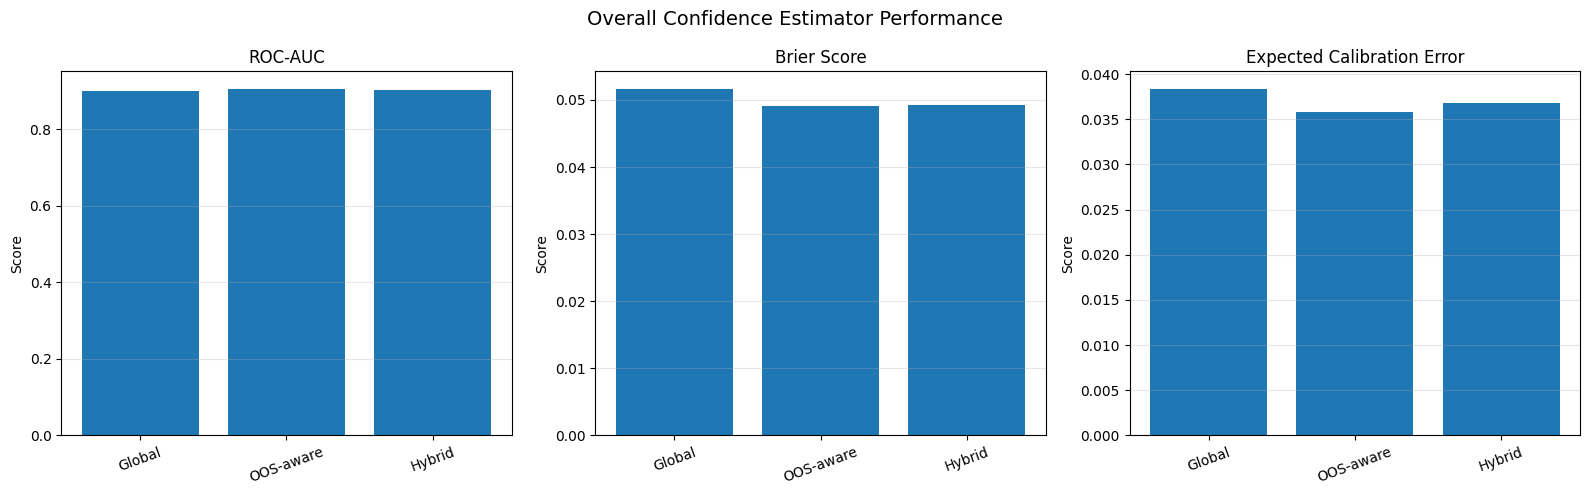

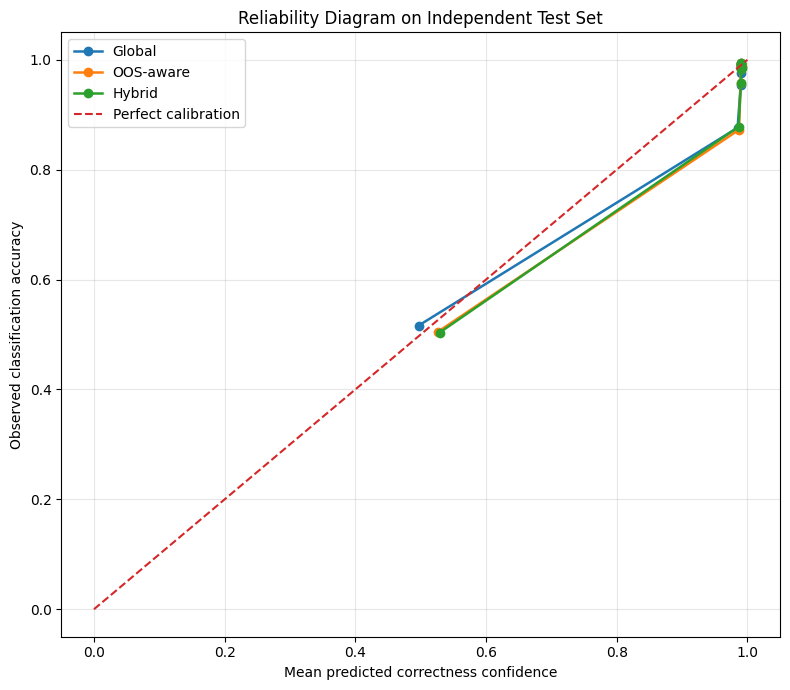

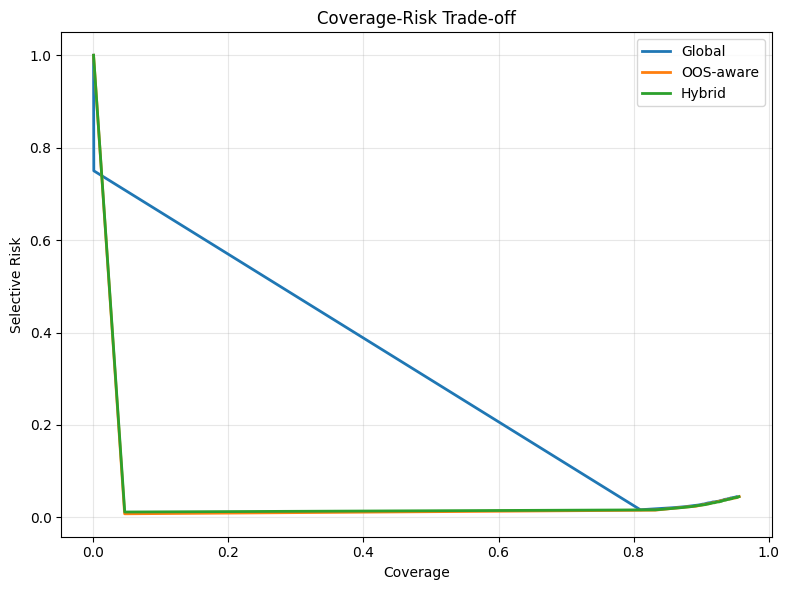

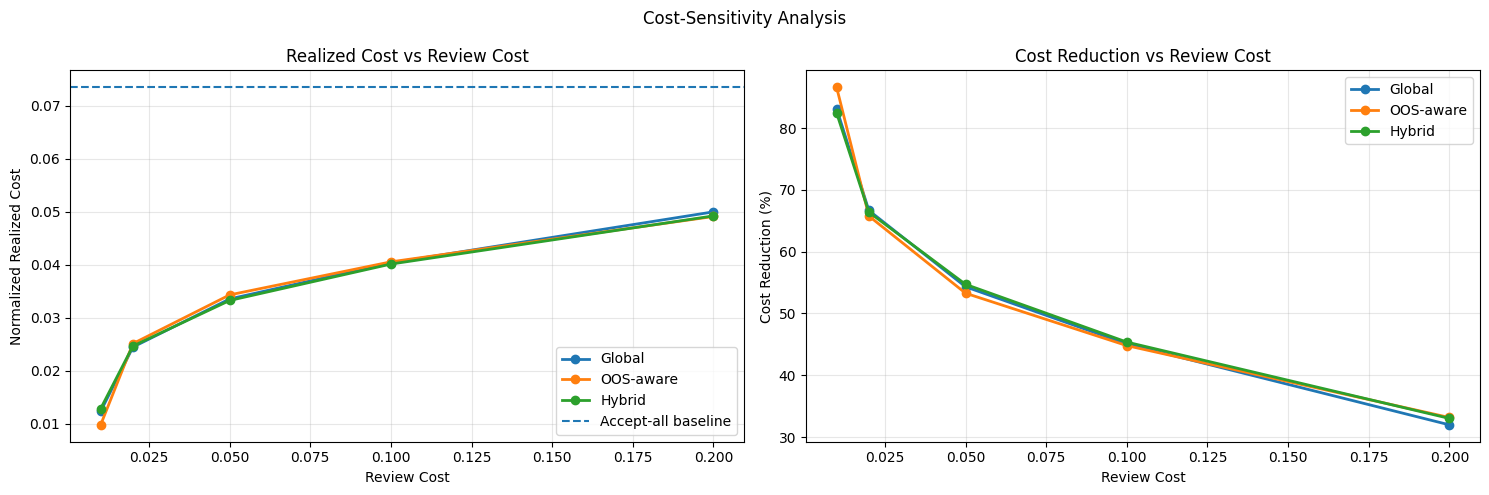


IN-SCOPE VS OOS PERFORMANCE


,Group,Strategy,Samples,ROC_AUC,Brier_score,ECE
0,In-scope,Global,4500,0.898838,0.021476,0.010678
1,In-scope,OOS-aware,4500,0.863351,0.021570,0.010000
2,In-scope,Hybrid,4500,0.863017,0.021665,0.011220
3,OOS,Global,1000,0.781036,0.187598,0.165831
4,OOS,OOS-aware,1000,0.862876,0.173340,0.154321
5,OOS,Hybrid,1000,0.858999,0.173771,0.159016


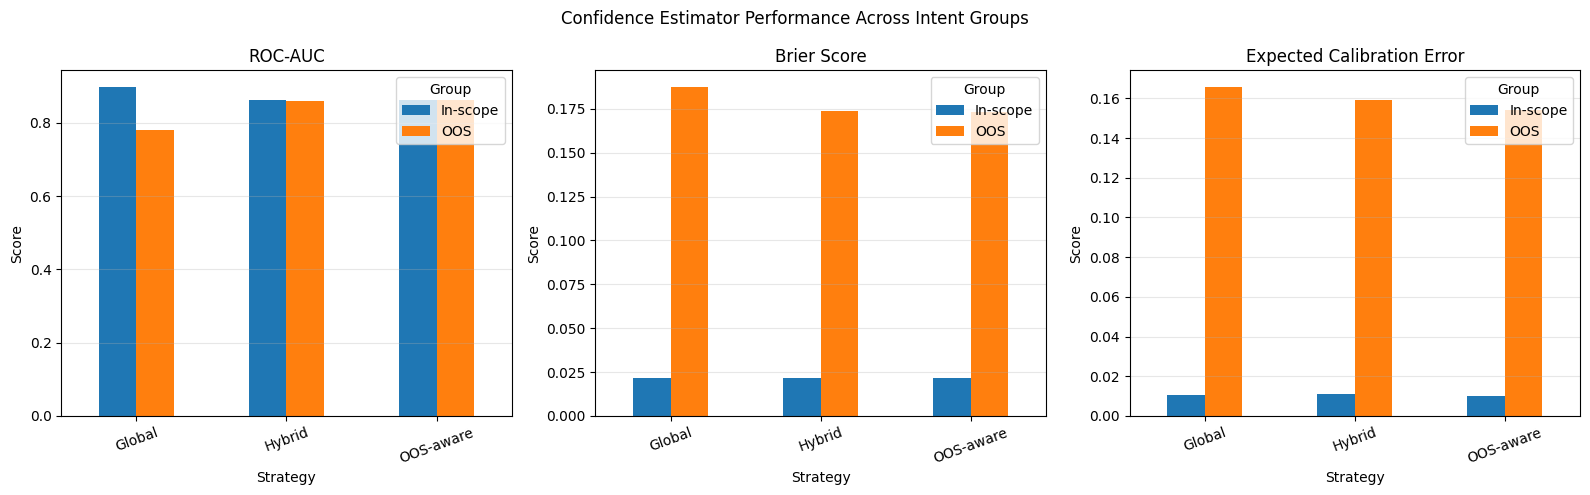

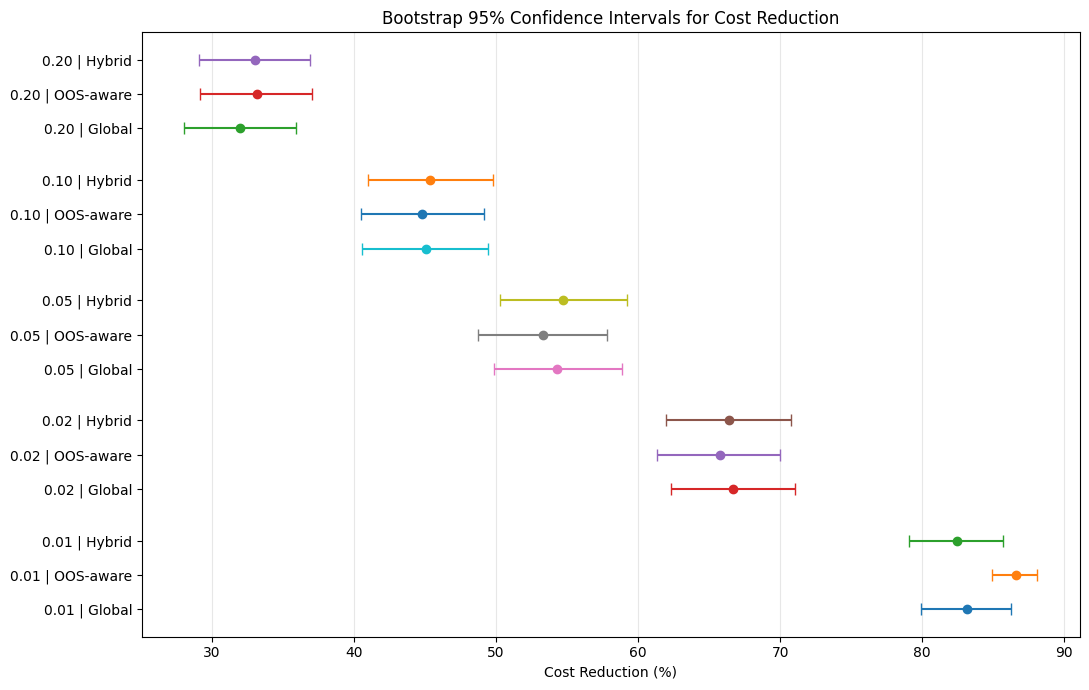

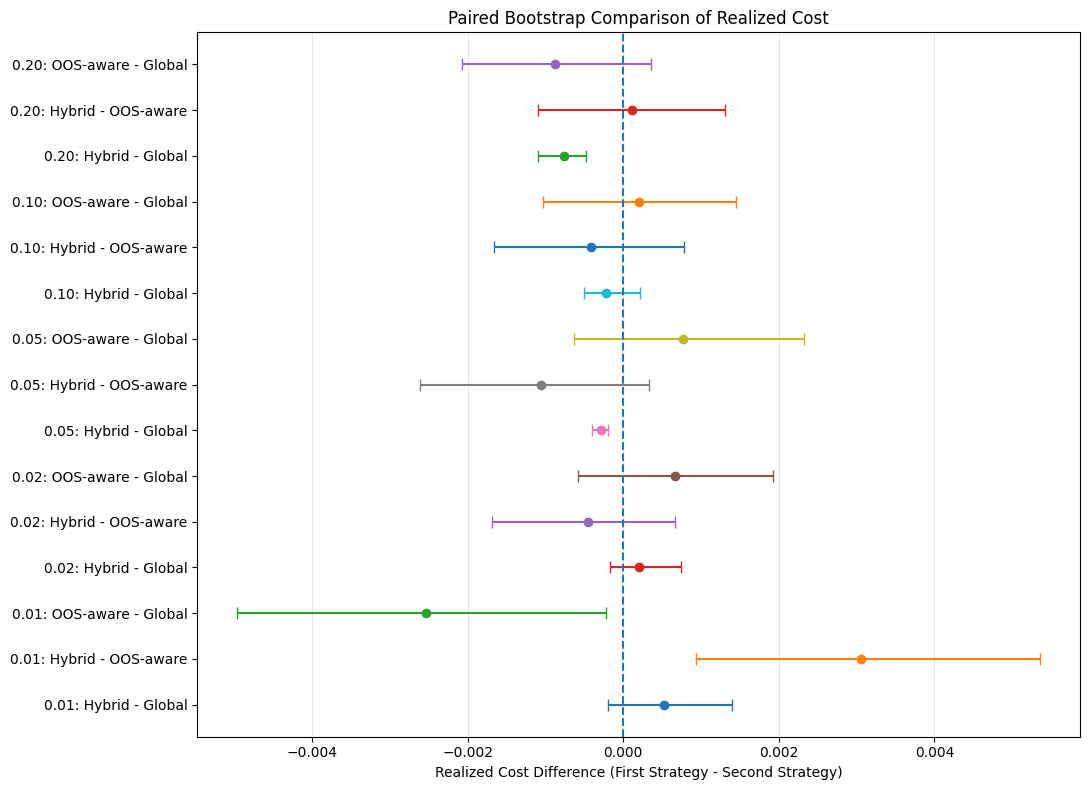


STEP 37 COMPLETED SUCCESSFULLY

Generated publication figures:
 - Figure_1_Overall_Performance.png
 - Figure_2_Reliability_Diagram.png
 - Figure_3_Coverage_Risk.png
 - Figure_4_Cost_Sensitivity.png
 - Figure_5_InScope_OOS_Comparison.png
 - Figure_6_Bootstrap_Cost_Intervals.png
 - Figure_7_Paired_Cost_Comparisons.png

Output directory:
/content/CA_CSDL_publication_figures

All figures are saved at 300 DPI.
All supporting result tables are saved as CSV.


In [ ]:

# ============================================================
# STEP 37: PUBLICATION-READY RESULTS AND VISUALIZATIONS
# CA-CSDL Q1 RESEARCH
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    roc_auc_score,
    brier_score_loss
)

# ------------------------------------------------------------
# 1. Load test data and Step 36 results
# ------------------------------------------------------------

OUTPUT_DIR = "/content/CA_CSDL_publication_figures"
os.makedirs(OUTPUT_DIR, exist_ok=True)

test_df = pd.read_csv(
    "/content/CA_CSDL_test_predictions_features.csv"
)

individual_df = pd.read_csv(
    "/content/CA_CSDL_step36_individual_bootstrap_CI.csv"
)

comparison_df = pd.read_csv(
    "/content/CA_CSDL_step36_paired_bootstrap_tests.csv"
)

y = test_df["correct"].astype(int).to_numpy()

actual_oos = (
    test_df["actual_intent"]
    .astype(str)
    .str.lower()
    .eq("out_of_scope")
    .to_numpy()
)

probabilities = {
    "Global": np.asarray(global_prob, dtype=float),
    "OOS-aware": np.asarray(oos_prob, dtype=float),
    "Hybrid": np.asarray(hybrid_prob, dtype=float)
}

for name, p in probabilities.items():
    assert len(p) == len(y), (
        f"{name} probability length mismatch"
    )

    assert np.all(np.isfinite(p)), (
        f"{name} contains invalid probabilities"
    )

print("Test samples:", len(y))
print("Correct:", int(y.sum()))
print("Incorrect:", int((y == 0).sum()))
print("In-scope:", int((~actual_oos).sum()))
print("OOS:", int(actual_oos.sum()))

# ------------------------------------------------------------
# 2. Define evaluation functions
# ------------------------------------------------------------

def calculate_ece(y_true, confidence, n_bins=15):

    y_true = np.asarray(y_true)
    confidence = np.asarray(confidence)

    bin_edges = np.linspace(0, 1, n_bins + 1)

    ece = 0.0

    for i in range(n_bins):

        if i == n_bins - 1:
            mask = (
                (confidence >= bin_edges[i]) &
                (confidence <= bin_edges[i + 1])
            )
        else:
            mask = (
                (confidence >= bin_edges[i]) &
                (confidence < bin_edges[i + 1])
            )

        if np.any(mask):

            bin_accuracy = np.mean(y_true[mask])
            bin_confidence = np.mean(confidence[mask])

            ece += (
                np.sum(mask) / len(y_true)
            ) * abs(
                bin_accuracy - bin_confidence
            )

    return ece


def calculate_auc(y_true, confidence):

    if len(np.unique(y_true)) < 2:
        return np.nan

    return roc_auc_score(y_true, confidence)


def calculate_metrics(y_true, confidence):

    return {
        "ROC_AUC": calculate_auc(y_true, confidence),
        "Brier_score": brier_score_loss(
            y_true, confidence
        ),
        "ECE": calculate_ece(
            y_true, confidence
        )
    }


# ------------------------------------------------------------
# 3. Overall confidence-estimator performance
# ------------------------------------------------------------

overall_records = []

for name, p in probabilities.items():

    metrics = calculate_metrics(y, p)

    overall_records.append({
        "Strategy": name,
        **metrics
    })

overall_df = pd.DataFrame(overall_records)

overall_df.to_csv(
    f"{OUTPUT_DIR}/overall_confidence_performance.csv",
    index=False
)

print("\nOVERALL CONFIDENCE PERFORMANCE")
display(overall_df.round(6))


# ------------------------------------------------------------
# FIGURE 1: Overall confidence-estimator performance
# ------------------------------------------------------------

fig, axes = plt.subplots(
    1, 3,
    figsize=(16, 5)
)

metrics_to_plot = [
    ("ROC_AUC", "ROC-AUC"),
    ("Brier_score", "Brier Score"),
    ("ECE", "Expected Calibration Error")
]

for ax, (metric, title) in zip(
    axes, metrics_to_plot
):

    ax.bar(
        overall_df["Strategy"],
        overall_df[metric]
    )

    ax.set_title(title)
    ax.set_ylabel("Score")
    ax.tick_params(axis="x", rotation=20)
    ax.grid(axis="y", alpha=0.3)

fig.suptitle(
    "Overall Confidence Estimator Performance",
    fontsize=14
)

plt.tight_layout()

plt.savefig(
    f"{OUTPUT_DIR}/Figure_1_Overall_Performance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------------------------
# FIGURE 2: Reliability diagrams
# ------------------------------------------------------------

def reliability_points(
    y_true,
    confidence,
    n_bins=10
):

    order = np.argsort(confidence)

    bins = np.array_split(order, n_bins)

    mean_confidence = []
    observed_accuracy = []

    for indices in bins:

        if len(indices) == 0:
            continue

        mean_confidence.append(
            np.mean(confidence[indices])
        )

        observed_accuracy.append(
            np.mean(y_true[indices])
        )

    return (
        np.array(mean_confidence),
        np.array(observed_accuracy)
    )


fig, ax = plt.subplots(figsize=(8, 7))

for name, p in probabilities.items():

    mean_conf, accuracy = reliability_points(
        y,
        p,
        n_bins=10
    )

    ax.plot(
        mean_conf,
        accuracy,
        marker="o",
        linewidth=1.8,
        label=name
    )

ax.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Perfect calibration"
)

ax.set_xlabel("Mean predicted correctness confidence")
ax.set_ylabel("Observed classification accuracy")

ax.set_title(
    "Reliability Diagram on Independent Test Set"
)

ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    f"{OUTPUT_DIR}/Figure_2_Reliability_Diagram.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------------------------
# FIGURE 3: Coverage-risk curves
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(8, 6))

coverage_risk_records = []

for name, p in probabilities.items():

    thresholds = np.linspace(
        0.50,
        0.999,
        150
    )

    coverages = []
    risks = []

    for threshold in thresholds:

        accepted = p >= threshold

        coverage = np.mean(accepted)

        if accepted.sum() == 0:
            continue

        risk = 1 - np.mean(y[accepted])

        coverages.append(coverage)
        risks.append(risk)

        coverage_risk_records.append({
            "Strategy": name,
            "Threshold": threshold,
            "Coverage": coverage,
            "Selective_risk": risk
        })

    ax.plot(
        coverages,
        risks,
        linewidth=2,
        label=name
    )

ax.set_xlabel("Coverage")
ax.set_ylabel("Selective Risk")

ax.set_title(
    "Coverage-Risk Trade-off"
)

ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    f"{OUTPUT_DIR}/Figure_3_Coverage_Risk.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

coverage_risk_df = pd.DataFrame(
    coverage_risk_records
)

coverage_risk_df.to_csv(
    f"{OUTPUT_DIR}/coverage_risk_data.csv",
    index=False
)


# ------------------------------------------------------------
# FIGURE 4: Cost-sensitivity analysis
# ------------------------------------------------------------

fig, axes = plt.subplots(
    1, 2,
    figsize=(15, 5)
)

for strategy in probabilities.keys():

    strategy_data = individual_df[
        individual_df["Strategy"] == strategy
    ].sort_values("Review_cost")

    axes[0].plot(
        strategy_data["Review_cost"],
        strategy_data["Realized_cost_Observed"],
        marker="o",
        linewidth=2,
        label=strategy
    )

    axes[1].plot(
        strategy_data["Review_cost"],
        strategy_data["Cost_reduction_percent"],
        marker="o",
        linewidth=2,
        label=strategy
    )

axes[0].set_xlabel("Review Cost")
axes[0].set_ylabel("Normalized Realized Cost")
axes[0].set_title("Realized Cost vs Review Cost")

axes[1].set_xlabel("Review Cost")
axes[1].set_ylabel("Cost Reduction (%)")
axes[1].set_title("Cost Reduction vs Review Cost")

baseline_cost = np.mean(1 - y)

axes[0].axhline(
    baseline_cost,
    linestyle="--",
    label="Accept-all baseline"
)

for ax in axes:
    ax.grid(alpha=0.3)
    ax.legend()

fig.suptitle(
    "Cost-Sensitivity Analysis"
)

plt.tight_layout()

plt.savefig(
    f"{OUTPUT_DIR}/Figure_4_Cost_Sensitivity.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------------------------
# FIGURE 5: In-scope vs OOS subgroup performance
# ------------------------------------------------------------

group_masks = {
    "In-scope": ~actual_oos,
    "OOS": actual_oos
}

group_records = []

for group_name, mask in group_masks.items():

    y_group = y[mask]

    for strategy, p in probabilities.items():

        metrics = calculate_metrics(
            y_group,
            p[mask]
        )

        group_records.append({
            "Group": group_name,
            "Strategy": strategy,
            "Samples": int(mask.sum()),
            **metrics
        })

group_df = pd.DataFrame(group_records)

group_df.to_csv(
    f"{OUTPUT_DIR}/subgroup_performance.csv",
    index=False
)

print("\nIN-SCOPE VS OOS PERFORMANCE")
display(group_df.round(6))


fig, axes = plt.subplots(
    1, 3,
    figsize=(16, 5)
)

for ax, (metric, title) in zip(
    axes,
    metrics_to_plot
):

    pivot = group_df.pivot(
        index="Strategy",
        columns="Group",
        values=metric
    )

    pivot.plot(
        kind="bar",
        ax=ax
    )

    ax.set_title(title)
    ax.set_ylabel("Score")
    ax.tick_params(axis="x", rotation=20)
    ax.grid(axis="y", alpha=0.3)
    ax.legend(title="Group")

fig.suptitle(
    "Confidence Estimator Performance Across Intent Groups"
)

plt.tight_layout()

plt.savefig(
    f"{OUTPUT_DIR}/Figure_5_InScope_OOS_Comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------------------------
# FIGURE 6: Bootstrap confidence intervals
# Cost reduction percentages
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(11, 7))

strategy_order = [
    "Global",
    "OOS-aware",
    "Hybrid"
]

review_cost_order = [
    0.01,
    0.02,
    0.05,
    0.10,
    0.20
]

positions = []
labels = []
position = 0

for review_cost in review_cost_order:

    for strategy in strategy_order:

        row = individual_df[
            (individual_df["Review_cost"] == review_cost) &
            (individual_df["Strategy"] == strategy)
        ].iloc[0]

        estimate = row["Cost_reduction_percent"]

        lower = row["Cost_reduction_CI_lower"]
        upper = row["Cost_reduction_CI_upper"]

        ax.errorbar(
            estimate,
            position,
            xerr=[[
                estimate - lower
            ], [
                upper - estimate
            ]],
            fmt="o",
            capsize=4
        )

        positions.append(position)

        labels.append(
            f"{review_cost:.2f} | {strategy}"
        )

        position += 1

    position += 0.5

ax.set_yticks(positions)
ax.set_yticklabels(labels)

ax.set_xlabel("Cost Reduction (%)")
ax.set_title(
    "Bootstrap 95% Confidence Intervals for Cost Reduction"
)

ax.grid(axis="x", alpha=0.3)

plt.tight_layout()

plt.savefig(
    f"{OUTPUT_DIR}/Figure_6_Bootstrap_Cost_Intervals.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------------------------
# FIGURE 7: Paired statistical comparisons
# Realized cost differences
#
# Negative difference favours the first strategy.
# ------------------------------------------------------------

cost_comparisons = comparison_df[
    comparison_df["Metric"] == "Realized_cost"
].copy()

cost_comparisons = cost_comparisons.sort_values(
    ["Review_cost", "Comparison"]
).reset_index(drop=True)

fig, ax = plt.subplots(figsize=(11, 8))

positions = np.arange(
    len(cost_comparisons)
)

for i, row in cost_comparisons.iterrows():

    estimate = row["Observed_difference"]

    lower = row["CI_lower"]
    upper = row["CI_upper"]

    ax.errorbar(
        estimate,
        i,
        xerr=[[
            estimate - lower
        ], [
            upper - estimate
        ]],
        fmt="o",
        capsize=4
    )

ax.axvline(
    0,
    linestyle="--"
)

labels = [
    f'{row["Review_cost"]:.2f}: {row["Comparison"]}'
    for _, row in cost_comparisons.iterrows()
]

ax.set_yticks(positions)
ax.set_yticklabels(labels)

ax.set_xlabel(
    "Realized Cost Difference (First Strategy - Second Strategy)"
)

ax.set_title(
    "Paired Bootstrap Comparison of Realized Cost"
)

ax.grid(axis="x", alpha=0.3)

plt.tight_layout()

plt.savefig(
    f"{OUTPUT_DIR}/Figure_7_Paired_Cost_Comparisons.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------------------------
# 4. Save consolidated result tables
# ------------------------------------------------------------

overall_df.to_csv(
    f"{OUTPUT_DIR}/Table_Overall_Performance.csv",
    index=False
)

group_df.to_csv(
    f"{OUTPUT_DIR}/Table_Subgroup_Performance.csv",
    index=False
)

individual_df.to_csv(
    f"{OUTPUT_DIR}/Table_Bootstrap_Confidence_Intervals.csv",
    index=False
)

comparison_df.to_csv(
    f"{OUTPUT_DIR}/Table_Paired_Statistical_Comparisons.csv",
    index=False
)

# ------------------------------------------------------------
# 5. Final report
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("STEP 37 COMPLETED SUCCESSFULLY")
print("=" * 65)

print("\nGenerated publication figures:")

figure_files = [
    "Figure_1_Overall_Performance.png",
    "Figure_2_Reliability_Diagram.png",
    "Figure_3_Coverage_Risk.png",
    "Figure_4_Cost_Sensitivity.png",
    "Figure_5_InScope_OOS_Comparison.png",
    "Figure_6_Bootstrap_Cost_Intervals.png",
    "Figure_7_Paired_Cost_Comparisons.png"
]

for filename in figure_files:
    print(" -", filename)

print("\nOutput directory:")
print(OUTPUT_DIR)

print("\nAll figures are saved at 300 DPI.")
print("All supporting result tables are saved as CSV.")


In [ ]:

# ============================================================
# STEP 38: FINAL CA-CSDL EXPERIMENTAL CONSISTENCY AUDIT
# ============================================================

import os
import json
import warnings
import numpy as np
import pandas as pd

from sklearn.metrics import roc_auc_score, brier_score_loss
from IPython.display import display

warnings.filterwarnings("ignore")

# ------------------------------------------------------------
# 1. Paths
# ------------------------------------------------------------

BASE_DIR = "/content"

FIGURE_DIR = (
    "/content/CA_CSDL_publication_figures"
)

TEST_FILE = (
    "/content/CA_CSDL_test_predictions_features.csv"
)

BOOTSTRAP_FILE = (
    "/content/CA_CSDL_step36_individual_bootstrap_CI.csv"
)

PAIRED_FILE = (
    "/content/CA_CSDL_step36_paired_bootstrap_tests.csv"
)

STRATEGY_FILE = (
    "/content/CA_CSDL_strategy_comparison.csv"
)

OOS_FILE = (
    "/content/CA_CSDL_oos_aware_group_results.csv"
)

# ------------------------------------------------------------
# 2. Load test data
# ------------------------------------------------------------

assert os.path.exists(TEST_FILE), (
    "Test predictions CSV is missing."
)

test_df = pd.read_csv(TEST_FILE)

required_columns = [
    "correct",
    "actual_intent",
    "predicted_intent",
    "min_token_probability",
    "mean_top2_margin",
    "mean_normalized_entropy"
]

missing_columns = [
    col for col in required_columns
    if col not in test_df.columns
]

assert not missing_columns, (
    f"Missing test columns: {missing_columns}"
)

y = test_df["correct"].astype(int).to_numpy()

actual_oos = (
    test_df["actual_intent"]
    .astype(str)
    .str.lower()
    .eq("out_of_scope")
    .to_numpy()
)

N = len(y)

print("=" * 65)
print("STEP 38: CA-CSDL FINAL EXPERIMENTAL AUDIT")
print("=" * 65)

print("\nTEST DATA SUMMARY")

print("Test samples:", N)
print("Correct:", int(y.sum()))
print("Incorrect:", int((y == 0).sum()))
print("In-scope:", int((~actual_oos).sum()))
print("OOS:", int(actual_oos.sum()))

assert N == 5500, "Unexpected test sample count."
assert int(y.sum()) == 5096, "Correct count mismatch."
assert int(actual_oos.sum()) == 1000, "OOS count mismatch."

# ------------------------------------------------------------
# 3. Reconstruct or retrieve confidence probabilities
# ------------------------------------------------------------

probabilities = {}

# Reuse frozen confidence predictions from the current runtime
if all(
    name in globals()
    for name in ["global_prob", "oos_prob", "hybrid_prob"]
):

    probabilities = {
        "Global": np.asarray(global_prob, dtype=float),
        "OOS-aware": np.asarray(oos_prob, dtype=float),
        "Hybrid": np.asarray(hybrid_prob, dtype=float)
    }

else:

    # Look for an existing CSV with stored probabilities
    candidate_files = [
        "/content/CA_CSDL_final_test_decisions.csv",
        "/content/CA_CSDL_hybrid_cost_comparison.csv"
    ]

    found = False

    for path in candidate_files:

        if os.path.exists(path):

            temp = pd.read_csv(path)

            print("\nInspecting:", path)
            print("Columns:", temp.columns.tolist())

            probability_columns = {
                "Global": ["global_prob", "global_confidence"],
                "OOS-aware": ["oos_prob", "oos_aware_confidence"],
                "Hybrid": ["hybrid_prob", "hybrid_confidence"]
            }

            for strategy, candidates in probability_columns.items():

                match = next(
                    (
                        col for col in candidates
                        if col in temp.columns
                    ),
                    None
                )

                if match is not None and len(temp) == N:
                    probabilities[strategy] = (
                        temp[match].to_numpy(dtype=float)
                    )

            if len(probabilities) == 3:
                found = True
                break

    if not found:
        raise RuntimeError(
            "Frozen confidence probability arrays are unavailable. "
            "Restore the Global, OOS-aware and Hybrid predictions "
            "from the Step 26/28 model pipeline. Do not refit or "
            "recalibrate using test labels."
        )

# Validate probabilities

for name, p in probabilities.items():

    assert len(p) == N, (
        f"{name}: wrong probability count"
    )

    assert np.all(np.isfinite(p)), (
        f"{name}: invalid probability values"
    )

    assert np.all((p >= 0) & (p <= 1)), (
        f"{name}: probability outside [0,1]"
    )

print("\nFrozen confidence predictions verified.")

# ------------------------------------------------------------
# 4. Consistent ECE implementation
# Equal-width bins, 15 bins
# ------------------------------------------------------------

def calculate_ece(y_true, confidence, n_bins=15):

    y_true = np.asarray(y_true)
    confidence = np.asarray(confidence)

    bin_edges = np.linspace(0, 1, n_bins + 1)

    ece = 0.0

    for i in range(n_bins):

        if i == n_bins - 1:
            mask = (
                (confidence >= bin_edges[i]) &
                (confidence <= bin_edges[i + 1])
            )
        else:
            mask = (
                (confidence >= bin_edges[i]) &
                (confidence < bin_edges[i + 1])
            )

        if np.any(mask):

            bin_accuracy = np.mean(y_true[mask])
            bin_confidence = np.mean(confidence[mask])

            ece += (
                np.sum(mask) / len(y_true)
            ) * abs(
                bin_accuracy - bin_confidence
            )

    return ece


# ------------------------------------------------------------
# 5. Overall confidence metrics
# ------------------------------------------------------------

overall_records = []

for strategy, p in probabilities.items():

    overall_records.append({

        "Strategy": strategy,

        "ROC_AUC": roc_auc_score(y, p),

        "Brier_score": brier_score_loss(y, p),

        "ECE_15_equal_width": calculate_ece(
            y, p, n_bins=15
        ),

        "Mean_confidence": np.mean(p),

        "Observed_accuracy": np.mean(y)

    })

overall_df = pd.DataFrame(overall_records)

print("\nOVERALL CONFIDENCE METRICS")

display(overall_df.round(6))

# ------------------------------------------------------------
# 6. In-scope and OOS subgroup metrics
# ------------------------------------------------------------

group_records = []

for group_name, mask in [
    ("In-scope", ~actual_oos),
    ("OOS", actual_oos)
]:

    y_group = y[mask]

    for strategy, p in probabilities.items():

        p_group = p[mask]

        group_records.append({

            "Group": group_name,

            "Strategy": strategy,

            "Samples": len(y_group),

            "Correct": int(y_group.sum()),

            "Incorrect": int((y_group == 0).sum()),

            "ROC_AUC": roc_auc_score(
                y_group, p_group
            ),

            "Brier_score": brier_score_loss(
                y_group, p_group
            ),

            "ECE_15_equal_width": calculate_ece(
                y_group, p_group, 15
            )

        })

group_df = pd.DataFrame(group_records)

print("\nIN-SCOPE AND OOS METRICS")

display(group_df.round(6))

# ------------------------------------------------------------
# 7. Verify cost-sensitive results
# ------------------------------------------------------------

C_WRONG = 1.0

REVIEW_COSTS = [
    0.01, 0.02, 0.05, 0.10, 0.20
]

cost_records = []

for review_cost in REVIEW_COSTS:

    threshold = 1 - review_cost / C_WRONG

    for strategy, p in probabilities.items():

        accept = p >= threshold

        accepted = int(accept.sum())
        reviewed = int((~accept).sum())

        errors = int(
            np.sum((y == 0) & accept)
        )

        coverage = accepted / N

        accepted_accuracy = (
            np.mean(y[accept])
            if accepted > 0 else np.nan
        )

        selective_risk = (
            1 - accepted_accuracy
            if accepted > 0 else np.nan
        )

        realized_cost = (
            errors * C_WRONG
            + reviewed * review_cost
        ) / N

        cost_records.append({

            "Review_cost": review_cost,

            "Threshold": threshold,

            "Strategy": strategy,

            "Coverage": coverage,

            "Accepted": accepted,

            "Reviewed": reviewed,

            "Accepted_errors": errors,

            "Accepted_accuracy": accepted_accuracy,

            "Selective_risk": selective_risk,

            "Realized_cost": realized_cost

        })

cost_df = pd.DataFrame(cost_records)

print("\nCOST-SENSITIVE RESULTS")

display(cost_df.round(6))

# ------------------------------------------------------------
# 8. Check bootstrap result files
# ------------------------------------------------------------

bootstrap_df = None
paired_df = None

if os.path.exists(BOOTSTRAP_FILE):

    bootstrap_df = pd.read_csv(BOOTSTRAP_FILE)

    print("\nBOOTSTRAP FILE VERIFIED")

    print(
        "Individual bootstrap rows:",
        len(bootstrap_df)
    )

    print(
        "Review costs:",
        sorted(bootstrap_df["Review_cost"].unique())
    )

else:
    print("\nWARNING: Individual bootstrap file missing.")

if os.path.exists(PAIRED_FILE):

    paired_df = pd.read_csv(PAIRED_FILE)

    print("\nPAIRED TEST FILE VERIFIED")

    print(
        "Paired comparison rows:",
        len(paired_df)
    )

else:
    print("\nWARNING: Paired bootstrap file missing.")

# ------------------------------------------------------------
# 9. Check statistical result consistency
# ------------------------------------------------------------

if paired_df is not None:

    required_stat_columns = [
        "Comparison",
        "Metric",
        "Raw_p",
        "Holm_adjusted_p",
        "Significant_0.05"
    ]

    missing = [
        c for c in required_stat_columns
        if c not in paired_df.columns
    ]

    assert not missing, (
        f"Statistical columns missing: {missing}"
    )

    assert np.all(
        paired_df["Holm_adjusted_p"] >=
        paired_df["Raw_p"] - 1e-10
    ), (
        "Holm-adjusted p-values are unexpectedly "
        "smaller than raw p-values."
    )

    print("\nStatistical columns verified.")

# ------------------------------------------------------------
# 10. Verify all seven publication figures
# ------------------------------------------------------------

figure_names = [

    "Figure_1_Overall_Performance.png",

    "Figure_2_Reliability_Diagram.png",

    "Figure_3_Coverage_Risk.png",

    "Figure_4_Cost_Sensitivity.png",

    "Figure_5_InScope_OOS_Comparison.png",

    "Figure_6_Bootstrap_Cost_Intervals.png",

    "Figure_7_Paired_Cost_Comparisons.png"

]

figure_records = []

for filename in figure_names:

    path = os.path.join(
        FIGURE_DIR,
        filename
    )

    exists = os.path.exists(path)

    figure_records.append({

        "Figure": filename,

        "Exists": exists,

        "Size_KB": (
            round(os.path.getsize(path) / 1024, 2)
            if exists else None
        )

    })

figure_df = pd.DataFrame(figure_records)

print("\nPUBLICATION FIGURE AUDIT")

display(figure_df)

# ------------------------------------------------------------
# 11. Save audit tables
# ------------------------------------------------------------

overall_df.to_csv(
    "/content/CA_CSDL_step38_overall_metrics.csv",
    index=False
)

group_df.to_csv(
    "/content/CA_CSDL_step38_group_metrics.csv",
    index=False
)

cost_df.to_csv(
    "/content/CA_CSDL_step38_cost_metrics.csv",
    index=False
)

figure_df.to_csv(
    "/content/CA_CSDL_step38_figure_audit.csv",
    index=False
)

# ------------------------------------------------------------
# 12. Generate audit report
# ------------------------------------------------------------

audit_report = {

    "test_samples": int(N),

    "correct": int(y.sum()),

    "incorrect": int((y == 0).sum()),

    "in_scope": int((~actual_oos).sum()),

    "oos": int(actual_oos.sum()),

    "confidence_predictions_verified": True,

    "ece_definition": (
        "15 equal-width bins, weighted absolute "
        "difference between bin accuracy and "
        "mean confidence"
    ),

    "cost_wrong": C_WRONG,

    "review_cost_scenarios": REVIEW_COSTS,

    "figures_found": int(
        figure_df["Exists"].sum()
    ),

    "figures_expected": len(figure_names),

    "bootstrap_file_found": (
        os.path.exists(BOOTSTRAP_FILE)
    ),

    "paired_test_file_found": (
        os.path.exists(PAIRED_FILE)
    )

}

with open(
    "/content/CA_CSDL_step38_audit_report.json",
    "w"
) as f:

    json.dump(
        audit_report,
        f,
        indent=4
    )

print("\n" + "=" * 65)

print("STEP 38 AUDIT COMPLETED")

print("=" * 65)

print(
    json.dumps(
        audit_report,
        indent=4
    )
)

print("\nSaved audit files:")
print("/content/CA_CSDL_step38_overall_metrics.csv")
print("/content/CA_CSDL_step38_group_metrics.csv")
print("/content/CA_CSDL_step38_cost_metrics.csv")
print("/content/CA_CSDL_step38_figure_audit.csv")
print("/content/CA_CSDL_step38_audit_report.json")


STEP 38: CA-CSDL FINAL EXPERIMENTAL AUDIT

TEST DATA SUMMARY
Test samples: 5500
Correct: 5096
Incorrect: 404
In-scope: 4500
OOS: 1000

Frozen confidence predictions verified.

OVERALL CONFIDENCE METRICS


,Strategy,ROC_AUC,Brier_score,ECE_15_equal_width,Mean_confidence,Observed_accuracy
0,Global,0.900292,0.051680,0.038383,0.940581,0.926545
1,OOS-aware,0.906670,0.049165,0.035826,0.943560,0.926545
2,Hybrid,0.903679,0.049321,0.036814,0.944128,0.926545



IN-SCOPE AND OOS METRICS


,Group,Strategy,Samples,Correct,Incorrect,ROC_AUC,Brier_score,ECE_15_equal_width
0,In-scope,Global,4500,4371,129,0.898838,0.021476,0.010678
1,In-scope,OOS-aware,4500,4371,129,0.863351,0.021570,0.010000
2,In-scope,Hybrid,4500,4371,129,0.863017,0.021665,0.011220
3,OOS,Global,1000,725,275,0.781036,0.187598,0.165831
4,OOS,OOS-aware,1000,725,275,0.862876,0.173340,0.154321
5,OOS,Hybrid,1000,725,275,0.858999,0.173771,0.159016



COST-SENSITIVE RESULTS


,Review_cost,Threshold,Strategy,Coverage,Accepted,Reviewed,Accepted_errors,Accepted_accuracy,Selective_risk,Realized_cost
0,0.01,0.99,Global,0.745455,4100,1400,54,0.986829,0.013171,0.012364
1,0.01,0.99,OOS-aware,0.217273,1195,4305,11,0.990795,0.009205,0.009827
2,0.01,0.99,Hybrid,0.784000,4312,1188,59,0.986317,0.013683,0.012887
3,0.02,0.98,Global,0.885273,4869,631,122,0.974944,0.025056,0.024476
4,0.02,0.98,OOS-aware,0.897636,4937,563,127,0.974276,0.025724,0.025138
5,0.02,0.98,Hybrid,0.893273,4913,587,124,0.974761,0.025239,0.024680
6,0.05,0.95,Global,0.914364,5029,471,161,0.967986,0.032014,0.033555
7,0.05,0.95,OOS-aware,0.920909,5065,435,167,0.967029,0.032971,0.034318
8,0.05,0.95,Hybrid,0.920182,5061,439,161,0.968188,0.031812,0.033264
9,0.10,0.90,Global,0.927455,5101,399,182,0.964321,0.035679,0.040345



BOOTSTRAP FILE VERIFIED
Individual bootstrap rows: 15
Review costs: [np.float64(0.01), np.float64(0.02), np.float64(0.05), np.float64(0.1), np.float64(0.2)]

PAIRED TEST FILE VERIFIED
Paired comparison rows: 60

Statistical columns verified.

PUBLICATION FIGURE AUDIT


,Figure,Exists,Size_KB
0,Figure_1_Overall_Performance.png,True,167.07
1,Figure_2_Reliability_Diagram.png,True,206.89
2,Figure_3_Coverage_Risk.png,True,146.07
3,Figure_4_Cost_Sensitivity.png,True,316.86
4,Figure_5_InScope_OOS_Comparison.png,True,194.67
5,Figure_6_Bootstrap_Cost_Intervals.png,True,197.24
6,Figure_7_Paired_Cost_Comparisons.png,True,273.12



STEP 38 AUDIT COMPLETED
{
    "test_samples": 5500,
    "correct": 5096,
    "incorrect": 404,
    "in_scope": 4500,
    "oos": 1000,
    "confidence_predictions_verified": true,
    "ece_definition": "15 equal-width bins, weighted absolute difference between bin accuracy and mean confidence",
    "cost_wrong": 1.0,
    "review_cost_scenarios": [
        0.01,
        0.02,
        0.05,
        0.1,
        0.2
    ],
    "figures_found": 7,
    "figures_expected": 7,
    "bootstrap_file_found": true,
    "paired_test_file_found": true
}

Saved audit files:
/content/CA_CSDL_step38_overall_metrics.csv
/content/CA_CSDL_step38_group_metrics.csv
/content/CA_CSDL_step38_cost_metrics.csv
/content/CA_CSDL_step38_figure_audit.csv
/content/CA_CSDL_step38_audit_report.json


In [ ]:

# ============================================================
# STEP 39: FINAL CA-CSDL PUBLICATION PACKAGE
# ============================================================

import os
import json
import shutil
import zipfile
import pandas as pd
from datetime import datetime

# ------------------------------------------------------------
# 1. Create publication package directory
# ------------------------------------------------------------

SOURCE_DIR = "/content"

PACKAGE_DIR = (
    "/content/CA_CSDL_Final_Publication_Package"
)

FIGURE_DIR = (
    "/content/CA_CSDL_publication_figures"
)

os.makedirs(PACKAGE_DIR, exist_ok=True)

TABLE_DIR = os.path.join(PACKAGE_DIR, "Tables")
FIGURE_OUT = os.path.join(PACKAGE_DIR, "Figures")
STAT_DIR = os.path.join(PACKAGE_DIR, "Statistical_Analysis")
CONFIG_DIR = os.path.join(PACKAGE_DIR, "Configuration")

for folder in [
    TABLE_DIR,
    FIGURE_OUT,
    STAT_DIR,
    CONFIG_DIR
]:
    os.makedirs(folder, exist_ok=True)

print("Publication package directories created.")

# ------------------------------------------------------------
# 2. Copy experimental tables
# ------------------------------------------------------------

table_files = [

    "CA_CSDL_step38_overall_metrics.csv",

    "CA_CSDL_step38_group_metrics.csv",

    "CA_CSDL_step38_cost_metrics.csv",

    "CA_CSDL_strategy_comparison.csv",

    "CA_CSDL_cost_sensitivity_all.csv",

    "CA_CSDL_cost_sensitivity_best.csv",

    "CA_CSDL_cost_sensitivity_groups.csv",

    "CA_CSDL_test_classification_report.csv",

    "CA_CSDL_test_confidence_comparison.csv",

    "CA_CSDL_test_invalid_predictions.csv",

    "CA_CSDL_confidence_distribution_corrected.csv",

    "CA_CSDL_OOS_in_scope_corrected.csv",

    "CA_CSDL_global_vs_oos_aware.csv",

    "CA_CSDL_oos_aware_group_results.csv",

    "CA_CSDL_hybrid_cost_comparison.csv",

    "CA_CSDL_cost_sensitivity.csv",

    "CA_CSDL_final_test_cost_results.csv",

    "CA_CSDL_final_test_calibration.csv"

]

copied_tables = []
missing_tables = []

for filename in table_files:

    source = os.path.join(
        SOURCE_DIR,
        filename
    )

    if os.path.exists(source):

        shutil.copy2(
            source,
            TABLE_DIR
        )

        copied_tables.append(filename)

    else:

        missing_tables.append(filename)

print("\nTABLES COPIED:", len(copied_tables))

print("TABLES NOT AVAILABLE:", len(missing_tables))

# ------------------------------------------------------------
# 3. Copy statistical analysis files
# ------------------------------------------------------------

stat_files = [

    "CA_CSDL_step36_individual_bootstrap_CI.csv",

    "CA_CSDL_step36_paired_bootstrap_tests.csv",

    "CA_CSDL_cost_bootstrap_results.csv",

    "CA_CSDL_confidence_holm_corrected.csv",

    "CA_CSDL_cost_holm_corrected.csv",

    "CA_CSDL_repeated_cv_fold_results.csv",

    "CA_CSDL_repeated_cv_summary.csv",

    "CA_CSDL_repeated_cv_group_results.csv",

    "CA_CSDL_corrected_resampled_tests.csv"

]

copied_statistics = []
missing_statistics = []

for filename in stat_files:

    source = os.path.join(
        SOURCE_DIR,
        filename
    )

    if os.path.exists(source):

        shutil.copy2(
            source,
            STAT_DIR
        )

        copied_statistics.append(filename)

    else:

        missing_statistics.append(filename)

print("\nSTATISTICAL FILES COPIED:",
      len(copied_statistics))

# ------------------------------------------------------------
# 4. Copy seven publication figures
# ------------------------------------------------------------

figure_names = [

    "Figure_1_Overall_Performance.png",

    "Figure_2_Reliability_Diagram.png",

    "Figure_3_Coverage_Risk.png",

    "Figure_4_Cost_Sensitivity.png",

    "Figure_5_InScope_OOS_Comparison.png",

    "Figure_6_Bootstrap_Cost_Intervals.png",

    "Figure_7_Paired_Cost_Comparisons.png"

]

copied_figures = []
missing_figures = []

for filename in figure_names:

    source = os.path.join(
        FIGURE_DIR,
        filename
    )

    if os.path.exists(source):

        shutil.copy2(
            source,
            FIGURE_OUT
        )

        copied_figures.append(filename)

    else:

        missing_figures.append(filename)

print("\nFIGURES COPIED:", len(copied_figures))

print("FIGURES MISSING:", len(missing_figures))

# ------------------------------------------------------------
# 5. Copy Step 38 audit files
# ------------------------------------------------------------

audit_files = [

    "CA_CSDL_step38_overall_metrics.csv",

    "CA_CSDL_step38_group_metrics.csv",

    "CA_CSDL_step38_cost_metrics.csv",

    "CA_CSDL_step38_figure_audit.csv",

    "CA_CSDL_step38_audit_report.json"

]

for filename in audit_files:

    source = os.path.join(
        SOURCE_DIR,
        filename
    )

    if os.path.exists(source):

        shutil.copy2(
            source,
            CONFIG_DIR
        )

# ------------------------------------------------------------
# 6. Research configuration
# ------------------------------------------------------------

research_config = {

    "research_title": (
        "Confidence-Aware and Cost-Sensitive Decision "
        "Learning for Reliable Intent Classification "
        "Using Parameter-Efficient Large Language Models"
    ),

    "abbreviation": "CA-CSDL",

    "base_model": "Qwen/Qwen3.5-4B",

    "fine_tuning": "LoRA",

    "lora_rank": 8,

    "lora_alpha": 16,

    "quantization": (
        "Original successful training used "
        "load_in_4bit=False; this was not QLoRA."
    ),

    "dataset": "CLINC150",

    "number_of_intent_classes": 151,

    "training_samples": 15200,

    "validation_samples": 3100,

    "test_samples": 5500,

    "test_in_scope_samples": 4500,

    "test_oos_samples": 1000,

    "test_correct_predictions": 5096,

    "test_incorrect_predictions": 404,

    "test_accuracy": 5096 / 5500,

    "test_macro_f1": 0.95584,

    "confidence_features": [

        "min_token_probability",

        "mean_top2_margin",

        "mean_normalized_entropy"

    ],

    "confidence_strategies": [

        "Global",

        "OOS-aware",

        "Hybrid"

    ],

    "cost_model": {

        "wrong_prediction_cost": 1.0,

        "review_cost_scenarios": [
            0.01,
            0.02,
            0.05,
            0.10,
            0.20
        ],

        "note": (
            "Costs are normalized experimental "
            "assumptions, not measured financial costs."
        )

    },

    "ece_definition": (
        "15 equal-width bins with weighted absolute "
        "difference between bin accuracy and "
        "mean confidence."
    ),

    "hardware": (
        "Google Colab Tesla T4, 14.56 GB GPU memory "
        "during the recorded evaluation environment."
    ),

    "training_runtime_seconds": 21991,

    "training_steps": 3800,

    "training_epochs": 2,

    "trainable_parameters": 19378176,

    "total_parameters": 4558643712,

    "created_on": datetime.now().strftime(
        "%Y-%m-%d %H:%M:%S"
    )

}

config_path = os.path.join(
    CONFIG_DIR,
    "CA_CSDL_experimental_configuration.json"
)

with open(config_path, "w") as f:

    json.dump(
        research_config,
        f,
        indent=4
    )

# ------------------------------------------------------------
# 7. Create research README
# ------------------------------------------------------------

readme = """
# CA-CSDL Research Experimental Package

## Research Title

Confidence-Aware and Cost-Sensitive Decision Learning
for Reliable Intent Classification Using
Parameter-Efficient Large Language Models.

## 1. Research Objective

The research investigates confidence-aware and
cost-sensitive selective prediction for intent
classification using a parameter-efficiently
fine-tuned large language model.

## 2. Model

Base model: Qwen/Qwen3.5-4B

Fine-tuning: LoRA

LoRA rank: 8

LoRA alpha: 16

The original successful training used
load_in_4bit=False. It should not be described
as 4-bit QLoRA.

## 3. Dataset

Dataset: CLINC150

Intent classes: 150 in-scope classes plus
one out-of-scope class.

Training samples: 15,200

Validation samples: 3,100

Test samples: 5,500

Test in-scope samples: 4,500

Test OOS samples: 1,000

## 4. Test Classification Results

Correct predictions: 5,096

Incorrect predictions: 404

Accuracy: 92.65%

Macro-F1: 95.58%

OOS accuracy: 72.50%

In-scope accuracy: 97.13%

## 5. Confidence Estimation

The confidence feature set includes:

- Minimum generated-token probability
- Mean top-two token probability margin
- Mean normalized token entropy

Three strategies are evaluated:

- Global
- OOS-aware
- Hybrid

Generated-token probabilities are confidence
features and should not be interpreted as
calibrated 151-class posterior probabilities.

## 6. Cost-Sensitive Evaluation

Wrong-prediction cost is normalized to 1.0.

Review-cost scenarios:

0.01, 0.02, 0.05, 0.10 and 0.20.

These are assumed experimental costs, not
measured operational or financial savings.

## 7. Statistical Evaluation

The package includes available:

- Paired bootstrap comparisons
- Bootstrap confidence intervals
- Holm-adjusted statistical comparisons
- Repeated stratified cross-validation
- Corrected resampled statistical tests

Bootstrap comparisons are conditional on the
fitted models and fixed thresholds.

## 8. Important Limitations

1. Validation and test OOS proportions differ.
2. Test OOS classification is more difficult
   than in-scope classification.
3. Confidence calibration should be interpreted
   with subgroup and distribution-shift results.
4. Cost results depend on assumed cost settings.
5. Numerical improvements should not be presented
   as statistically significant without supporting
   corrected statistical tests.
6. The seven figures are included as generated
   outputs; their plotted values should be checked
   against the standardized tables before submission.

## 9. Folder Structure

Tables/
Figures/
Statistical_Analysis/
Configuration/

## 10. Reproducibility

Refer to the CSV result tables and JSON
experimental configuration for the recorded
experimental settings and results.
"""

readme_path = os.path.join(
    PACKAGE_DIR,
    "README_CA_CSDL.md"
)

with open(readme_path, "w") as f:

    f.write(readme)

# ------------------------------------------------------------
# 8. Create package manifest
# ------------------------------------------------------------

manifest = {

    "package_name": "CA_CSDL_Final_Publication_Package",

    "tables_copied": copied_tables,

    "tables_missing": missing_tables,

    "statistical_files_copied": copied_statistics,

    "statistical_files_missing": missing_statistics,

    "figures_copied": copied_figures,

    "figures_missing": missing_figures,

    "figure_count": len(copied_figures),

    "figure_count_expected": 7,

    "package_created": datetime.now().isoformat()

}

manifest_path = os.path.join(
    CONFIG_DIR,
    "package_manifest.json"
)

with open(manifest_path, "w") as f:

    json.dump(
        manifest,
        f,
        indent=4
    )

# ------------------------------------------------------------
# 9. Create ZIP file
# ------------------------------------------------------------

ZIP_PATH = (
    "/content/CA_CSDL_Final_Publication_Package.zip"
)

if os.path.exists(ZIP_PATH):
    os.remove(ZIP_PATH)

with zipfile.ZipFile(
    ZIP_PATH,
    "w",
    zipfile.ZIP_DEFLATED
) as zipf:

    for root, dirs, files in os.walk(PACKAGE_DIR):

        for filename in files:

            filepath = os.path.join(
                root,
                filename
            )

            arcname = os.path.relpath(
                filepath,
                "/content"
            )

            zipf.write(
                filepath,
                arcname
            )

# ------------------------------------------------------------
# 10. Final verification
# ------------------------------------------------------------

with zipfile.ZipFile(
    ZIP_PATH,
    "r"
) as zipf:

    zip_contents = zipf.namelist()

    bad_file = zipf.testzip()

    assert bad_file is None, (
        f"ZIP verification failed: {bad_file}"
    )

print("\n" + "=" * 65)

print("STEP 39: PUBLICATION PACKAGE COMPLETED")

print("=" * 65)

print("Package folder:", PACKAGE_DIR)

print("ZIP file:", ZIP_PATH)

print("Figures included:", len(copied_figures), "/ 7")

print("Tables included:", len(copied_tables))

print("Statistical files included:",
      len(copied_statistics))

print("ZIP entries:", len(zip_contents))

print("ZIP integrity: VERIFIED")

print("\nMissing tables:", missing_tables)

print("Missing statistical files:", missing_statistics)

print("Missing figures:", missing_figures)

print("\nDOWNLOAD THE FINAL PACKAGE:")
print(ZIP_PATH)


Publication package directories created.

TABLES COPIED: 18
TABLES NOT AVAILABLE: 0

STATISTICAL FILES COPIED: 9

FIGURES COPIED: 7
FIGURES MISSING: 0

STEP 39: PUBLICATION PACKAGE COMPLETED
Package folder: /content/CA_CSDL_Final_Publication_Package
ZIP file: /content/CA_CSDL_Final_Publication_Package.zip
Figures included: 7 / 7
Tables included: 18
Statistical files included: 9
ZIP entries: 42
ZIP integrity: VERIFIED

Missing tables: []
Missing statistical files: []
Missing figures: []

DOWNLOAD THE FINAL PACKAGE:
/content/CA_CSDL_Final_Publication_Package.zip


In [ ]:
from google.colab import files

files.download(
    "/content/CA_CSDL_Final_Publication_Package.zip"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


FIGURE IMAGE METADATA


,Figure,Width_pixels,Height_pixels,DPI,File_size_KB
0,Figure_1_Overall_Performance.png,4770,1485,300,167.07
1,Figure_2_Reliability_Diagram.png,2370,2066,300,206.89
2,Figure_3_Coverage_Risk.png,2369,1765,300,146.07
3,Figure_4_Cost_Sensitivity.png,4470,1485,300,316.86
4,Figure_5_InScope_OOS_Comparison.png,4770,1485,300,194.67
5,Figure_6_Bootstrap_Cost_Intervals.png,3271,2066,300,197.24
6,Figure_7_Paired_Cost_Comparisons.png,3270,2365,300,273.12


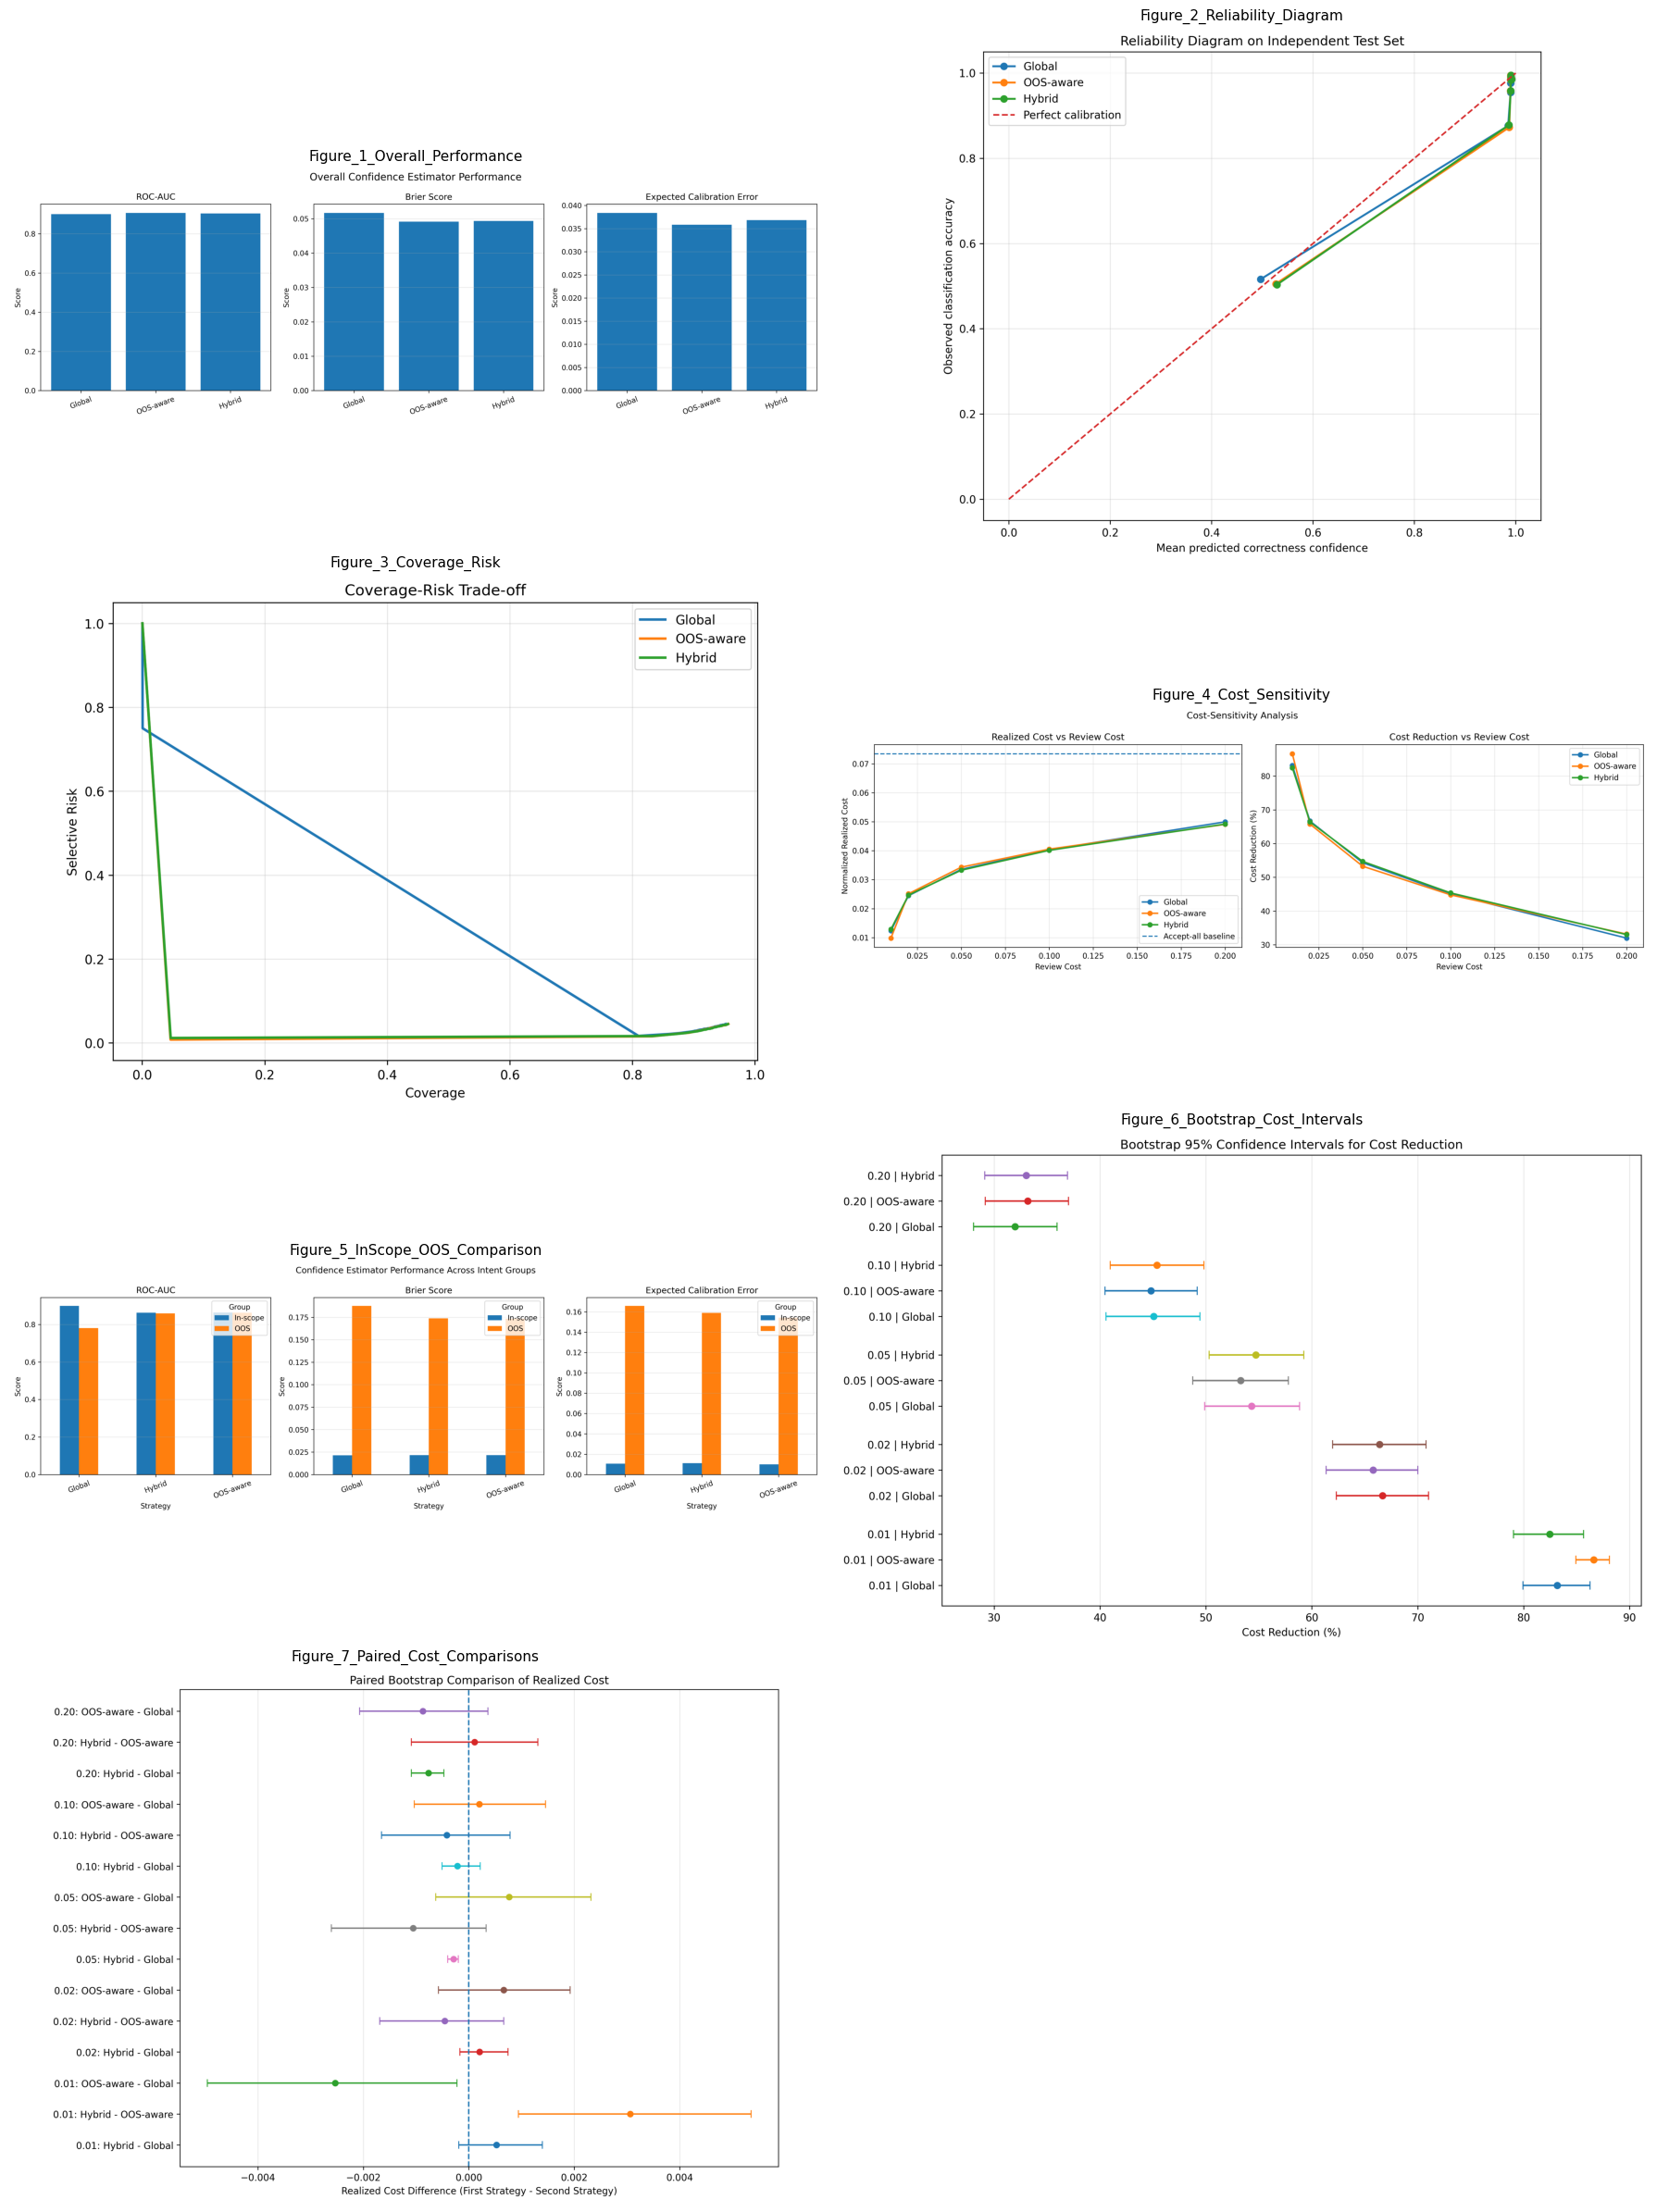


STEP 40A COMPLETED
Metadata saved: /content/CA_CSDL_step40_figure_metadata.csv
Figures displayed: 7 / 7


In [ ]:

# ============================================================
# STEP 40A: VISUAL INSPECTION OF SEVEN CA-CSDL FIGURES
# ============================================================

import os
import matplotlib.pyplot as plt
from PIL import Image
import pandas as pd

FIGURE_DIR = (
    "/content/CA_CSDL_Final_Publication_Package/Figures"
)

figure_names = [

    "Figure_1_Overall_Performance.png",

    "Figure_2_Reliability_Diagram.png",

    "Figure_3_Coverage_Risk.png",

    "Figure_4_Cost_Sensitivity.png",

    "Figure_5_InScope_OOS_Comparison.png",

    "Figure_6_Bootstrap_Cost_Intervals.png",

    "Figure_7_Paired_Cost_Comparisons.png"

]

# ------------------------------------------------------------
# 1. Verify image files and metadata
# ------------------------------------------------------------

metadata = []

for filename in figure_names:

    path = os.path.join(
        FIGURE_DIR,
        filename
    )

    if not os.path.exists(path):

        print("MISSING:", filename)
        continue

    img = Image.open(path)

    width, height = img.size

    dpi = img.info.get("dpi", None)

    metadata.append({

        "Figure": filename,

        "Width_pixels": width,

        "Height_pixels": height,

        "DPI": (
            round(dpi[0])
            if dpi else "Not recorded"
        ),

        "File_size_KB": round(
            os.path.getsize(path) / 1024,
            2
        )

    })

metadata_df = pd.DataFrame(metadata)

print("\nFIGURE IMAGE METADATA")

display(metadata_df)

# ------------------------------------------------------------
# 2. Display figures in two-column layout
# ------------------------------------------------------------

fig, axes = plt.subplots(
    4, 2,
    figsize=(18, 24)
)

axes = axes.flatten()

for i, filename in enumerate(figure_names):

    path = os.path.join(
        FIGURE_DIR,
        filename
    )

    if os.path.exists(path):

        img = Image.open(path)

        axes[i].imshow(img)

        axes[i].set_title(
            filename.replace(".png", ""),
            fontsize=11
        )

        axes[i].axis("off")

    else:

        axes[i].text(
            0.5, 0.5,
            "Figure missing",
            ha="center",
            va="center"
        )

        axes[i].axis("off")

# Hide unused eighth subplot

axes[7].axis("off")

plt.tight_layout()

plt.show()

# ------------------------------------------------------------
# 3. Save figure metadata
# ------------------------------------------------------------

metadata_path = (
    "/content/CA_CSDL_step40_figure_metadata.csv"
)

metadata_df.to_csv(
    metadata_path,
    index=False
)

print("\nSTEP 40A COMPLETED")

print("Metadata saved:", metadata_path)

print(
    "Figures displayed:",
    len(metadata_df),
    "/ 7"
)


In [ ]:

# ============================================================
# STEP 40B: STANDARDIZED ECE REFERENCE TABLE
# ============================================================

import pandas as pd

ece_reference = pd.DataFrame([

    ["Overall", "Global", 0.038383],
    ["Overall", "OOS-aware", 0.035826],
    ["Overall", "Hybrid", 0.036814],

    ["In-scope", "Global", 0.010678],
    ["In-scope", "OOS-aware", 0.010000],
    ["In-scope", "Hybrid", 0.011220],

    ["OOS", "Global", 0.165831],
    ["OOS", "OOS-aware", 0.154321],
    ["OOS", "Hybrid", 0.159016]

], columns=[
    "Evaluation_Group",
    "Strategy",
    "ECE_15_equal_width"
])

print("STANDARDIZED ECE VALUES")

display(ece_reference)

ece_reference.to_csv(
    "/content/CA_CSDL_step40_standardized_ECE.csv",
    index=False
)

print("ECE reference table saved.")


STANDARDIZED ECE VALUES


,Evaluation_Group,Strategy,ECE_15_equal_width
0,Overall,Global,0.038383
1,Overall,OOS-aware,0.035826
2,Overall,Hybrid,0.036814
3,In-scope,Global,0.010678
4,In-scope,OOS-aware,0.010000
5,In-scope,Hybrid,0.011220
6,OOS,Global,0.165831
7,OOS,OOS-aware,0.154321
8,OOS,Hybrid,0.159016


ECE reference table saved.



FIGURE 1: Figure_1_Overall_Performance.png


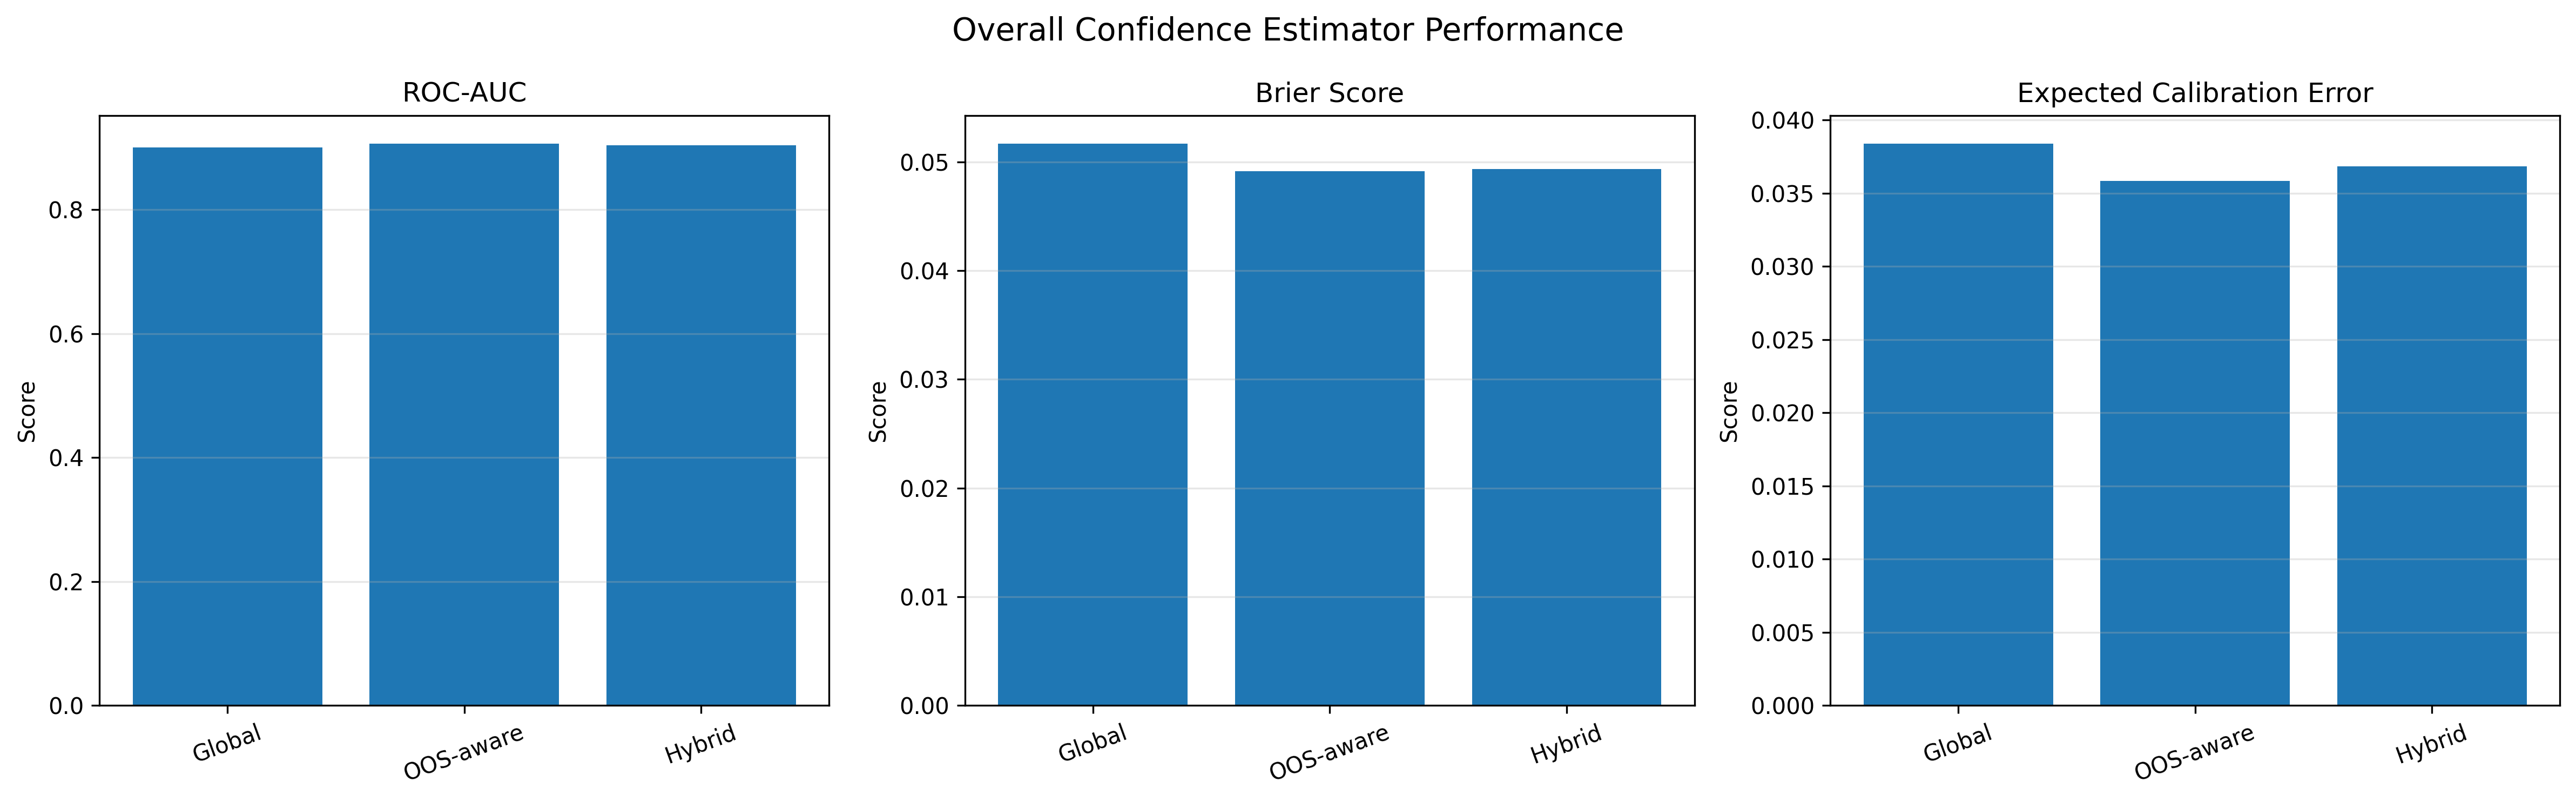


FIGURE 2: Figure_2_Reliability_Diagram.png


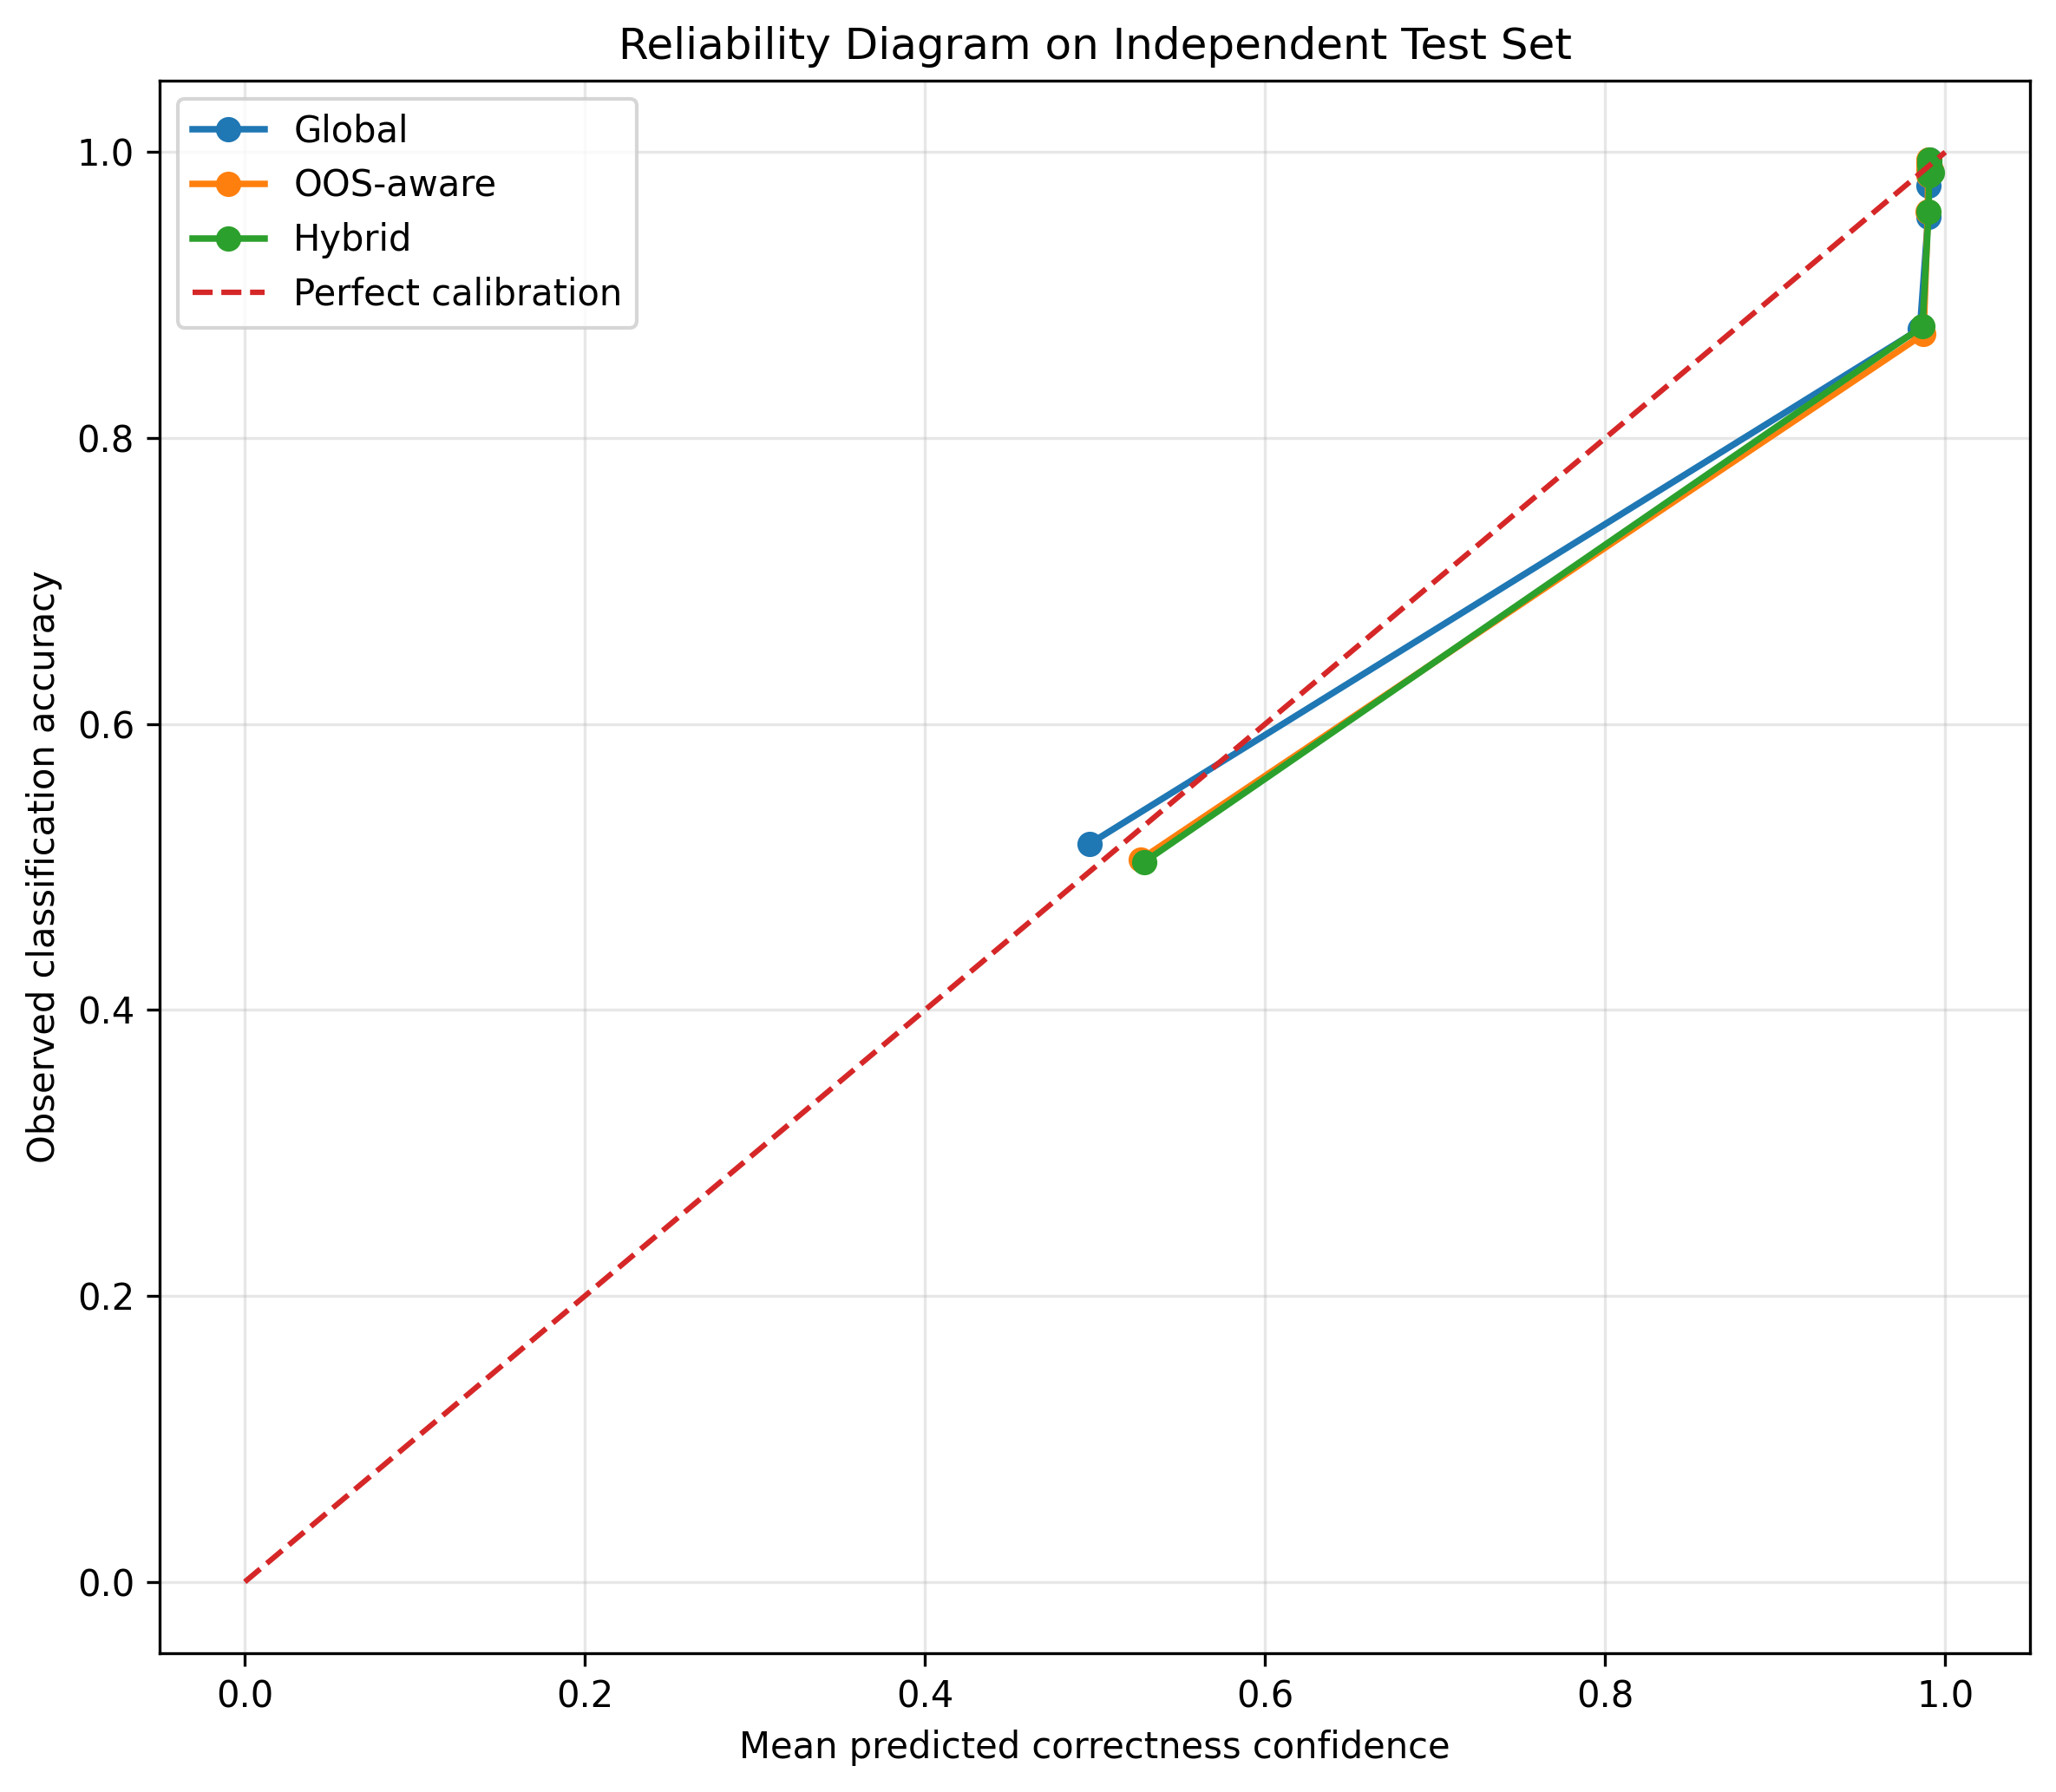


FIGURE 3: Figure_3_Coverage_Risk.png


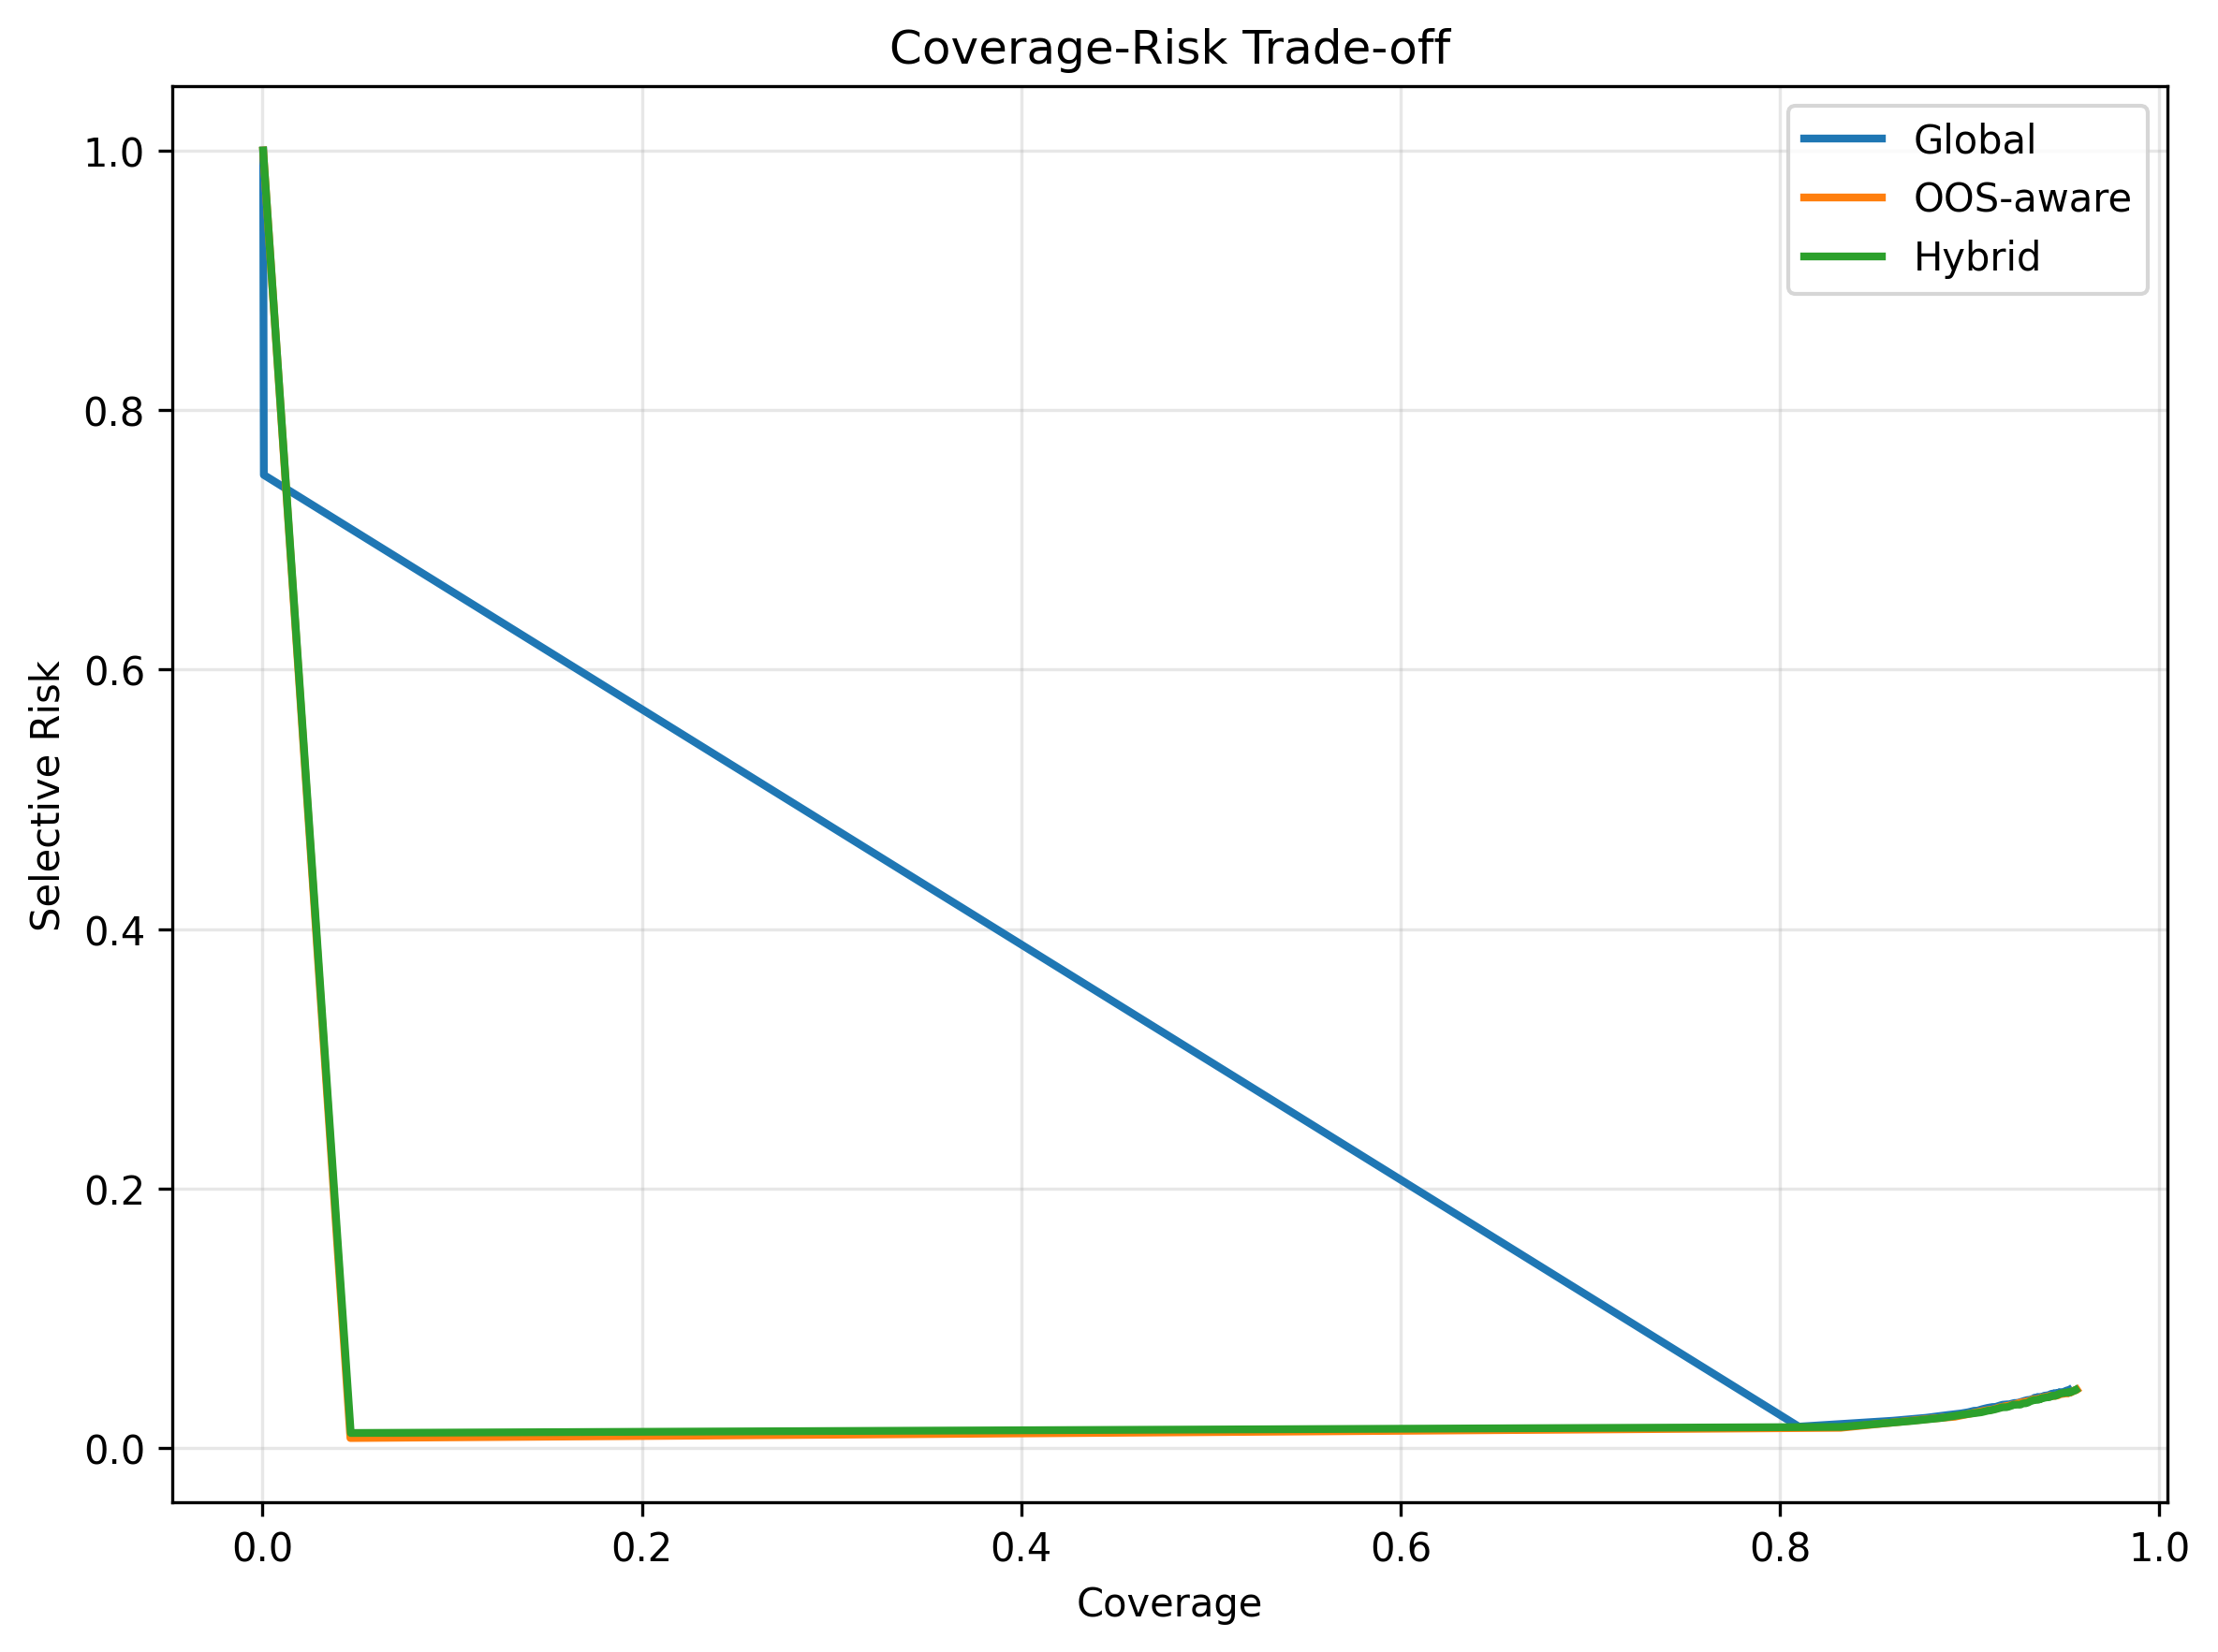


FIGURE 4: Figure_4_Cost_Sensitivity.png


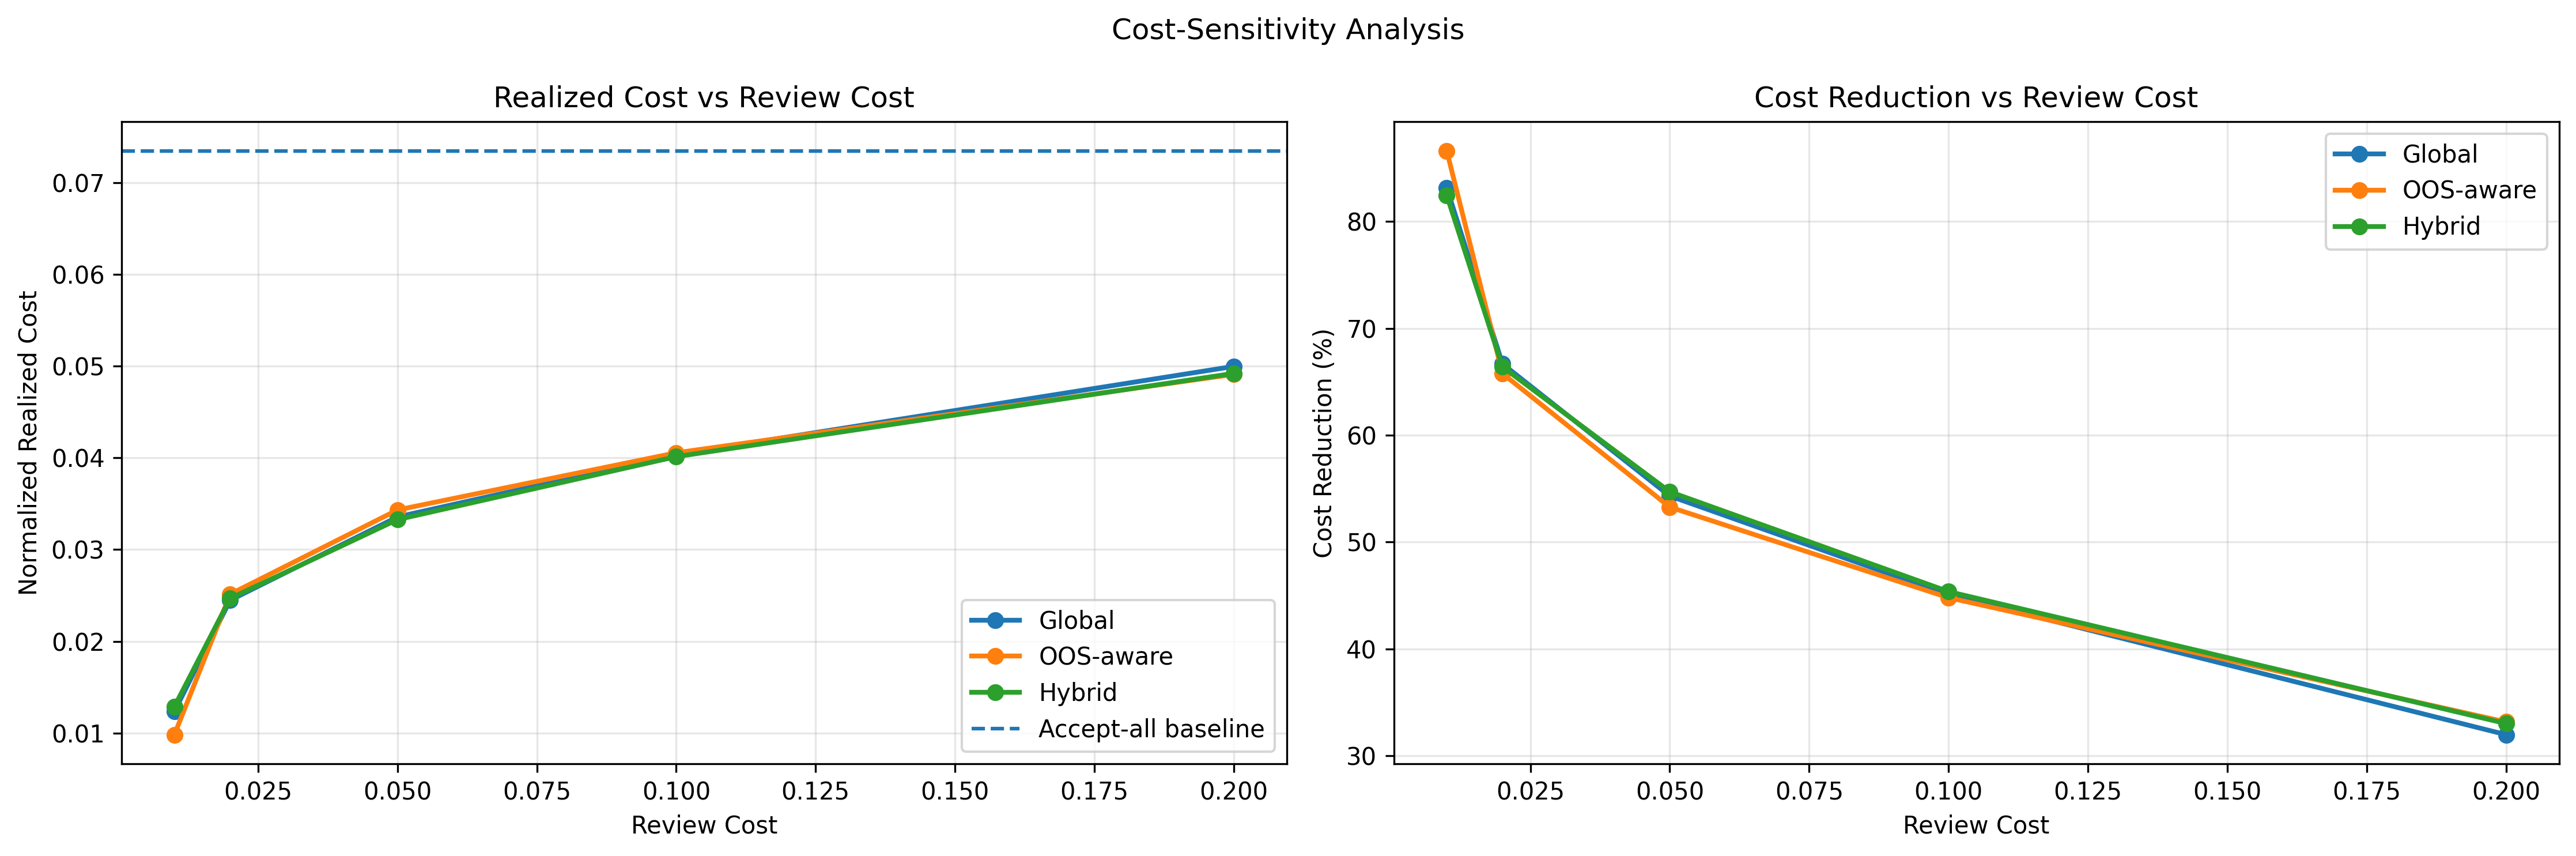


FIGURE 5: Figure_5_InScope_OOS_Comparison.png


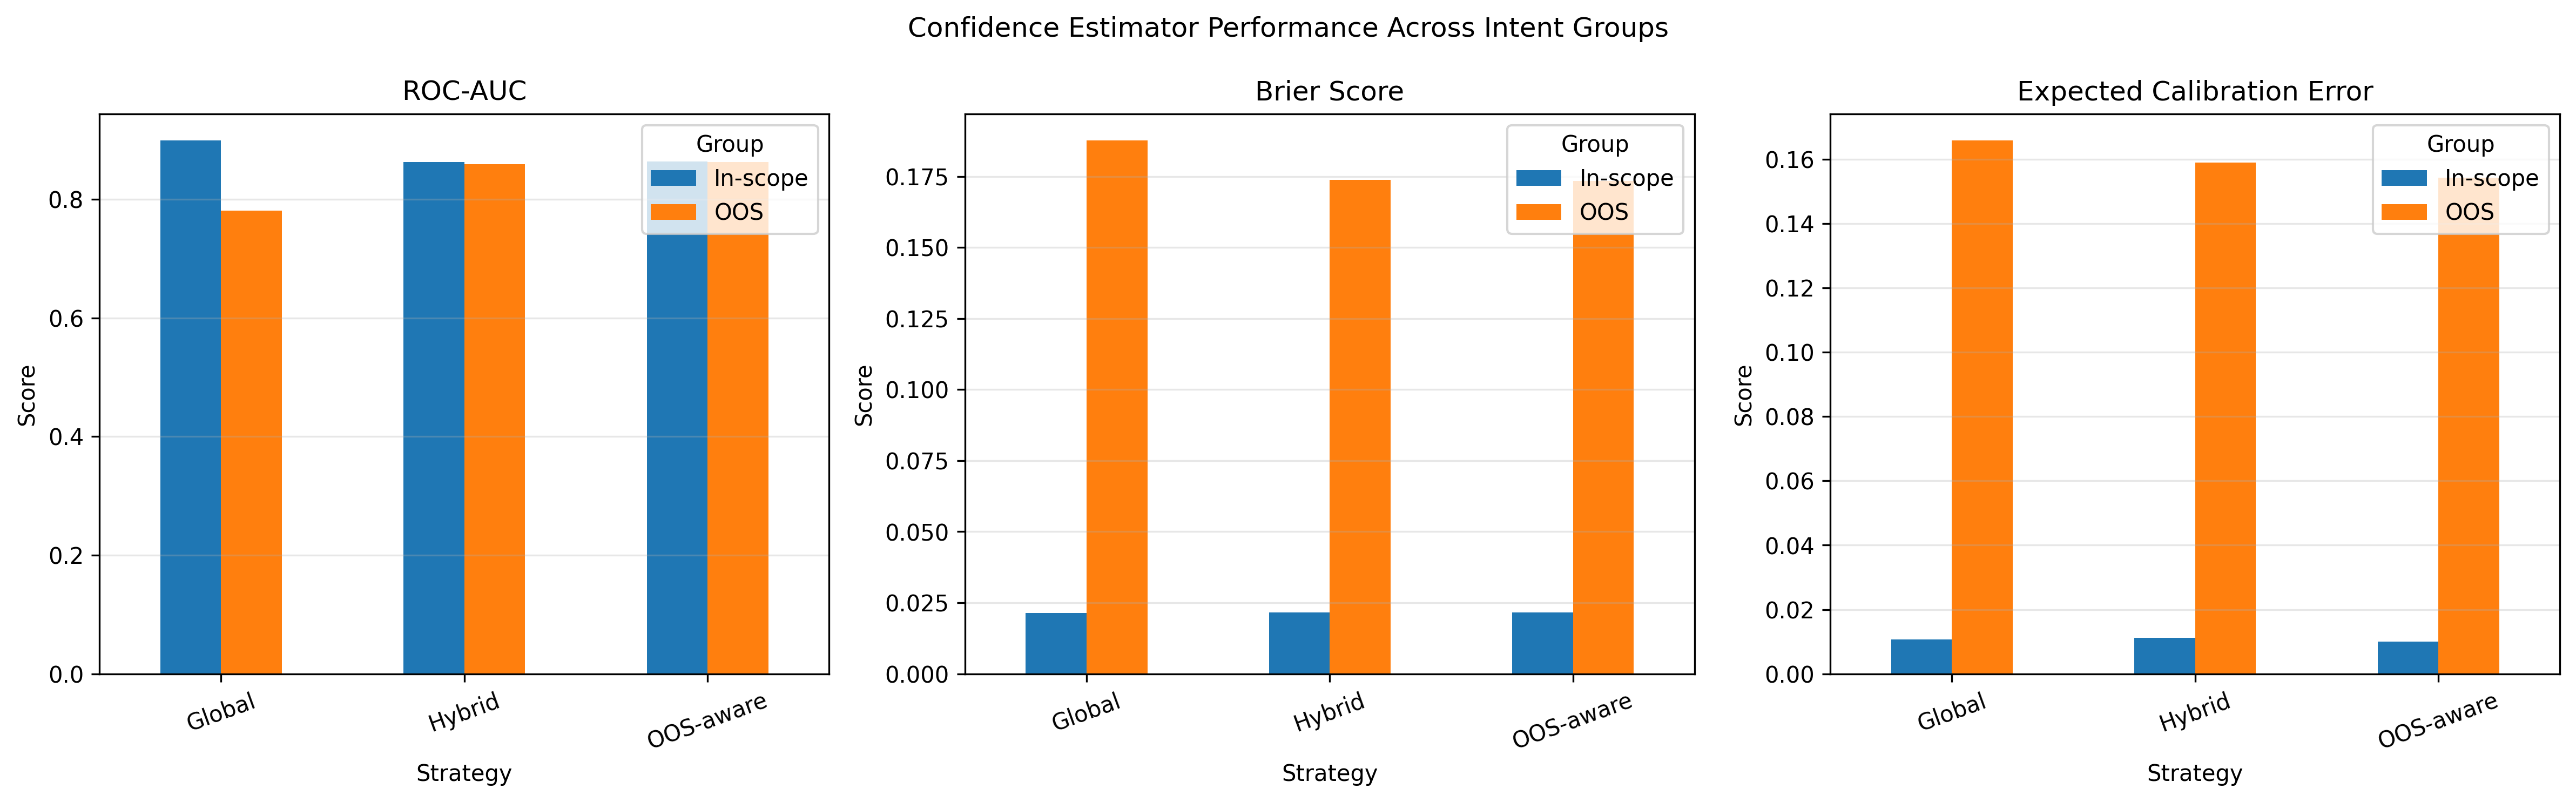


FIGURE 6: Figure_6_Bootstrap_Cost_Intervals.png


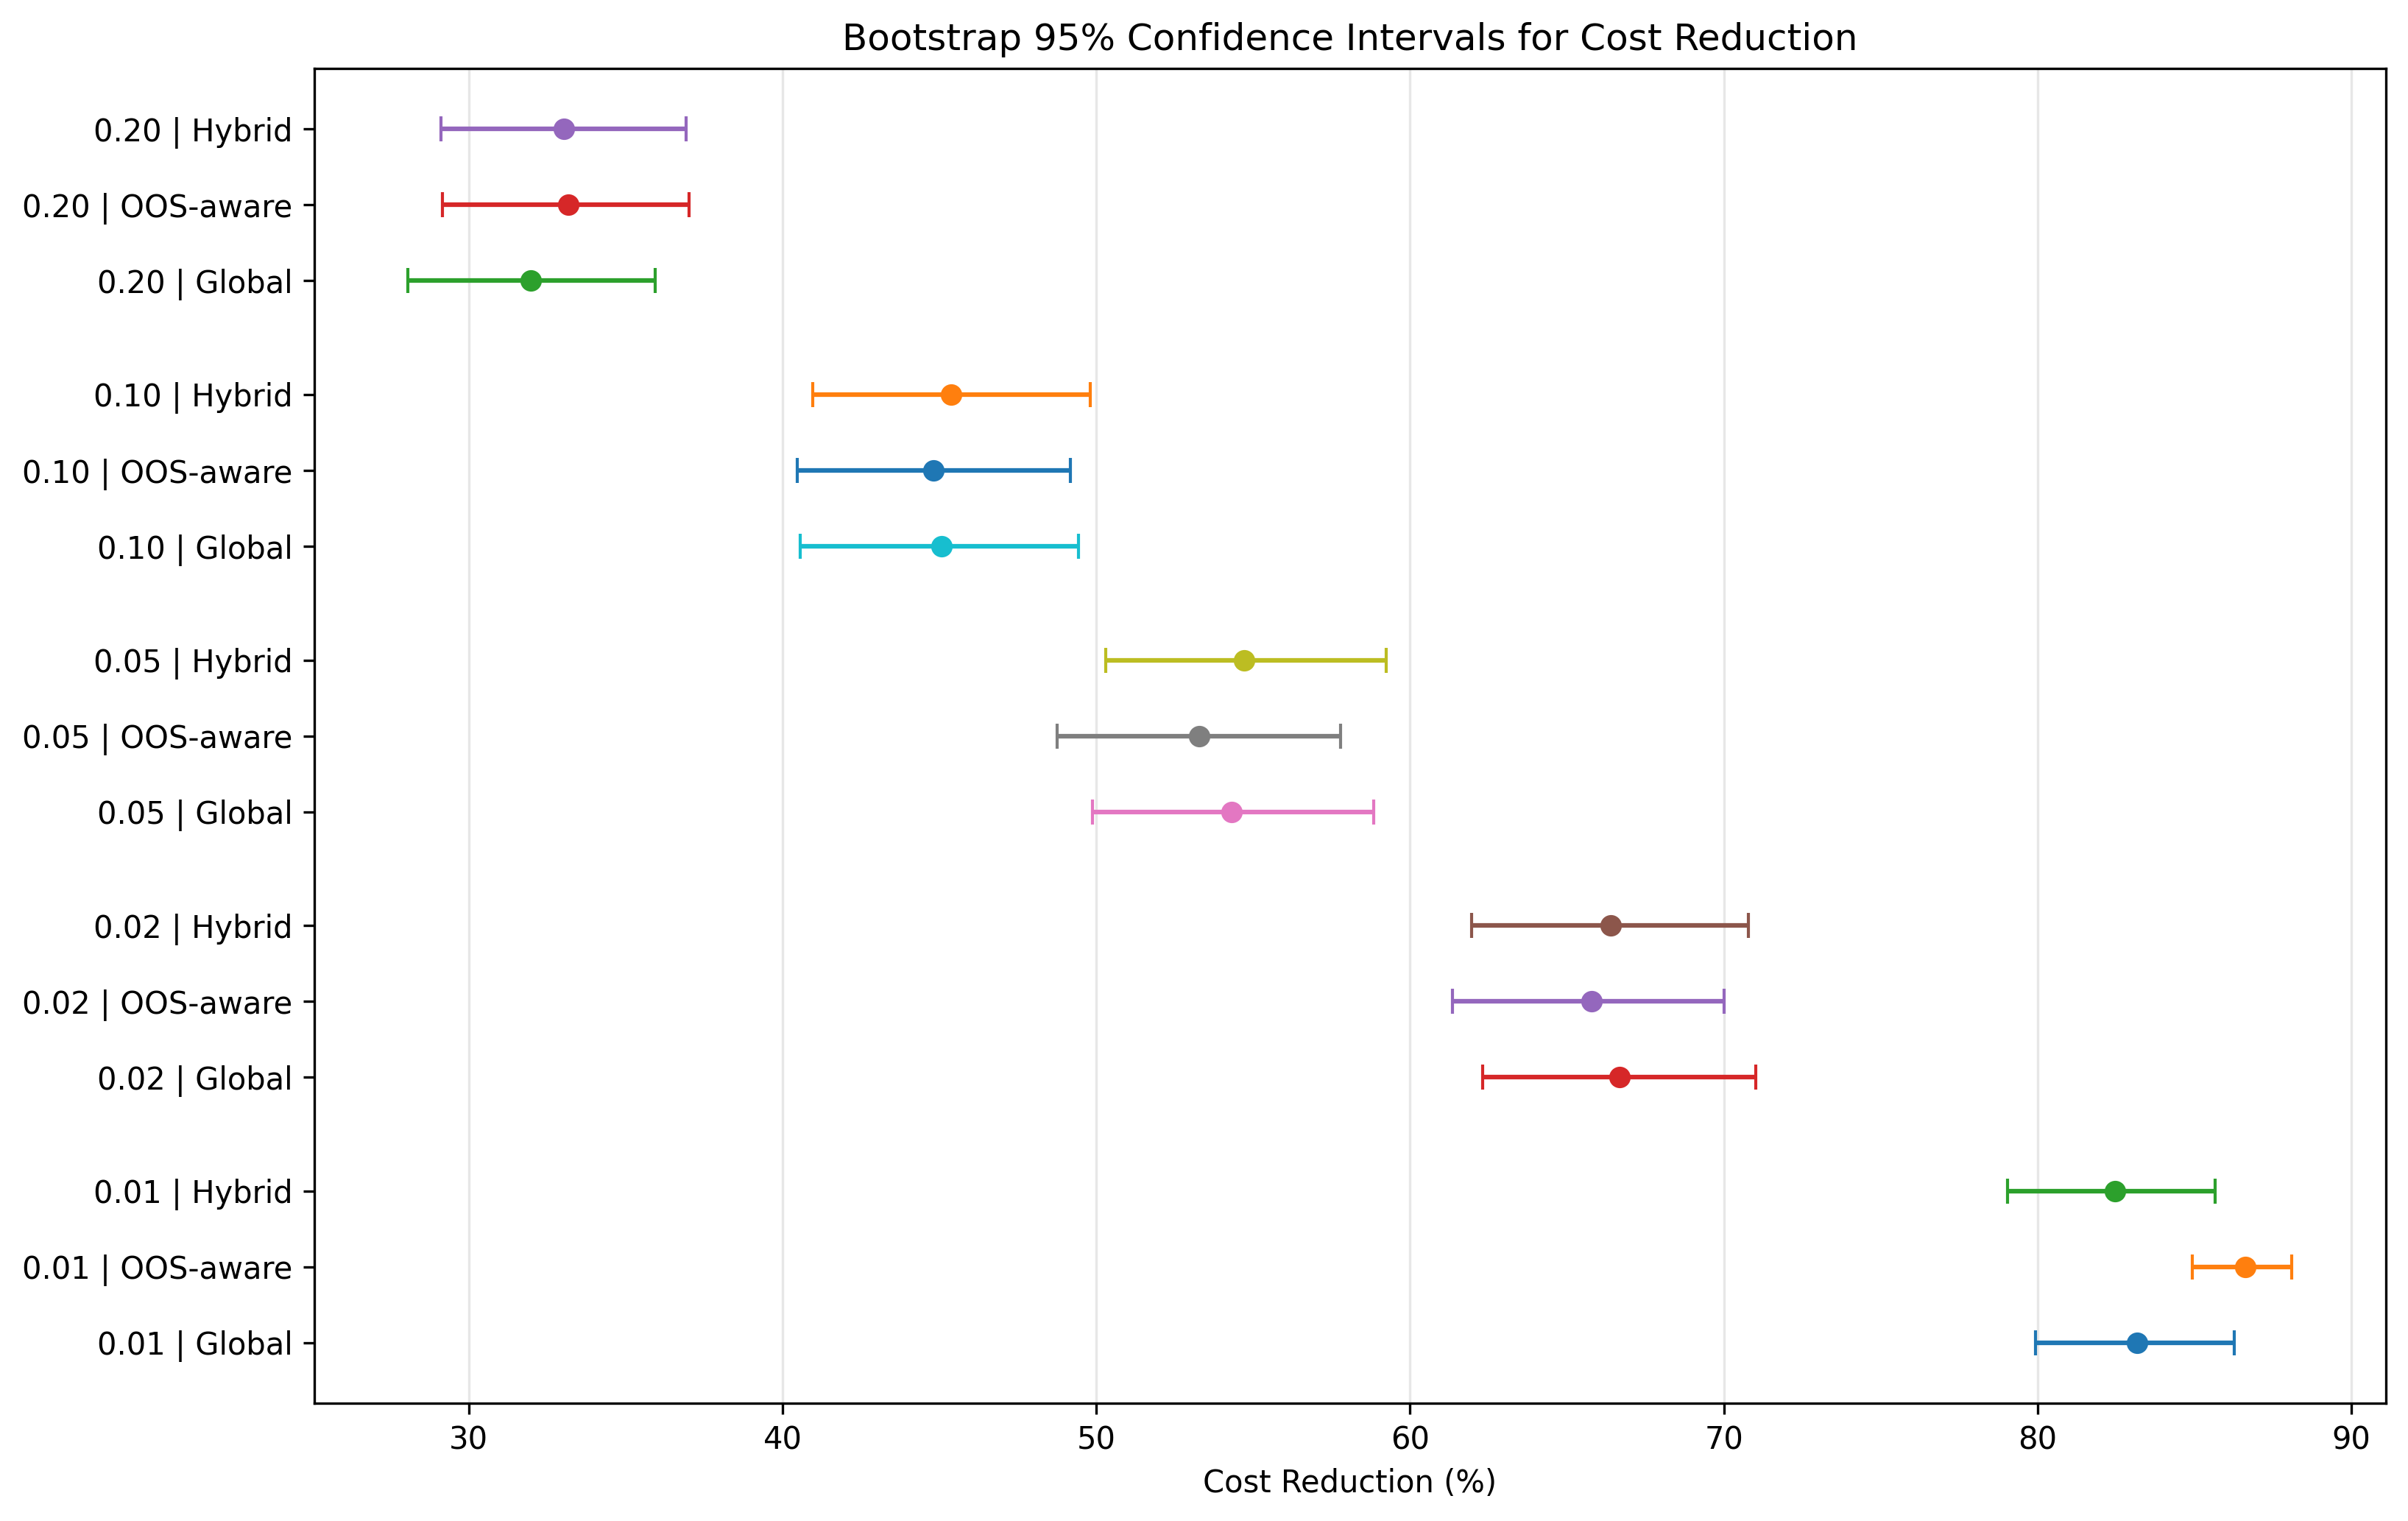


FIGURE 7: Figure_7_Paired_Cost_Comparisons.png


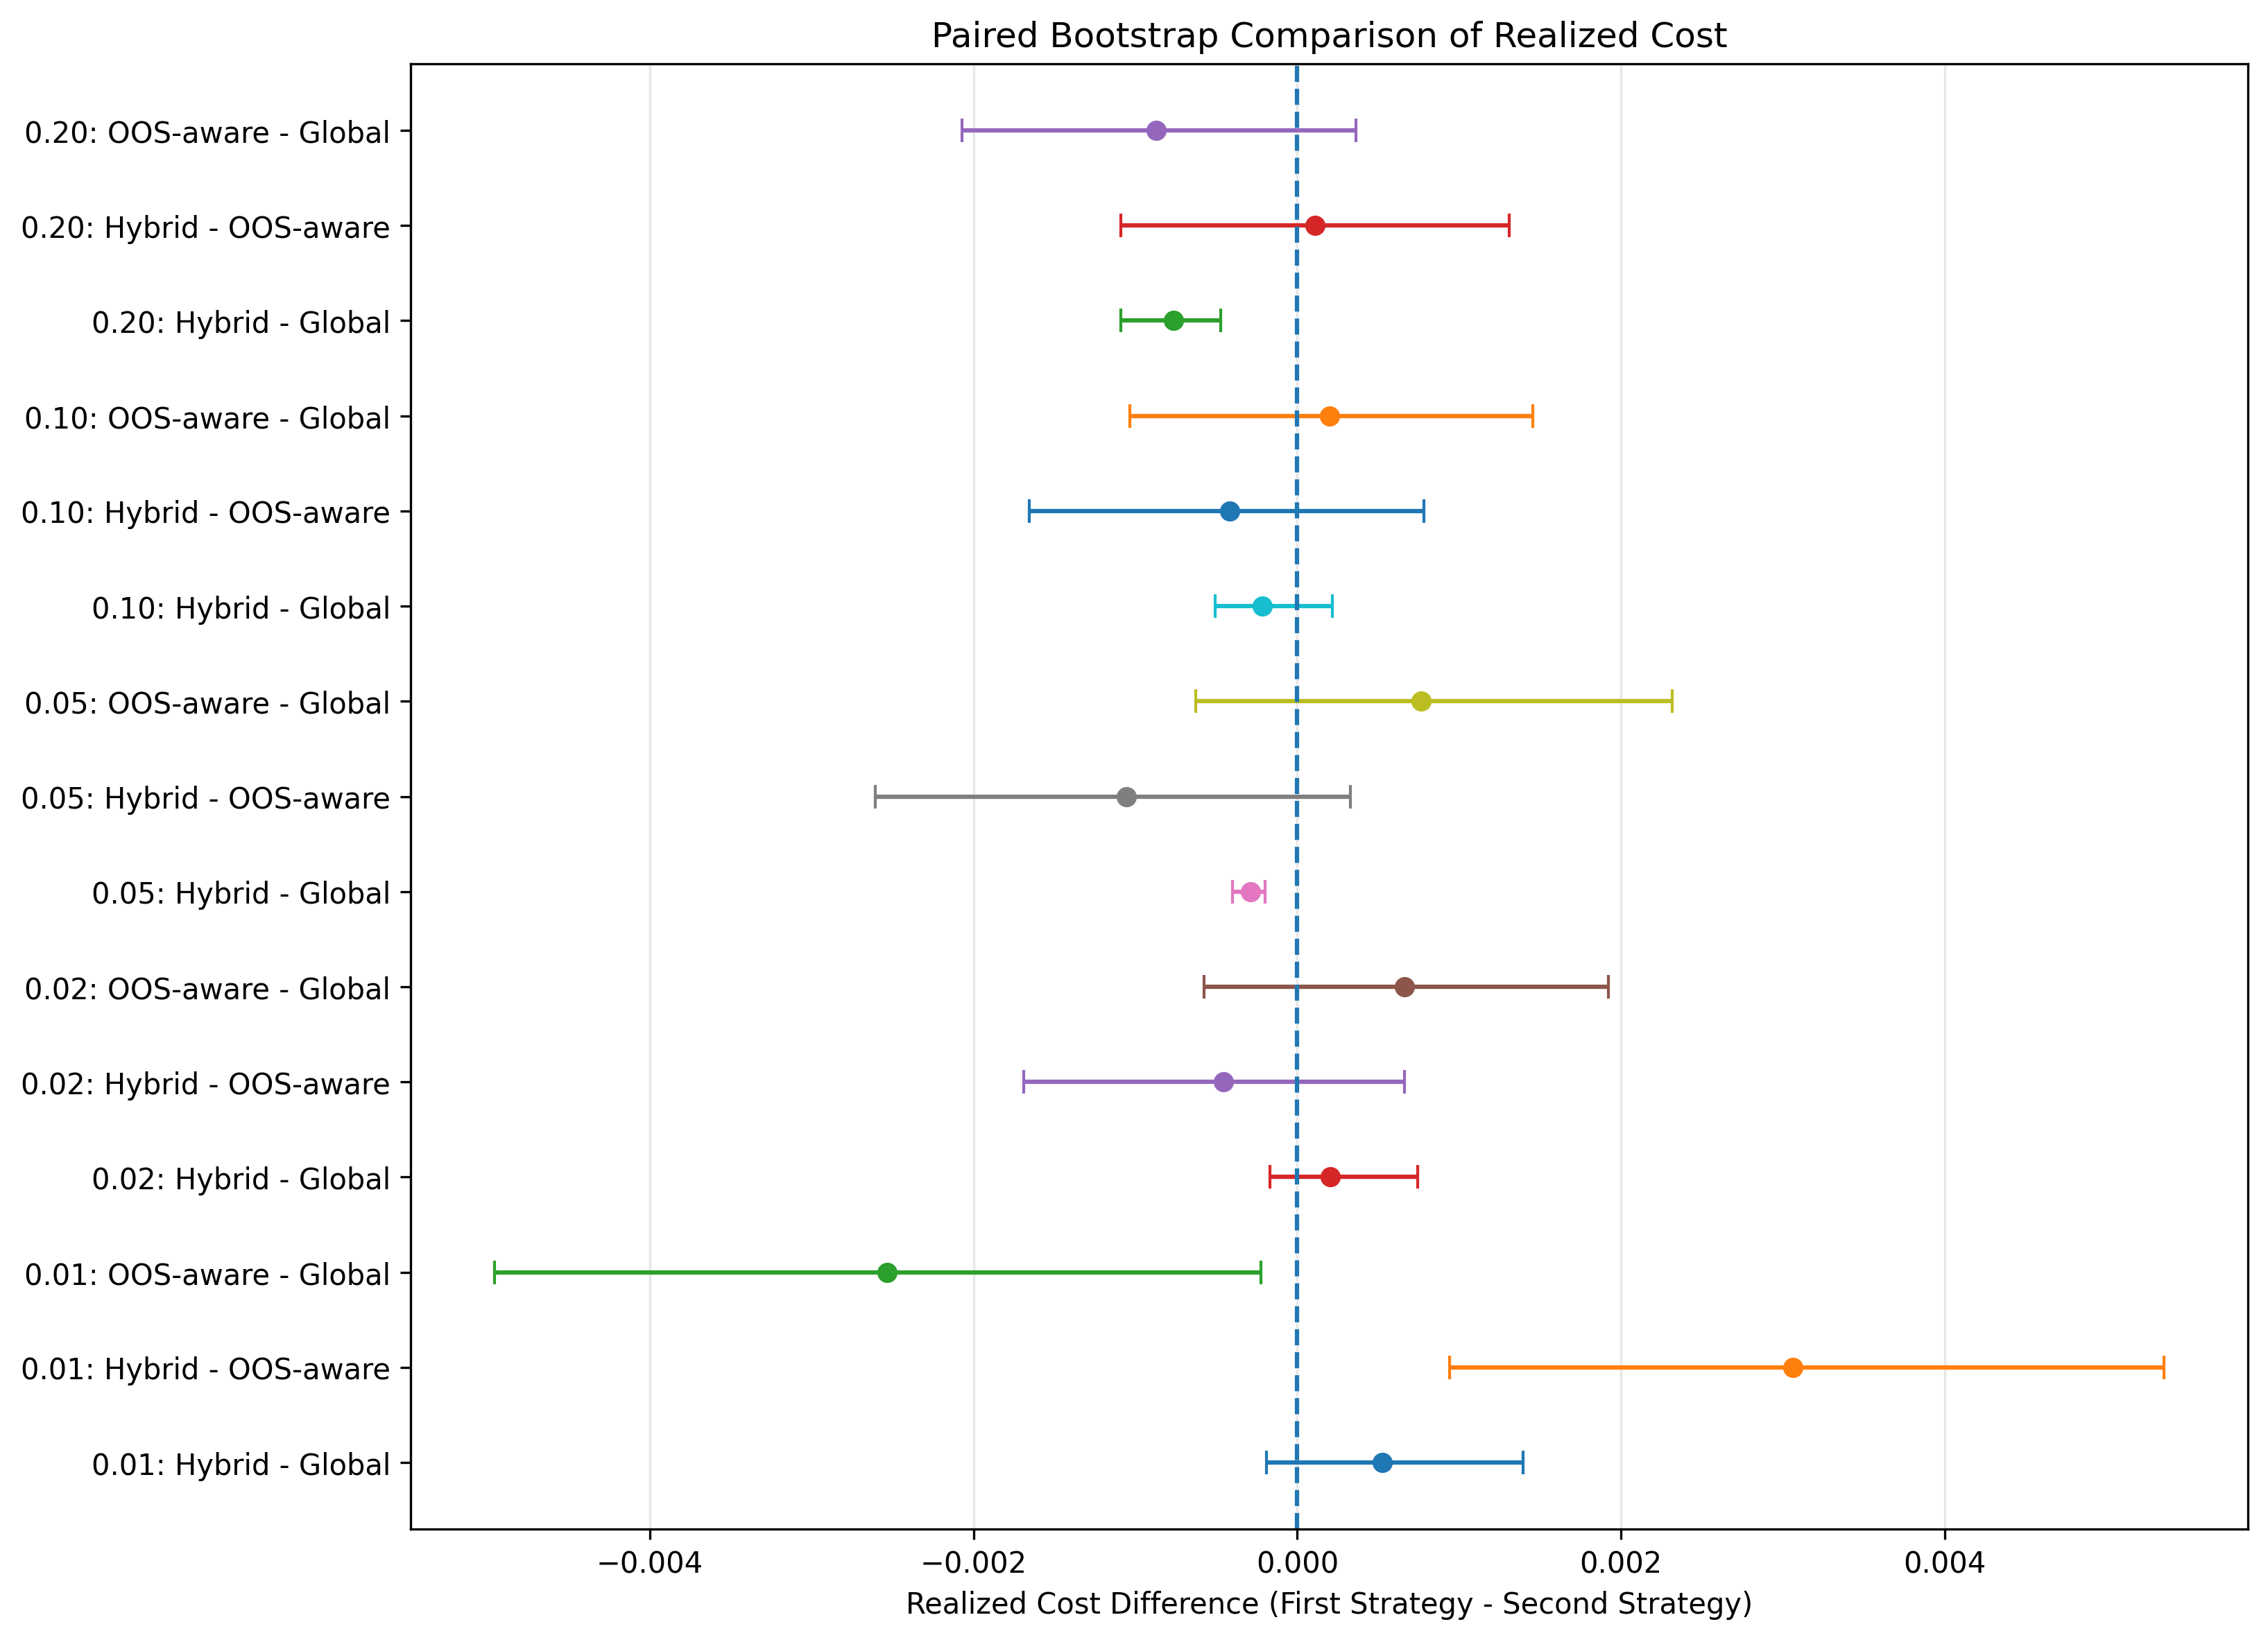

In [ ]:

# STEP 40B: DISPLAY EACH PUBLICATION FIGURE

from PIL import Image
from IPython.display import display

FIGURE_DIR = (
    "/content/CA_CSDL_Final_Publication_Package/Figures"
)

figure_names = [
    "Figure_1_Overall_Performance.png",
    "Figure_2_Reliability_Diagram.png",
    "Figure_3_Coverage_Risk.png",
    "Figure_4_Cost_Sensitivity.png",
    "Figure_5_InScope_OOS_Comparison.png",
    "Figure_6_Bootstrap_Cost_Intervals.png",
    "Figure_7_Paired_Cost_Comparisons.png"
]

for i, filename in enumerate(figure_names, 1):

    print(f"\nFIGURE {i}: {filename}")

    image_path = f"{FIGURE_DIR}/{filename}"

    img = Image.open(image_path)

    display(img)

